# Rational RLCG Model for Multilayer Resistive-Wall Impedances

**Objective:** Construct a physics-based transmission-line network from material layers, calculate its input surface impedance, and extract poles and residues without fitting. **Initial benchmark:** A homogeneous copper half-space approximated by a finite, nonuniform RL network terminated by a PEC boundary.

**Convention:** Laplace variable $s$, evaluated along $s=j\omega$. $V=E_t$ and $I=H_t$ are *field variables*, not physical terminal voltage and current. The distributed parameters $L'=\mu$, $G'=\sigma$, and $C'=\varepsilon$ apply to this field normalization. All surface impedances are in ohms.

**Scope:** Planar transmission-line approximation with initially frequency-independent, isotropic materials. More general material laws supported by PyTLWall will require additional rational models.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import dataclass
from scipy.constants import mu_0, epsilon_0
from scipy.linalg import eigh

try:
    import pytlwall
    PYTLWALL_AVAILABLE = True
    print("PyTLWall found:", getattr(pytlwall, "__file__", ""))
except ImportError:
    PYTLWALL_AVAILABLE = False
    print("PyTLWall is not installed; the analytical benchmark remains available.")

PyTLWall found: D:\Lossy_Wall_Pole_Residuum\TLWallNew\pytlwall\__init__.py


## 1. General Material and Layer Model

**Finite layers** and the **semi-infinite substrate** are represented separately. This allows us to import arbitrary PyTLWall configurations later. The substrate is initially truncated at a finite depth $D$. Each finite layer can subsequently have its own mesh and constitutive model.

In [2]:
@dataclass(frozen=True)
class Material:
    name: str
    sigma: float                 # S/m
    eps_r: float = 1.0
    mu_r: float = 1.0

    @property
    def mu(self): return mu_0 * self.mu_r
    @property
    def eps(self): return epsilon_0 * self.eps_r

@dataclass(frozen=True)
class FiniteLayer:
    material: Material
    thickness: float            # m

@dataclass(frozen=True)
class WallStack:
    finite_layers: tuple[FiniteLayer, ...]
    substrate: Material          # analytically semi-infinite
    pipe_radius: float          # m
    pipe_length: float = 1.0    # m

copper = Material("Copper", sigma=5.8e7)
wall = WallStack(finite_layers=(), substrate=copper, pipe_radius=0.02)
f = np.geomspace(1e3, 1e9, 601)
s = 1j * 2*np.pi*f

## 2. Analytical Reference for a Homogeneous Half-Space

The characteristic impedance and propagation constant are

$$Z_c(s)=\sqrt{\frac{s\mu}{\sigma+s\varepsilon}},\qquad \gamma(s)=\sqrt{s\mu(\sigma+s\varepsilon)}.$$

The good-conductor approximation is $Z_c(s)\approx\sqrt{s\mu/\sigma}$.

In [3]:
def intrinsic_impedance(s, material):
    return np.sqrt(s * material.mu / (material.sigma + s * material.eps))

def propagation_constant(s, material):
    return np.sqrt(s * material.mu * (material.sigma + s * material.eps))

def skin_depth(f, material):
    return np.sqrt(2/(2*np.pi*np.asarray(f)*material.mu*material.sigma))

z_exact = intrinsic_impedance(s, wall.substrate)
print("Skin depth at fmin = %.3g m; at fmax = %.3g m" % (skin_depth(f[0], copper), skin_depth(f[-1], copper)))

Skin depth at fmin = 0.00209 m; at fmax = 2.09e-06 m


## 3. Geometrically Graded Mesh (Prepared for Multiple Finite Layers)

Choose $D=n_\delta\,\delta(f_{\min})$ and $\Delta x_0=\delta(f_{\max})/m$. The geometric growth ratio $q$ is then determined from the prescribed number of cells. The resulting accuracy must be **verified numerically**.

N=100, D=14.629 mm, dx_min=0.348 µm, dx_max=1149.836 µm


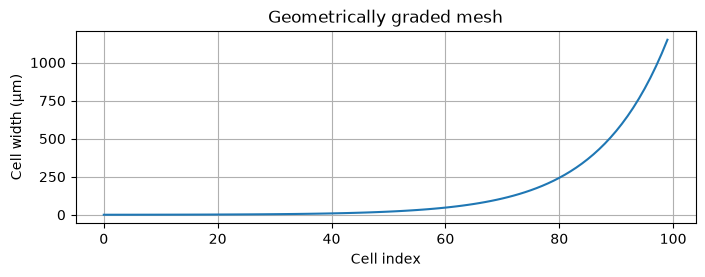

In [4]:
from scipy.optimize import brentq

def geometric_widths(total_depth, first_width, n):
    if n < 1 or total_depth <= 0 or first_width <= 0:
        raise ValueError("Invalid mesh parameters")
    if n == 1:
        return np.array([total_depth])
    if total_depth < n*first_width:
        raise ValueError("Total depth is too small for growing cells; reduce N or the first cell width")
    if np.isclose(total_depth, n*first_width):
        return np.full(n, total_depth/n)
    def depth(q):
        return first_width * np.sum(q**np.arange(n))
    upper = 1.2
    while depth(upper) < total_depth:
        upper *= 1.5
    q = brentq(lambda q: depth(q)-total_depth, 1, upper)
    dx = first_width*q**np.arange(n)
    return dx * (total_depth/dx.sum())

def substrate_mesh(material, frequencies, n=100, cells_per_skin=6, depth_factor=7):
    dmin = skin_depth(np.max(frequencies), material)
    dmax = skin_depth(np.min(frequencies), material)
    return geometric_widths(depth_factor*dmax, dmin/cells_per_skin, n)

dx = substrate_mesh(copper, f, n=100)
x_edges = np.r_[0, np.cumsum(dx)]
print(f"N={len(dx)}, D={x_edges[-1]*1e3:.3f} mm, dx_min={dx.min()*1e6:.3f} µm, dx_max={dx.max()*1e6:.3f} µm")
fig, ax = plt.subplots(figsize=(8,2.5))
ax.plot(np.arange(len(dx)), dx*1e6)
ax.set(xlabel="Cell index", ylabel="Cell width (µm)", title="Geometrically graded mesh")
ax.grid(True); plt.show()

## 4. General Nonuniform Network: Direct Frequency-Domain Solution

Nodes are located at $x_0=0,\ldots,x_{N-1}$, with a PEC termination at $x_N=D$. Conductance and capacitance are distributed over **dual control volumes**: $w_0=\Delta x_0/2$ and $w_i=(\Delta x_{i-1}+\Delta x_i)/2$. Inductors connect adjacent nodes or the final node to the outer PEC termination. This avoids incorrectly assigning the entire cell shunt to only one endpoint.

$$[G+sC+B(sL)^{-1}B^T]v=e_0 I_{\mathrm{port}},\qquad Z_{\mathrm{in}}=v_0/I_{\mathrm{port}}.$$

Spatially varying material coefficients make this formulation suitable for multilayer extensions.

In [5]:
def assemble_network(dx, materials):
    """One Material object per spatial segment dx[k]."""
    dx = np.asarray(dx, float)
    n = len(dx)
    if len(materials) != n: raise ValueError("One material is required per segment")
    L = np.array([m.mu*d for m,d in zip(materials,dx)])
    G = np.zeros(n); C = np.zeros(n)
    for k,(d,m) in enumerate(zip(dx, materials)):
        # Split each cell shunt equally between its endpoints; eliminate the outer PEC node.
        G[k] += m.sigma*d/2
        C[k] += m.eps*d/2
        if k+1 < n:
            G[k+1] += m.sigma*d/2
            C[k+1] += m.eps*d/2
    B = np.eye(n)
    for k in range(n-1): B[k+1,k] = -1
    return L, G, C, B

def network_impedance(s, L, G, C, B):
    e = np.eye(len(L))[:,0]
    out = np.empty(np.size(s), complex)
    for k,sk in enumerate(np.atleast_1d(s)):
        Y = np.diag(G + sk*C) + (B/L) @ B.T / sk
        out[k] = np.linalg.solve(Y, e)[0]
    return out

L, G, C, B = assemble_network(dx, [copper]*len(dx))
z_rlcg = network_impedance(s, L, G, C, B)

## 5. Poles and Residues from the RL Eigenvalue Problem

For $C=0$, the network equations are $Gv+Bi=e_0 I$ and $sLi=B^Tv$, yielding

$$\dot i=-L^{-1}B^TG^{-1}Bi+L^{-1}B^TG^{-1}e_0 I.$$

With $K=B^TG^{-1}B$, solve the **symmetric generalized eigenvalue problem** $Ku=\lambda Lu$ and set $p_k=-\lambda_k$. The port impedance is

$$Z(s)=D_0+\sum_k\frac{r_k}{s-p_k},$$

where $D_0=e_0^TG^{-1}e_0$ and $r_k=-(u_k^TB^TG^{-1}e_0)^2$, with $u_k^TLu_k=1$.

The residues of this *impedance representation* are negative. This **does not imply a violation of passivity**: the underlying RL network is passive and its driving-point impedance is positive real.

In [6]:
def rl_poles_residues(L, G, B):
    if np.any(G <= 0): raise ValueError("All nodal conductances must be positive")
    e = np.eye(len(L))[:,0]
    K = B.T @ ((1/G)[:,None] * B)
    lam, U = eigh(K, np.diag(L))
    coupling = U.T @ (B.T @ (e/G))
    poles = -lam
    residues = -coupling**2
    direct = np.dot(e, e/G)
    return poles, residues, direct

def eval_pole_residue(s, poles, residues, direct):
    s = np.atleast_1d(s)
    return direct + np.sum(residues[None,:]/(s[:,None]-poles[None,:]), axis=1)

poles, residues, direct = rl_poles_residues(L, G, B)
z_pr = eval_pole_residue(s, poles, residues, direct)
print("Number of poles:", len(poles))
print("Maximum absolute difference, pole-residue vs. network:", np.max(np.abs(z_pr-z_rlcg)))

Number of poles: 100
Maximum absolute difference, pole-residue vs. network: 5.5944971430553446e-12


## 6. Reference Comparison and Conversion to Beam Impedance

For the initial experiment, compare the network against the analytical planar half-space impedance. Under Zannini's simplified longitudinal relation, $Z_\parallel/L=Z_s/(2\pi b)$. Cylindrical corrections and PyTLWall-specific options will be handled separately.

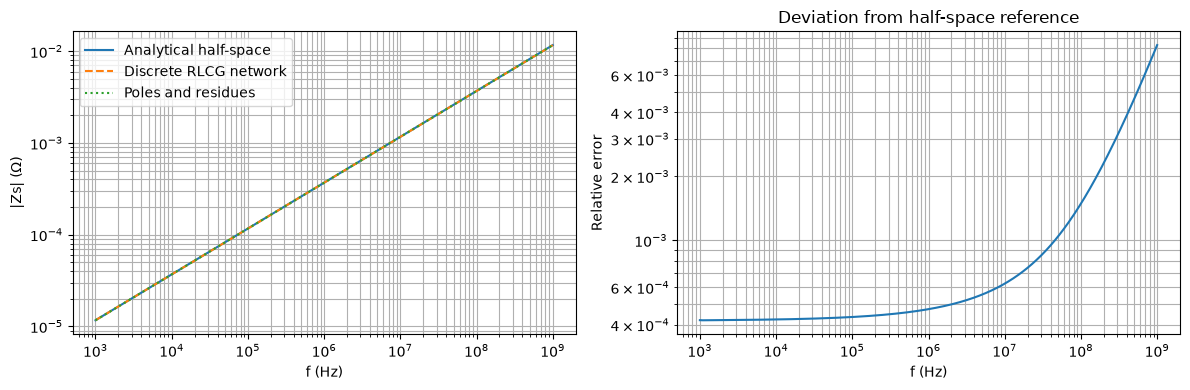

Maximum relative error: 0.008296728542225714
Maximum relative error, pole-residue vs. network: 4.804913433689847e-10


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12,4))
ax[0].loglog(f, np.abs(z_exact), label="Analytical half-space")
ax[0].loglog(f, np.abs(z_rlcg), '--', label="Discrete RLCG network")
ax[0].loglog(f, np.abs(z_pr), ':', label="Poles and residues")
ax[0].set(xlabel="f (Hz)", ylabel="|Zs| (Ω)")
ax[0].legend(); ax[0].grid(True, which='both')
relative_error = np.abs(z_rlcg-z_exact)/np.abs(z_exact)
ax[1].loglog(f, relative_error)
ax[1].set(xlabel="f (Hz)", ylabel="Relative error", title="Deviation from half-space reference")
ax[1].grid(True, which='both'); plt.tight_layout(); plt.show()
print("Maximum relative error:", relative_error.max())
print("Maximum relative error, pole-residue vs. network:", np.max(np.abs(z_pr-z_rlcg)/np.abs(z_rlcg)))
Zlong_per_m = z_pr/(2*np.pi*wall.pipe_radius)

## 7. PyTLWall Interface and Multilayer Extension

The public PyTLWall API provides `Layer`, `Chamber`, `Beam`, `Frequencies`, and `TlWall`. We will inspect the material attribute names and the `MATERIAL` termination option in the installed version **before** implementing automatic data transfer. Keeping the adapter separate isolates the network code from future PyTLWall API changes.

For multilayer walls, we will concatenate segments from all `FiniteLayer` objects and the discretized `substrate`. The `assemble_network` function already accepts a material per segment. At layer interfaces, we will also verify that the shunt allocation is consistent with the spatial discretization.

In [8]:
if PYTLWALL_AVAILABLE:
    from pytlwall import Beam, Frequencies, Layer, Chamber, TlWall
    import inspect
    for cls in (Layer, Chamber, TlWall):
        print(cls.__name__, inspect.signature(cls))
else:
    print("To install: git clone https://github.com/ImpedanCEI/TLWallNew.git")
    print("Then run inside the repository: python -m pip install -e .")

Layer (layer_type: 'str' = 'CW', thick_m: 'float' = 0.01, muinf_Hz: 'float' = 0.0, epsr: 'float' = 1.0, sigmaDC: 'float' = 1000000.0, k_Hz: 'float' = inf, tau: 'float' = 0.0, RQ: 'float' = 0.0, freq_Hz: 'Optional[Sequence[float]]' = None, boundary: 'bool' = False) -> 'None'
Chamber (pipe_len_m: float = 1.0, pipe_rad_m: float = 0.01, pipe_hor_m: Optional[float] = None, pipe_ver_m: Optional[float] = None, chamber_shape: str = 'CIRCULAR', betax: float = 1.0, betay: float = 1.0, layers: Optional[List] = None, component_name: str = 'el')
TlWall (chamber, beam, frequencies, accuracy_factor: float = 0.3)


## Next Steps

1. Benchmark against PyTLWall with explicitly matched boundary conditions and normalization.
2. Add arbitrary finite layers to `assemble_network`.
3. Include displacement current $C$ in the generalized RLCG state-space eigenvalue problem.
4. Apply passivity-preserving model-order reduction rather than selecting poles solely by $|r_k|$.
5. Represent frequency-dependent material laws using passive rational submodels.

**Current limitation:** This prototype extracts poles from an *RL* diffusion model ($C=0$ in the eigenvalue analysis), although $C$ is included in the direct frequency-domain network calculation. For copper between 1 kHz and 1 GHz, neglecting displacement current in the pole extraction is an excellent approximation. A full RLCG pole extraction will be added separately.

---
## 8. Multilayer benchmark: copper coating on stainless steel

This benchmark follows the **material values and geometry** in PyTLWall's documented *Example 3: Multi-layer Coating*: 50 µm copper (5.96e7 S/m), 2 mm stainless steel (1.45e6 S/m), circular pipe of radius 22 mm, and an LHC-like beam. It is a **simplified LHC-style benchmark**, not a verified as-built LHC beam-screen specification.

We deliberately compare three distinct models:

1. **Continuous planar TL:** exact recursion through the finite copper coating, terminated by the *analytical semi-infinite steel* impedance.
2. **Discrete RLCG network:** copper and steel represented by finite cells; the outermost steel node has a PEC termination at sufficiently large depth.
3. **PyTLWall:** the package's own *beam coupling impedance*, which can include cylindrical geometry, finite substrate thickness, its selected outer boundary, and additional corrections. It must **not** be identified with the planar TL surface impedance without checking these differences.

The first two models use identical planar physics. The PyTLWall comparison is shown separately and is explicitly labeled as a beam-impedance comparison. The pole-residue representation currently uses the **RL approximation** (`C = 0`); the direct network calculation can include capacitance.

In [9]:
# Source: PyTLWall documentation, Example 3 (illustrative LHC-style geometry).
cu_coating = Material("Copper coating", sigma=5.96e7)
steel = Material("Stainless steel", sigma=1.45e6)
benchmark = WallStack(
    finite_layers=(FiniteLayer(cu_coating, thickness=50e-6),),
    substrate=steel,
    pipe_radius=0.022,
    pipe_length=1.0,
)
f_multi = np.geomspace(1e3, 1e9, 251)
s_multi = 2j * np.pi * f_multi
print("Benchmark:", benchmark)


Benchmark: WallStack(finite_layers=(FiniteLayer(material=Material(name='Copper coating', sigma=59600000.0, eps_r=1.0, mu_r=1.0), thickness=5e-05),), substrate=Material(name='Stainless steel', sigma=1450000.0, eps_r=1.0, mu_r=1.0), pipe_radius=0.022, pipe_length=1.0)


### 8.1 Continuous multilayer transmission-line reference

For each finite planar layer, the input impedance is

$$Z_{\mathrm{in}}=Z_c\frac{Z_L+Z_c\tanh(\gamma d)}{Z_c+Z_L\tanh(\gamma d)}.$$

The outermost steel region is analytically semi-infinite, so $Z_L=Z_{c,\mathrm{steel}}$. Recursion proceeds from the outside towards the vacuum interface. This comparison isolates the error of our spatial discretization.

In [10]:
def planar_multilayer_impedance(s_values, stack):
    """Planar TL impedance of finite layers backed by a semi-infinite substrate."""
    s_values = np.atleast_1d(np.asarray(s_values, complex))
    z = intrinsic_impedance(s_values, stack.substrate)
    for layer in reversed(stack.finite_layers):
        zc = intrinsic_impedance(s_values, layer.material)
        gd = propagation_constant(s_values, layer.material) * layer.thickness
        t = np.tanh(gd)
        z = zc * (z + zc * t) / (zc + z * t)
    return z

z_planar = planar_multilayer_impedance(s_multi, benchmark)


### 8.2 Multilayer spatial discretization

Finite layers have their **own meshes**, with material interfaces aligned exactly to cell boundaries. The semi-infinite steel backing is truncated at several skin depths corresponding to the lowest benchmark frequency. The mesh is refined towards the copper surface and at the copper/steel interface. This is a first mesh choice, not yet an optimized one.

Cells: 145; copper: 35; steel: 110
Truncated backing depth: 92.520 mm


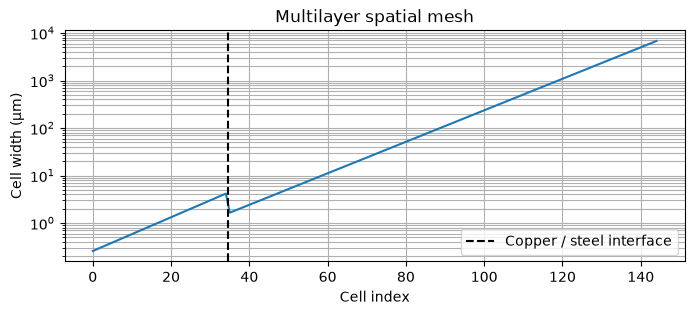

In [11]:
def multilayer_mesh(stack, frequencies, finite_cells=35, substrate_cells=110,
                    cells_per_skin=8, depth_factor=7):
    """Return segment widths, material per segment, and interface positions."""
    widths, materials, interfaces = [], [], [0.0]
    for layer in stack.finite_layers:
        # Resolve both the coating thickness and the smallest skin depth.
        first = min(layer.thickness / finite_cells,
                    skin_depth(np.max(frequencies), layer.material) / cells_per_skin)
        segment = geometric_widths(layer.thickness, first, finite_cells)
        widths.extend(segment)
        materials.extend([layer.material] * len(segment))
        interfaces.append(interfaces[-1] + layer.thickness)
    backing = substrate_mesh(stack.substrate, frequencies,
                             n=substrate_cells,
                             cells_per_skin=cells_per_skin,
                             depth_factor=depth_factor)
    widths.extend(backing)
    materials.extend([stack.substrate] * len(backing))
    interfaces.append(interfaces[-1] + np.sum(backing))
    return np.asarray(widths), materials, np.asarray(interfaces)

multi_dx, multi_materials, interfaces = multilayer_mesh(benchmark, f_multi)
L_multi, G_multi, C_multi, B_multi = assemble_network(multi_dx, multi_materials)
print(f"Cells: {len(multi_dx)}; copper: {sum(m.name == 'Copper coating' for m in multi_materials)}; "
      f"steel: {sum(m.name == 'Stainless steel' for m in multi_materials)}")
print(f"Truncated backing depth: {(interfaces[-1] - interfaces[-2])*1e3:.3f} mm")

fig, ax = plt.subplots(figsize=(8, 3))
ax.semilogy(np.arange(len(multi_dx)), multi_dx * 1e6)
ax.axvline(sum(m.name == 'Copper coating' for m in multi_materials) - .5,
           ls='--', color='black', label='Copper / steel interface')
ax.set(xlabel='Cell index', ylabel='Cell width (µm)', title='Multilayer spatial mesh')
ax.grid(True, which='both'); ax.legend(); plt.show()


### 8.3 Efficient frequency-domain network evaluation

The nodal admittance is tridiagonal. We use a banded linear solver to avoid repeated dense factorizations. A short-circuit boundary at the far end is implicit in the network assembly.

Maximum planar TL vs RLCG error: 0.510%
Maximum RL network vs pole-residue error: 2.050e-11


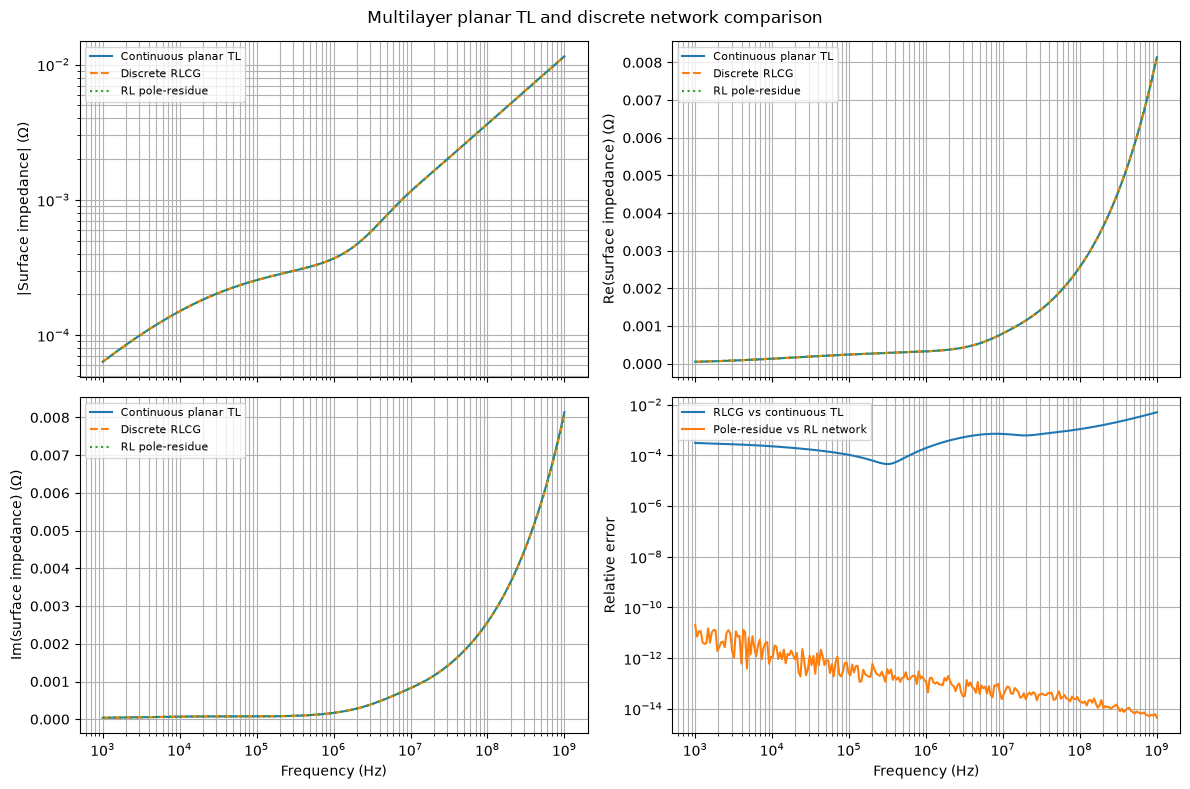

In [12]:
from scipy.linalg import solve_banded

def network_impedance_banded(s_values, L, G, C, B=None):
    """Input impedance of the 1D network using its tridiagonal admittance."""
    n = len(L)
    out = np.empty(len(np.atleast_1d(s_values)), complex)
    rhs = np.zeros(n, complex); rhs[0] = 1
    for k, sk in enumerate(np.atleast_1d(s_values)):
        inv = 1 / (sk * L)
        diagonal = G + sk * C + inv
        diagonal = diagonal.astype(complex, copy=True)
        diagonal[1:] += inv[:-1]
        offdiag = -inv[:-1]
        ab = np.zeros((3, n), complex)
        ab[0, 1:] = offdiag
        ab[1, :] = diagonal
        ab[2, :-1] = offdiag
        out[k] = solve_banded((1, 1), ab, rhs)[0]
    return out

z_multi_rlcg = network_impedance_banded(s_multi, L_multi, G_multi, C_multi)
# The RL eigenproblem omits capacitance consistently with the previous section.
z_multi_rl = network_impedance_banded(s_multi, L_multi, G_multi, np.zeros_like(C_multi))
p_multi, r_multi, d_multi = rl_poles_residues(L_multi, G_multi, B_multi)
z_multi_pr = eval_pole_residue(s_multi, p_multi, r_multi, d_multi)

relerr = np.abs(z_multi_rlcg - z_planar) / np.maximum(np.abs(z_planar), 1e-30)
relerr_pr = np.abs(z_multi_pr - z_multi_rl) / np.maximum(np.abs(z_multi_rl), 1e-30)
print(f"Maximum planar TL vs RLCG error: {np.max(relerr):.3%}")
print(f"Maximum RL network vs pole-residue error: {np.max(relerr_pr):.3e}")

fig, ax = plt.subplots(2, 2, figsize=(12, 8), sharex='col')
for name, z, style in [('Continuous planar TL', z_planar, '-'),
                       ('Discrete RLCG', z_multi_rlcg, '--'),
                       ('RL pole-residue', z_multi_pr, ':')]:
    ax[0, 0].loglog(f_multi, np.abs(z), style, label=name)
    ax[0, 1].semilogx(f_multi, np.real(z), style, label=name)
    ax[1, 0].semilogx(f_multi, np.imag(z), style, label=name)
ax[1, 1].loglog(f_multi, relerr, label='RLCG vs continuous TL')
ax[1, 1].loglog(f_multi, relerr_pr, label='Pole-residue vs RL network')
ax[0, 0].set_ylabel('|Surface impedance| (Ω)')
ax[0, 1].set_ylabel('Re(surface impedance) (Ω)')
ax[1, 0].set_ylabel('Im(surface impedance) (Ω)')
ax[1, 1].set_ylabel('Relative error')
for a in ax.flat: a.grid(True, which='both'); a.legend(fontsize=8)
for a in ax[1]: a.set_xlabel('Frequency (Hz)')
fig.suptitle('Multilayer planar TL and discrete network comparison')
fig.tight_layout(); plt.show()


### 8.4 PyTLWall reference: separate beam-impedance comparison

The following cell recreates PyTLWall's documented multilayer example. It is optional and requires `pytlwall` in the active kernel.

**Important:** PyTLWall's two *finite* layers (50 µm Cu + 2 mm steel) are not the same physical termination as our *semi-infinite* steel substrate. Moreover, PyTLWall's longitudinal beam impedance includes its own cylindrical beam/wall corrections. Therefore differences in this plot **must not** be interpreted purely as RLCG discretization error.

We display the simple circular ultra-relativistic conversion $Z_\parallel\approx (\ell/2\pi b)Z_s$ as a diagnostic only. This is **not** a claim of an exact PyTLWall reproduction.

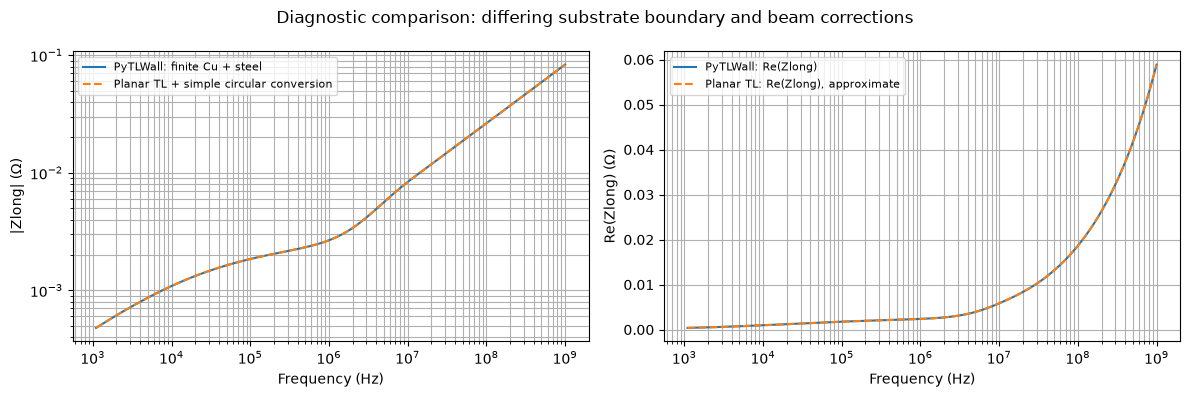

In [13]:
try:
    from pytlwall import Beam, Frequencies, Layer, Chamber, TlWall
except ImportError:
    print("PyTLWall is not installed in this kernel; skipping the PyTLWall benchmark.")
else:
    # Follow the documented example; PyTLWall owns its own frequency grid.
    py_freqs = Frequencies(fmin=3, fmax=9, fstep=2)
    py_beam = Beam(gammarel=7460.52)
    py_chamber = Chamber(pipe_rad_m=benchmark.pipe_radius,
                         pipe_len_m=benchmark.pipe_length,
                         chamber_shape='CIRCULAR')
    py_copper = Layer(thick_m=50e-6, sigmaDC=cu_coating.sigma,
                      freq_Hz=py_freqs.freq)
    py_steel = Layer(thick_m=2e-3, sigmaDC=steel.sigma,
                     freq_Hz=py_freqs.freq)
    py_chamber.layers = [py_copper, py_steel]
    py_wall = TlWall(chamber=py_chamber, beam=py_beam, frequencies=py_freqs)
    z_pytlwall = np.asarray(py_wall.calc_ZLong())
    f_py = np.asarray(py_freqs.freq)
    z_planar_py = planar_multilayer_impedance(2j * np.pi * f_py, benchmark)
    z_long_simple = benchmark.pipe_length / (2*np.pi*benchmark.pipe_radius) * z_planar_py

    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].loglog(f_py, np.abs(z_pytlwall), label='PyTLWall: finite Cu + steel')
    ax[0].loglog(f_py, np.abs(z_long_simple), '--',
                 label='Planar TL + simple circular conversion')
    ax[1].semilogx(f_py, np.real(z_pytlwall), label='PyTLWall: Re(Zlong)')
    ax[1].semilogx(f_py, np.real(z_long_simple), '--',
                   label='Planar TL: Re(Zlong), approximate')
    ax[0].set(xlabel='Frequency (Hz)', ylabel='|Zlong| (Ω)')
    ax[1].set(xlabel='Frequency (Hz)', ylabel='Re(Zlong) (Ω)')
    for a in ax: a.grid(True, which='both'); a.legend(fontsize=8)
    fig.suptitle('Diagnostic comparison: differing substrate boundary and beam corrections')
    fig.tight_layout(); plt.show()


### 8.5 Next validation steps

1. **Match the termination:** model the same 2 mm steel thickness and outer boundary in both implementations, or configure PyTLWall for a semi-infinite steel backing if supported.
2. **Match the observable:** first compare the wall/interface impedance used internally by PyTLWall; only then compare full longitudinal beam impedance.
3. **Convergence:** vary copper and substrate cell counts, truncation depth, and frequency limits independently.
4. **Capacitance:** extend the eigenvalue formulation to a general RLCG descriptor system. The current pole-residue extraction is RL only.
5. **Reduction:** choose a frequency-weighted passive reduction method rather than retaining poles solely by residue magnitude.

Source: [PyTLWall multilayer example](https://github.com/ImpedanCEI/TLWallNew/blob/main/doc/EXAMPLES_TLWALL.md).

---
# 9. SPS-oriented benchmark: longitudinal, dipolar, and quadrupolar impedances

**Scope and provenance.** This section is based on the documented PyTLWall **elliptical-chamber/Yokoya** and **multilayer** examples. The public examples do **not** establish an authoritative complete SPS lattice configuration. Therefore the default is explicitly an **SPS-oriented illustrative chamber**, *not* a validated full-SPS impedance model. To calculate a genuine SPS case, set `CONFIG_PATH` to an actual SPS PyTLWall configuration and inspect the imported parameters. No historical SPS impedance data are used.

**Two distinct validation levels**:

1. Compare the planar surface impedance from a continuous multilayer TL with the discretized RLCG network and its eigenvalue-derived pole-residue model.
2. Calculate longitudinal and transverse beam impedances with PyTLWall, then distinguish an **approximate geometry conversion** from an **empirical fixed-pole projection**. The latter is a numerical projection of PyTLWall data, **not** an analytical derivation of the exact beam-impedance poles.

The existing network uses constant material parameters and an RL eigenproblem for its rational representation. Dispersive magnetic materials and full cylindrical-field corrections are outside this model and must be treated separately.

In [14]:
from pathlib import Path
import warnings

# Set to a genuine SPS .cfg file when available; None uses the documented
# PyTLWall elliptical-chamber example with an illustrative steel wall.
CONFIG_PATH = None

# A deliberately broad diagnostic range. Numerical models may require
# special treatment near zero frequency or at very high frequency.
FMIN_HZ, FMAX_HZ, N_FREQ = 1e-1, 1e15, 401
f_sps = np.geomspace(FMIN_HZ, FMAX_HZ, N_FREQ)
s_sps = 2j * np.pi * f_sps

# The values below are NOT an official SPS chamber or lattice definition.
DEMO = dict(
    pipe_hor_m=0.030, pipe_ver_m=0.020,
    pipe_len_m=1.0, betax=100.0, betay=50.0,
    gammarel=7460.52,
    sigmaDC=1.45e6, thick_m=2e-3,
)
print('Benchmark mode:', 'PyTLWall configuration' if CONFIG_PATH else 'Illustrative elliptical chamber')

Benchmark mode: Illustrative elliptical chamber


## 9.1. Construct the PyTLWall reference

PyTLWall documents `Beam`, `Frequencies`, `Layer`, `Chamber`, `TlWall`, `CfgIo`, and the `ZDipX`, `ZDipY`, `ZQuadX`, `ZQuadY` properties. For a real SPS model, prefer loading its original `.cfg` via `CfgIo`; this avoids silently inventing SPS geometry, material dispersion, or lattice weighting. `Frequencies` is constructed with the documented logarithmic-grid interface; we use **its returned frequency grid**, not the requested grid, for all PyTLWall comparisons.

If PyTLWall is missing, this cell reports the installation requirement rather than substituting synthetic transverse reference curves.

In [15]:
try:
    from pytlwall import Beam, Frequencies, Layer, Chamber, TlWall, CfgIo
    PYTLWALL_SPS_AVAILABLE = True
except ImportError:
    PYTLWALL_SPS_AVAILABLE = False
    print('PyTLWall is not installed. Install TLWallNew in this notebook environment.')

sps_wall = None
if PYTLWALL_SPS_AVAILABLE:
    if CONFIG_PATH:
        if not Path(CONFIG_PATH).is_file():
            raise FileNotFoundError(f'PyTLWall configuration not found: {CONFIG_PATH}')
        sps_wall = CfgIo(str(CONFIG_PATH)).read_pytlwall()
        print('Loaded PyTLWall configuration:', CONFIG_PATH)
    else:
        # Documented examples use fmin/fmax as base-10 exponents.
        py_sps_freqs = Frequencies(fmin=np.log10(FMIN_HZ),
                                   fmax=np.log10(FMAX_HZ), fstep=2)
        py_sps_beam = Beam(gammarel=DEMO['gammarel'])
        py_sps_chamber = Chamber(
            pipe_hor_m=DEMO['pipe_hor_m'],
            pipe_ver_m=DEMO['pipe_ver_m'],
            pipe_len_m=DEMO['pipe_len_m'],
            chamber_shape='ELLIPTICAL',
            betax=DEMO['betax'], betay=DEMO['betay'],
        )
        py_sps_chamber.layers = [Layer(
            thick_m=DEMO['thick_m'], sigmaDC=DEMO['sigmaDC'],
            freq_Hz=py_sps_freqs.freq,
        )]
        sps_wall = TlWall(chamber=py_sps_chamber,
                          beam=py_sps_beam, frequencies=py_sps_freqs)

    # All quantities are taken from the same PyTLWall object.
    f_py_sps = np.asarray(sps_wall.frequencies.freq, dtype=float)
    z_py_sps = {}
    for key in ('ZLong', 'ZDipX', 'ZDipY', 'ZQuadX', 'ZQuadY'):
        z_py_sps[key] = np.asarray(getattr(sps_wall, key), dtype=complex)
        if z_py_sps[key].shape != f_py_sps.shape:
            raise ValueError(f'{key} has shape {z_py_sps[key].shape}; expected {f_py_sps.shape}')
    print('PyTLWall frequency points:', len(f_py_sps))
    print('Chamber shape:', sps_wall.chamber.chamber_shape)
    print('Layers:', len(sps_wall.chamber.layers))
    print('Inspect the chamber, layer parameters, boundary, and units before interpretation.')

PyTLWall frequency points: 1440
Chamber shape: ELLIPTICAL
Layers: 1
Inspect the chamber, layer parameters, boundary, and units before interpretation.


## 9.2. Inspect the PyTLWall reference (including signs)

These curves are calculated **directly** by PyTLWall, not reconstructed from an external SPS dataset. Plot real and imaginary parts separately because transverse quadrupole signs matter. The example values are per configured chamber/segment; **they are not automatically full-ring SPS impedances**.

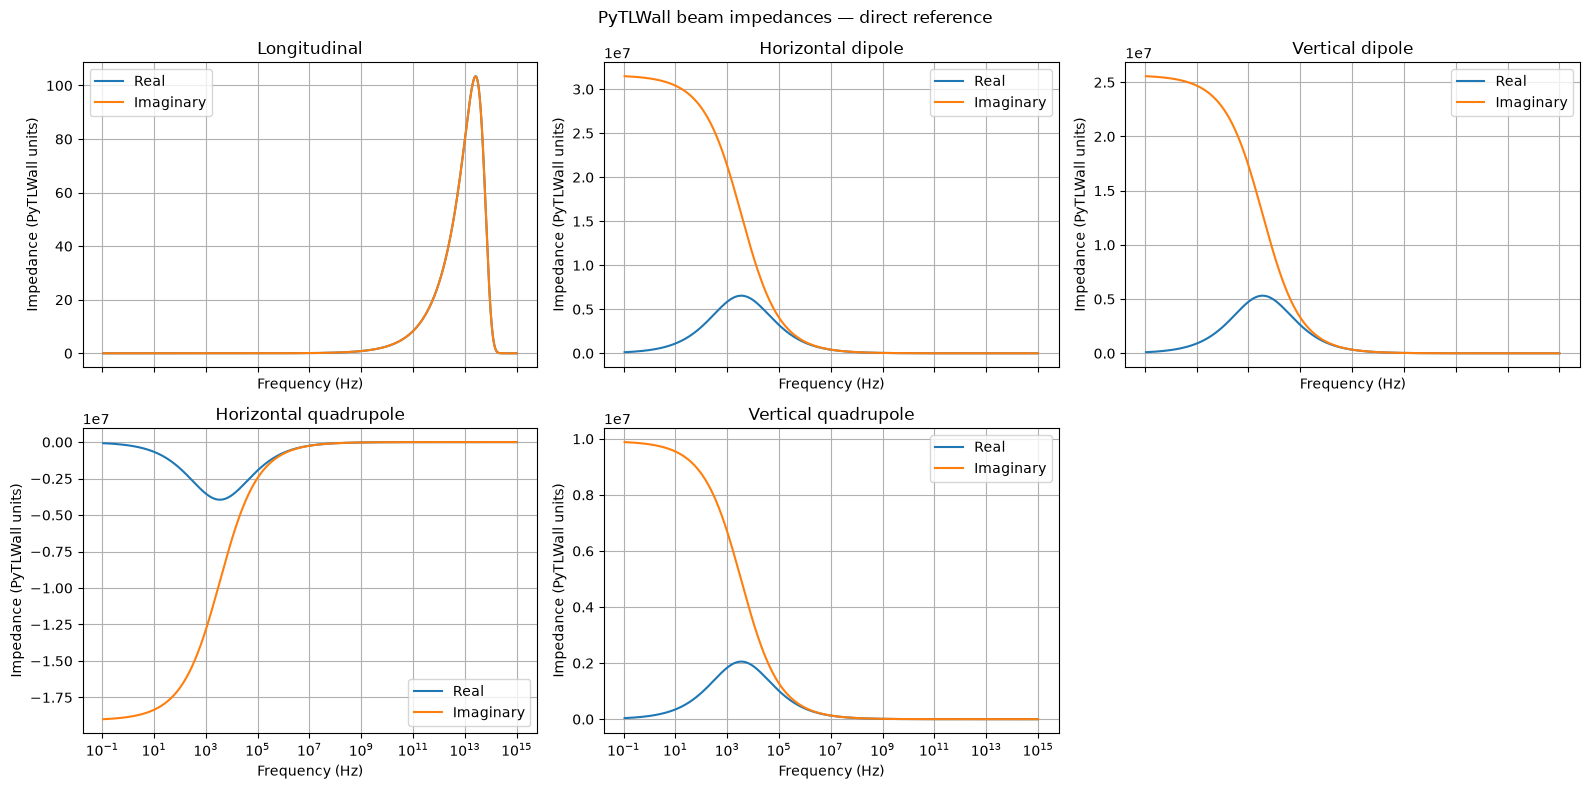

In [16]:
if sps_wall is not None:
    names = [('ZLong', 'Longitudinal'), ('ZDipX', 'Horizontal dipole'),
             ('ZDipY', 'Vertical dipole'), ('ZQuadX', 'Horizontal quadrupole'),
             ('ZQuadY', 'Vertical quadrupole')]
    fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharex=True)
    for ax, (key, title) in zip(axes.flat, names):
        ax.semilogx(f_py_sps, z_py_sps[key].real, label='Real')
        ax.semilogx(f_py_sps, z_py_sps[key].imag, label='Imaginary')
        ax.set_title(title)
        ax.set_xlabel('Frequency (Hz)')
        ax.set_ylabel('Impedance (PyTLWall units)')
        ax.grid(True, which='both')
        ax.legend()
    axes.flat[-1].axis('off')
    fig.suptitle('PyTLWall beam impedances — direct reference')
    fig.tight_layout()
    plt.show()

## 9.3. Material extraction and scope of the surface-impedance comparison

The network is a **planar** TL approximation. For the illustrative case, the steel wall is represented as a finite layer followed by a semi-infinite continuation of the **same material**, so the continuous TL reference equals the intrinsic impedance of steel. This is **not necessarily the termination used internally by PyTLWall**. In particular, a real SPS configuration may have an outer iron yoke with dispersive permeability.

To avoid silently misrepresenting such a configuration, the code below runs the independent surface-impedance benchmark **only for the explicitly defined non-dispersive illustrative material**. General imported configurations need a verified material and boundary adapter.

Network cells: 160; eigenvalue-derived poles: 160
Maximum surface TL/network relative error: 0.636%
Maximum pole-residue/network relative error: 1.922e-07


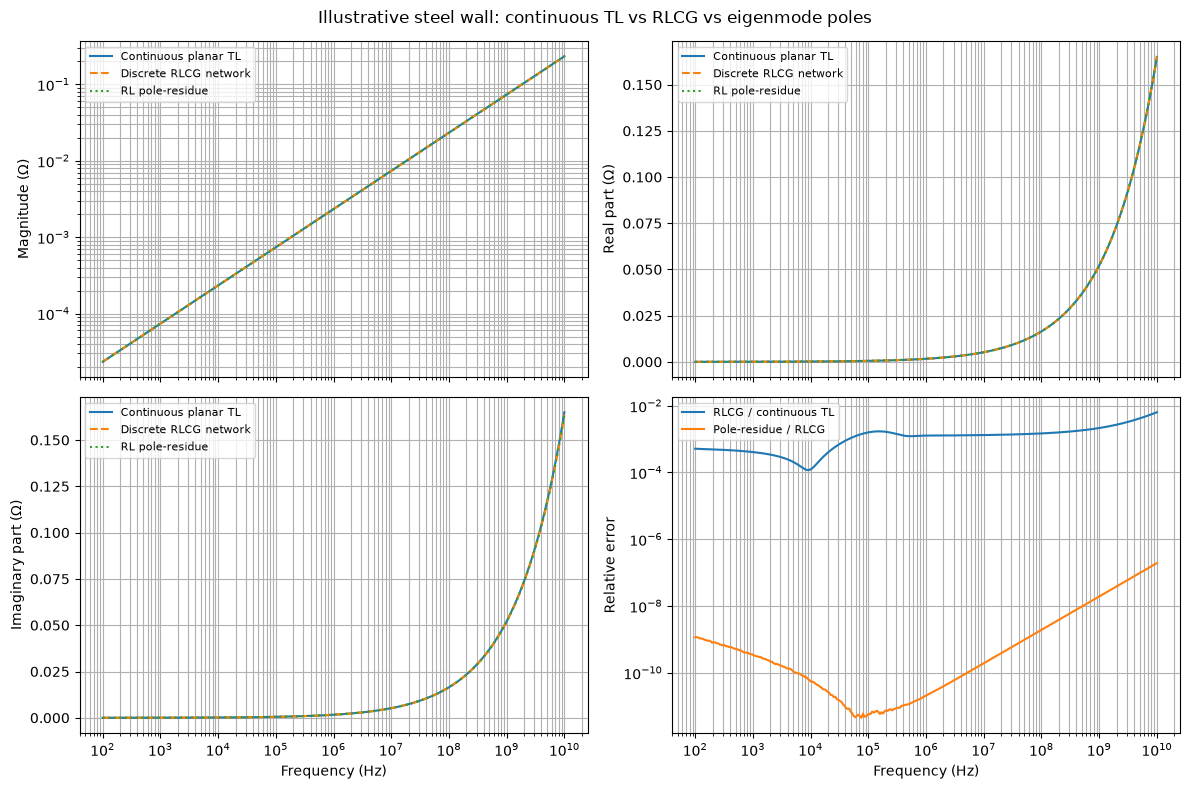

In [17]:
# This stack is intentionally independent of the optional .cfg import.
# It is the transparent, non-dispersive illustrative wall model.
sps_steel = Material('Illustrative stainless steel', sigma=DEMO['sigmaDC'])
sps_stack = WallStack(
    finite_layers=(FiniteLayer(sps_steel, DEMO['thick_m']),),
    substrate=sps_steel,
    pipe_radius=DEMO['pipe_ver_m'],
    pipe_length=DEMO['pipe_len_m'],
)

# A very broad frequency interval demands many spatial scales.
# Use a practical range for the first network experiment; broaden only
# after a mesh-convergence study.
FNET_MIN, FNET_MAX = 1e2, 1e10
f_net = np.geomspace(FNET_MIN, FNET_MAX, 301)
s_net = 2j * np.pi * f_net
z_cont = planar_multilayer_impedance(s_net, sps_stack)

# The existing multilayer mesh routine is reused without modification.
net_dx, net_materials, net_interfaces = multilayer_mesh(
    sps_stack, f_net, finite_cells=45, substrate_cells=115,
    cells_per_skin=8, depth_factor=7,
)
L_sps, G_sps, C_sps, B_sps = assemble_network(net_dx, net_materials)
z_net = network_impedance_banded(s_net, L_sps, G_sps, C_sps)
p_sps, r_sps, d_sps = rl_poles_residues(L_sps, G_sps, B_sps)
z_net_pr = eval_pole_residue(s_net, p_sps, r_sps, d_sps)

err_surface = np.abs(z_net-z_cont) / np.maximum(np.abs(z_cont), 1e-30)
err_pr = np.abs(z_net_pr-z_net) / np.maximum(np.abs(z_net), 1e-30)
print(f'Network cells: {len(net_dx)}; eigenvalue-derived poles: {len(p_sps)}')
print(f'Maximum surface TL/network relative error: {err_surface.max():.3%}')
print(f'Maximum pole-residue/network relative error: {err_pr.max():.3e}')

fig, axs = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
for label, z, style in [('Continuous planar TL', z_cont, '-'),
                        ('Discrete RLCG network', z_net, '--'),
                        ('RL pole-residue', z_net_pr, ':')]:
    axs[0,0].loglog(f_net, np.abs(z), style, label=label)
    axs[0,1].semilogx(f_net, np.real(z), style, label=label)
    axs[1,0].semilogx(f_net, np.imag(z), style, label=label)
axs[1,1].loglog(f_net, err_surface, label='RLCG / continuous TL')
axs[1,1].loglog(f_net, err_pr, label='Pole-residue / RLCG')
for a in axs.flat:
    a.grid(True, which='both'); a.legend(fontsize=8)
for a in axs[1]: a.set_xlabel('Frequency (Hz)')
axs[0,0].set_ylabel('Magnitude (Ω)')
axs[0,1].set_ylabel('Real part (Ω)')
axs[1,0].set_ylabel('Imaginary part (Ω)')
axs[1,1].set_ylabel('Relative error')
fig.suptitle('Illustrative steel wall: continuous TL vs RLCG vs eigenmode poles')
fig.tight_layout(); plt.show()

## 9.4. Longitudinal comparison: explicitly approximate circular conversion

For a circular, ultra-relativistic pipe, the commonly used first approximation is

$$Z_\parallel(s) \simeq \frac{L}{2\pi b} Z_s(s).$$

**This is not an exact model of an elliptical SPS chamber.** It is included only as a diagnostic; it does not account for the elliptical boundary, beam corrections, outer-boundary mismatch, or material dispersion. In configuration-file mode, it must not be interpreted as a full SPS prediction.

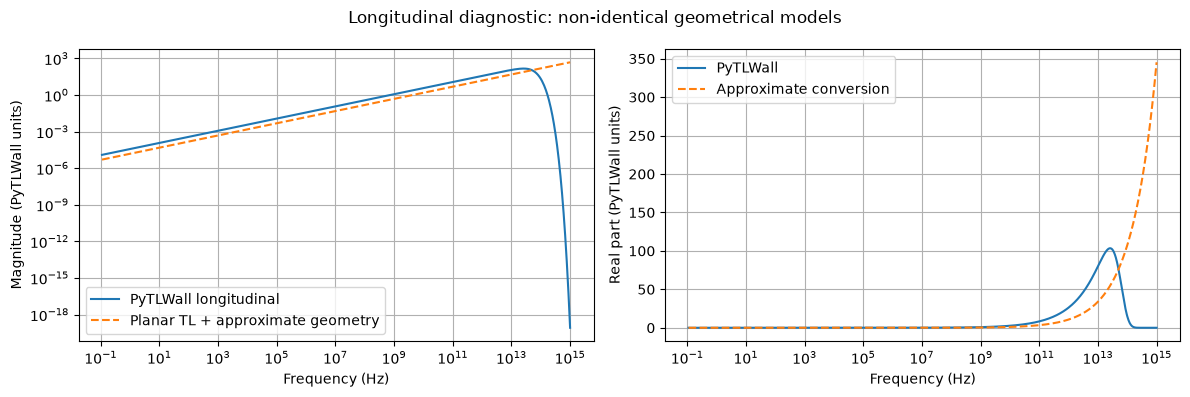

In [18]:
if sps_wall is not None:
    # Use a clearly stated equivalent-radius convention for a diagnostic only.
    # The geometric mean is NOT an exact elliptical chamber correction.
    a, b = DEMO['pipe_hor_m'], DEMO['pipe_ver_m']
    b_equiv = np.sqrt(a*b)
    f_cmp = f_py_sps
    z_s_cmp = planar_multilayer_impedance(2j*np.pi*f_cmp, sps_stack)
    z_long_approx = DEMO['pipe_len_m']/(2*np.pi*b_equiv) * z_s_cmp
    if CONFIG_PATH is not None:
        warnings.warn('Longitudinal approximation uses DEMO geometry, not imported SPS geometry. Diagnostic only.')
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].loglog(f_cmp, abs(z_py_sps['ZLong']), label='PyTLWall longitudinal')
    ax[0].loglog(f_cmp, abs(z_long_approx), '--', label='Planar TL + approximate geometry')
    ax[1].semilogx(f_cmp, z_py_sps['ZLong'].real, label='PyTLWall')
    ax[1].semilogx(f_cmp, z_long_approx.real, '--', label='Approximate conversion')
    ax[0].set_ylabel('Magnitude (PyTLWall units)')
    ax[1].set_ylabel('Real part (PyTLWall units)')
    for a in ax:
        a.set_xlabel('Frequency (Hz)'); a.grid(True, which='both'); a.legend()
    fig.suptitle('Longitudinal diagnostic: non-identical geometrical models')
    fig.tight_layout(); plt.show()

## 9.5. Rational representation of the actual PyTLWall beam impedances

**Important distinction.** The surface poles above are derived directly from the RL eigenproblem. The complete PyTLWall longitudinal/transverse impedances also contain geometry and beam corrections, and are **not guaranteed to have those same poles**. To assess whether a rational model can reproduce the full PyTLWall outputs, we perform a **fixed-pole least-squares projection** using the eigenvalue-derived wall poles plus optional extra negative real poles.

This is a **data-based projection** of PyTLWall, not the exact analytical pole-residue derivation requested as the eventual research goal. In particular, the transverse $1/s$ dependence and low-frequency asymptotes may require explicit integrator or other special terms. Here the fit includes an optional $1/s$ basis and a direct term, and uses frequency weights. The fitted model is evaluated on the same grid as the reference; a held-out validation set is advisable before interpreting it as a general-purpose macromodel.

The projection deliberately preserves *real* coefficients for a real time-domain impulse response. The transverse sign convention is inherited from PyTLWall.

ZLong: weighted projection RMS = 4.860e-01
ZDipX: weighted projection RMS = 7.651e-01
ZDipY: weighted projection RMS = 7.651e-01
ZQuadX: weighted projection RMS = 7.651e-01
ZQuadY: weighted projection RMS = 7.651e-01


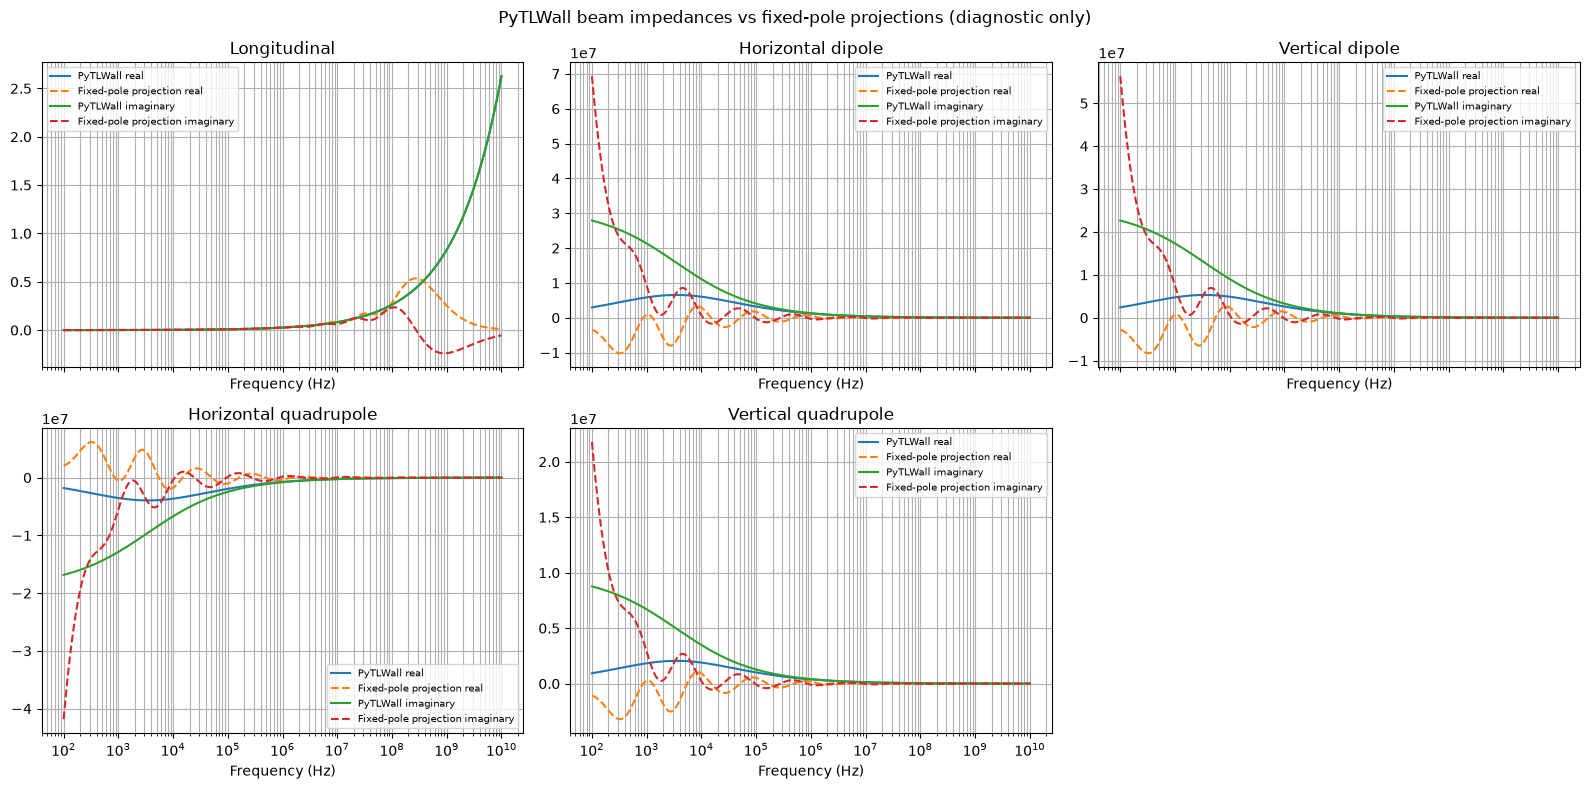

In [19]:
def project_to_real_poles(frequencies, impedance, poles, include_integrator=False,
                          relative_weight=True):
    """Project complex frequency samples onto real-coefficient rational basis.

    This is a fixed-pole least-squares approximation, not a network eigenanalysis.
    """
    ff = np.asarray(frequencies, dtype=float)
    yy = np.asarray(impedance, dtype=complex)
    ss = 2j*np.pi*ff
    pp = np.asarray(poles, dtype=float)
    scale = np.maximum(np.max(np.abs(pp)), 1.0)
    basis = [np.ones_like(ss, dtype=complex)]
    basis += [scale/(ss-p) for p in pp]
    if include_integrator:
        basis.append((2*np.pi*ff.min())/ss)
    A = np.column_stack(basis)
    weights = 1/np.maximum(np.abs(yy), max(np.max(np.abs(yy))*1e-6, 1e-30)) if relative_weight else np.ones_like(ff)
    Aw = A*weights[:, None]
    yw = yy*weights
    coef = np.linalg.lstsq(np.vstack([Aw.real, Aw.imag]),
                           np.r_[yw.real, yw.imag], rcond=1e-10)[0]
    approximation = A @ coef
    return approximation, coef, np.linalg.norm((approximation-yy)*weights)/np.sqrt(len(ff))

# A manageable, log-spaced subset of physical wall poles.
# This is an exploratory projection basis, not a guaranteed passive reduction.
ordered = np.argsort(-p_sps)
subset = np.unique(np.round(np.linspace(0, len(ordered)-1, 36)).astype(int))
projection_poles = p_sps[ordered[subset]]

if sps_wall is not None:
    z_projected = {}
    for key, target in z_py_sps.items():
        # Restrict this first projection to the range where the wall network was validated.
        mask = (f_py_sps >= FNET_MIN) & (f_py_sps <= FNET_MAX)
        if mask.sum() < 10:
            print(f'Not enough PyTLWall frequency samples for {key}; skipping projection.')
            continue
        fitted, coef, weighted_rms = project_to_real_poles(
            f_py_sps[mask], target[mask], projection_poles,
            include_integrator=key.startswith(('ZDip','ZQuad')),
        )
        z_projected[key] = (mask, fitted)
        print(f'{key}: weighted projection RMS = {weighted_rms:.3e}')

    fig, axs = plt.subplots(2, 3, figsize=(16, 8), sharex=True)
    for ax, (key, title) in zip(axs.flat, names):
        if key not in z_projected:
            ax.axis('off'); continue
        mask, fitted = z_projected[key]
        ax.semilogx(f_py_sps[mask], z_py_sps[key][mask].real, label='PyTLWall real')
        ax.semilogx(f_py_sps[mask], fitted.real, '--', label='Fixed-pole projection real')
        ax.semilogx(f_py_sps[mask], z_py_sps[key][mask].imag, label='PyTLWall imaginary')
        ax.semilogx(f_py_sps[mask], fitted.imag, '--', label='Fixed-pole projection imaginary')
        ax.set_title(title); ax.set_xlabel('Frequency (Hz)')
        ax.grid(True, which='both'); ax.legend(fontsize=7)
    axs.flat[-1].axis('off')
    fig.suptitle('PyTLWall beam impedances vs fixed-pole projections (diagnostic only)')
    fig.tight_layout(); plt.show()

## 9.6. Research milestones for a true SPS impedance macromodel

- **Input fidelity:** Load an authoritative SPS PyTLWall `.cfg` or `MultipleChamber` lattice inputs and record each chamber type, length, material model, and boundary. Do not label the illustrative default as the actual SPS.
- **Surface impedance:** Match the continuous TL termination and magnetic dispersion. If a layer has frequency-dependent permeability, add a passive rational constitutive model before deriving network eigenvalues.
- **Longitudinal impedance:** Derive the beam-to-wall transfer relation used by PyTLWall for the selected geometry, rather than relying on the circular approximation.
- **Transverse impedances:** Treat dipolar and quadrupolar geometry factors, the $1/s$ factor, normalization, and sign conventions explicitly. Only then can an augmented state-space system yield the actual beam-impedance poles without fitting the reference data.
- **Model reduction:** Compare passive order reduction against fixed-pole projections; verify passivity, causality, asymptotic limits, and independent-frequency validation.

**Source:** [PyTLWall documentation: TLWall examples](https://github.com/ImpedanCEI/TLWallNew/blob/main/doc/EXAMPLES_TLWALL.md).

---
# 10. PyTLWall longitudinal conversion: verified diagnostics

This section uses the **same** `sps_wall` object throughout. The earlier illustrative SPS configuration is **not an authenticated full SPS machine model**. A chamber loaded through `CONFIG_PATH` must be examined independently.

We test three separate statements:

1. Whether PyTLWall's longitudinal impedance equals its effective wall quantity multiplied by the geometrical factor and divided by the finite-γ Bessel correction.
2. How strongly that correction changes the result over frequency.
3. Whether our *independent planar* RLCG wall impedance matches PyTLWall's `KZeff`. **Do not equate these two quantities without validating geometry, material models, and termination.**

The first test is an internal consistency check, not an independent electromagnetic validation. The last test is an independent comparison but may legitimately disagree for elliptical geometry or different wall boundaries.

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import i0e

if sps_wall is None:
    raise RuntimeError("PyTLWall SPS object is missing. Run the SPS setup cells first.")

model = sps_wall
f_diag = np.asarray(model.frequencies.freq, dtype=float)
w_diag = 2 * np.pi * f_diag
b_diag = float(model.chamber.pipe_rad_m)
L_diag = float(model.chamber.pipe_len_m)
beta_diag = float(model.beam.betarel)
gamma_diag = float(model.beam.gammarel)
c0 = 299792458.0

# Stable evaluation: I0(x) = exp(x) * i0e(x), for nonnegative real x.
xi = w_diag * b_diag / (beta_diag * gamma_diag * c0)
correction_inverse = np.exp(-2 * xi) / i0e(xi)**2

z_effective_py = np.asarray(model._calc_KZeff(), dtype=complex)
z_long_py = np.asarray(model.calc_ZLong(), dtype=complex)
K_diag = L_diag / (2 * np.pi * b_diag)
z_long_unadjusted = K_diag * z_effective_py
z_long_reconstructed = z_long_unadjusted * correction_inverse

assert z_long_py.shape == f_diag.shape
assert z_effective_py.shape == f_diag.shape
relative_conversion_error = np.abs(z_long_reconstructed - z_long_py) / np.maximum(np.abs(z_long_py), 1e-30)
print(f"Maximum reconstruction error: {np.max(relative_conversion_error):.3e}")
print(f"Median reconstruction error:  {np.median(relative_conversion_error):.3e}")
print(f"Chamber shape: {model.chamber.chamber_shape}")
print(f"Effective radius used by PyTLWall: {b_diag:.6g} m")
print(f"Lorentz gamma: {gamma_diag:.6g}")

Maximum reconstruction error: 1.546e-14
Median reconstruction error:  4.174e-16
Chamber shape: ELLIPTICAL
Effective radius used by PyTLWall: 0.01 m
Lorentz gamma: 7460.52


## 10.1. Isolate the finite-γ correction

The correction is $H(\omega)=I_0(\omega b/(\beta c\gamma))^{-2}$. For $\xi\ll 1$, $H\simeq 1-\xi^2/2$. It is a **beam-field correction**, not a change to the conductor's skin effect. We plot it separately so that a high-frequency cutoff cannot be mistaken for a wall-network discrepancy.

The plots use the actual frequency grid and beam parameters of the PyTLWall object.

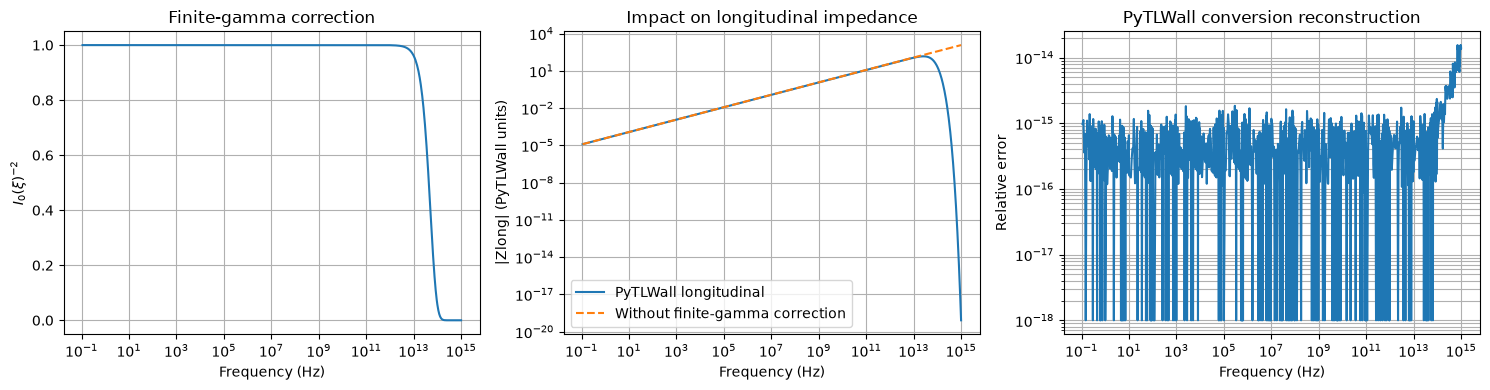

First sampled frequency with correction <= 0.99: 5.1000e+12 Hz
First sampled frequency with correction <= 0.9: 1.7000e+13 Hz
First sampled frequency with correction <= 0.5: 4.4000e+13 Hz
First sampled frequency with correction <= 0.01: 1.4000e+14 Hz


In [21]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
axs[0].semilogx(f_diag, correction_inverse)
axs[0].set(xlabel="Frequency (Hz)", ylabel=r"$I_0(\xi)^{-2}$", title="Finite-gamma correction")
axs[1].loglog(f_diag, np.abs(z_long_py), label="PyTLWall longitudinal")
axs[1].loglog(f_diag, np.abs(z_long_unadjusted), "--", label="Without finite-gamma correction")
axs[1].set(xlabel="Frequency (Hz)", ylabel="|Zlong| (PyTLWall units)", title="Impact on longitudinal impedance")
axs[1].legend()
axs[2].loglog(f_diag, np.maximum(relative_conversion_error, 1e-18))
axs[2].set(xlabel="Frequency (Hz)", ylabel="Relative error", title="PyTLWall conversion reconstruction")
for ax in axs:
    ax.grid(True, which="both")
fig.tight_layout()
plt.show()

for threshold in (0.99, 0.9, 0.5, 0.01):
    idx = np.flatnonzero(correction_inverse <= threshold)
    print(f"First sampled frequency with correction <= {threshold:g}: " +
          (f"{f_diag[idx[0]]:.4e} Hz" if idx.size else "outside sampled range"))

## 10.2. What does `KZeff` contain?

PyTLWall's `_calc_KZeff()` is its **effective wall quantity**, not necessarily the planar characteristic impedance. In particular, an elliptical chamber may use a geometry-dependent field model. The current notebook's `sps_stack` is an *independent illustrative planar material stack* and is **not automatically extracted from `sps_wall`**.

We therefore compare them **only as a diagnostic**, without interpreting the discrepancy as an RLCG discretization error. We also compare the discrete network with its own continuous planar TL reference, which is a meaningful numerical discretization check.

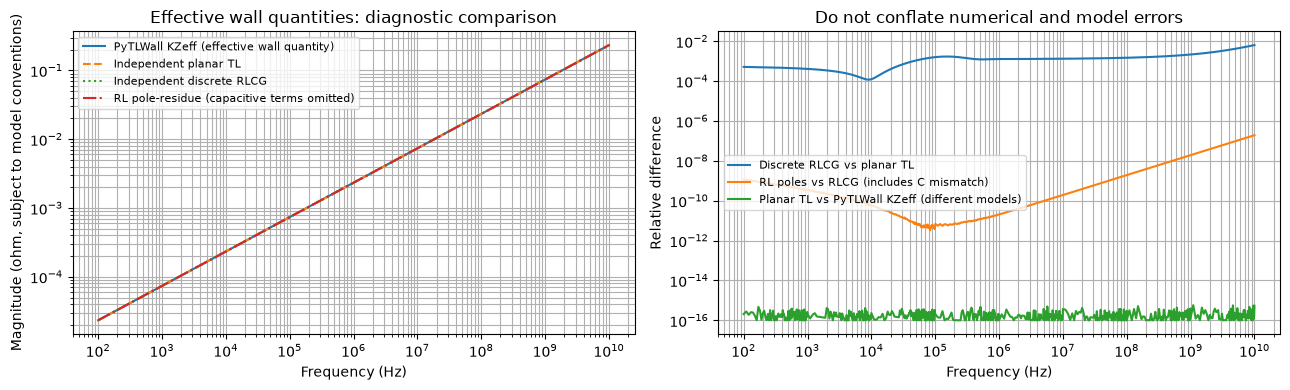

Maximum discrete RLCG / planar TL difference: 6.363e-03
Maximum RL pole model / full RLCG difference: 1.922e-07
Maximum planar TL / PyTLWall KZeff difference: 5.741e-16 (NOT a discretization error)


In [22]:
# Restrict the comparison to the frequency range used to build the RLCG mesh.
mask_diag = (f_diag >= FNET_MIN) & (f_diag <= FNET_MAX)
f_overlap = f_diag[mask_diag]
s_overlap = 2j * np.pi * f_overlap
if f_overlap.size < 3:
    raise ValueError("Insufficient overlap with the RLCG network frequency range.")

z_planar_overlap = planar_multilayer_impedance(s_overlap, sps_stack)
z_network_overlap = network_impedance_banded(s_overlap, L_sps, G_sps, C_sps)
z_poles_overlap = eval_pole_residue(s_overlap, p_sps, r_sps, d_sps)
z_py_overlap = z_effective_py[mask_diag]

err_network_planar = np.abs(z_network_overlap - z_planar_overlap) / np.maximum(np.abs(z_planar_overlap), 1e-30)
err_poles_network = np.abs(z_poles_overlap - z_network_overlap) / np.maximum(np.abs(z_network_overlap), 1e-30)
err_planar_pytlwall = np.abs(z_planar_overlap - z_py_overlap) / np.maximum(np.abs(z_py_overlap), 1e-30)

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
for label, zz, style in [
    ("PyTLWall KZeff (effective wall quantity)", z_py_overlap, "-"),
    ("Independent planar TL", z_planar_overlap, "--"),
    ("Independent discrete RLCG", z_network_overlap, ":"),
    ("RL pole-residue (capacitive terms omitted)", z_poles_overlap, "-."),
]:
    axs[0].loglog(f_overlap, np.abs(zz), style, label=label)
axs[0].set(xlabel="Frequency (Hz)", ylabel="Magnitude (ohm, subject to model conventions)",
           title="Effective wall quantities: diagnostic comparison")
axs[0].legend(fontsize=8)
axs[1].loglog(f_overlap, np.maximum(err_network_planar, 1e-16), label="Discrete RLCG vs planar TL")
axs[1].loglog(f_overlap, np.maximum(err_poles_network, 1e-16), label="RL poles vs RLCG (includes C mismatch)")
axs[1].loglog(f_overlap, np.maximum(err_planar_pytlwall, 1e-16), label="Planar TL vs PyTLWall KZeff (different models)")
axs[1].set(xlabel="Frequency (Hz)", ylabel="Relative difference", title="Do not conflate numerical and model errors")
axs[1].legend(fontsize=8)
for ax in axs:
    ax.grid(True, which="both")
fig.tight_layout()
plt.show()
print(f"Maximum discrete RLCG / planar TL difference: {err_network_planar.max():.3e}")
print(f"Maximum RL pole model / full RLCG difference: {err_poles_network.max():.3e}")
print(f"Maximum planar TL / PyTLWall KZeff difference: {err_planar_pytlwall.max():.3e} (NOT a discretization error)")

## 10.3. Transfer the wall network into the longitudinal conversion

We can apply the **verified PyTLWall conversion** to our wall model as a diagnostic:

$$Z_{\\parallel,\\mathrm{trial}}(j\\omega) = \\frac{L}{2\\pi b}\\,Z_{\\mathrm{wall,RLCG}}(j\\omega)\\,H(\\omega).$$

This tests the complete *frequency-domain pipeline*, but **does not prove** that the RLCG wall quantity is the same physical `KZeff` used by PyTLWall. This distinction matters particularly for an elliptical SPS chamber and for the outer boundary. The Bessel factor also means the complete function is not a finite rational transfer function; we must not label the resulting samples as an exact pole-residue representation.

The rational wall model and the nonrational beam correction are kept separate until the physical mapping is validated.

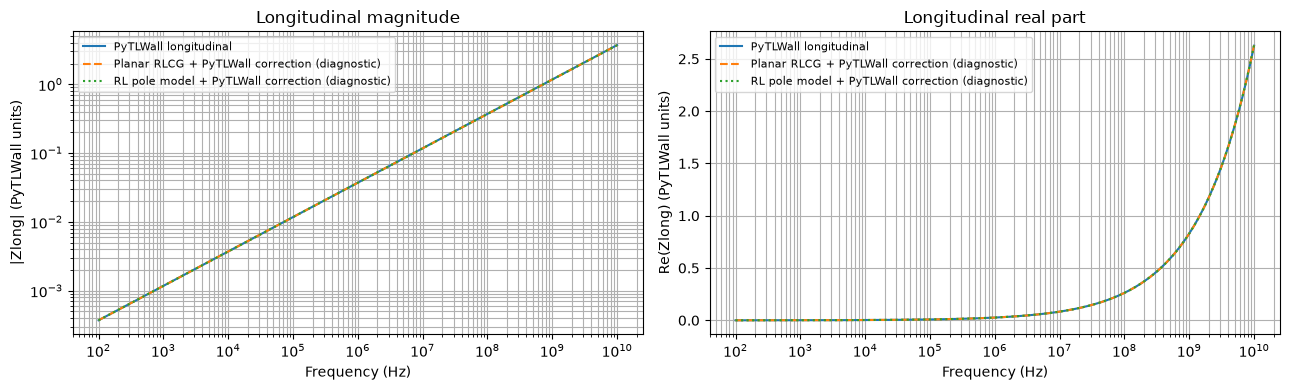

Next validation requirement: reproduce PyTLWall KZeff from identical layer and boundary models.
Next rational-model requirement: decide whether to retain or approximate the nonrational beam correction.


In [23]:
z_trial_network = K_diag * z_network_overlap * correction_inverse[mask_diag]
z_trial_poles = K_diag * z_poles_overlap * correction_inverse[mask_diag]
z_long_overlap = z_long_py[mask_diag]

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
for label, zz, style in [
    ("PyTLWall longitudinal", z_long_overlap, "-"),
    ("Planar RLCG + PyTLWall correction (diagnostic)", z_trial_network, "--"),
    ("RL pole model + PyTLWall correction (diagnostic)", z_trial_poles, ":"),
]:
    axs[0].loglog(f_overlap, np.abs(zz), style, label=label)
    axs[1].semilogx(f_overlap, np.real(zz), style, label=label)
axs[0].set(xlabel="Frequency (Hz)", ylabel="|Zlong| (PyTLWall units)", title="Longitudinal magnitude")
axs[1].set(xlabel="Frequency (Hz)", ylabel="Re(Zlong) (PyTLWall units)", title="Longitudinal real part")
for ax in axs:
    ax.grid(True, which="both")
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

print("Next validation requirement: reproduce PyTLWall KZeff from identical layer and boundary models.")
print("Next rational-model requirement: decide whether to retain or approximate the nonrational beam correction.")

Characteristic frequency: 3.560e+13 Hz
Characteristic time:      4.471e-15 s

First five positive real poles:
  p = 5.378651e+14 1/s
  p = 1.234625e+15 1/s
  p = 1.935499e+15 1/s
  p = 2.637304e+15 1/s
  p = 3.339460e+15 1/s

Correction thresholds:
  H <= 0.99: f = 5.100e+12 Hz
  H <= 0.90: f = 1.700e+13 Hz
  H <= 0.50: f = 4.400e+13 Hz
  H <= 0.10: f = 8.800e+13 Hz


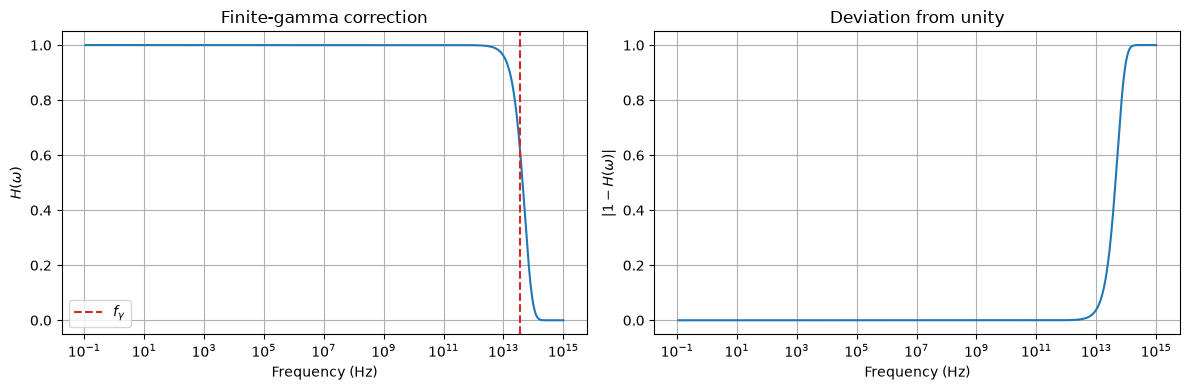

In [24]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.constants import c
from scipy.special import i0e, jn_zeros

# SPS PyTLWall parameters
model = sps_wall

f = np.asarray(py_sps_freqs.freq, dtype=float)

b = model.chamber.pipe_rad_m
beta = model.beam.betarel
gamma = model.beam.gammarel

# Characteristic time and frequency
tau = b / (beta * gamma * c)
f_gamma = 1.0 / (2.0 * np.pi * tau)

# Finite-gamma correction
xi = 2.0 * np.pi * f * tau

# Numerically stable evaluation for xi >= 0
H = np.exp(-2.0 * xi) / i0e(xi)**2

# Analytical poles in the Laplace plane
zeros = jn_zeros(0, 5)
p_positive = zeros / tau
p_negative = -zeros / tau

print(f"Characteristic frequency: {f_gamma:.3e} Hz")
print(f"Characteristic time:      {tau:.3e} s")

print("\nFirst five positive real poles:")
for p in p_positive:
    print(f"  p = {p:.6e} 1/s")

# Frequency thresholds
print("\nCorrection thresholds:")
for threshold in [0.99, 0.9, 0.5, 0.1]:
    idx = np.flatnonzero(H <= threshold)
    if idx.size:
        print(
            f"  H <= {threshold:.2f}: "
            f"f = {f[idx[0]]:.3e} Hz"
        )
    else:
        print(f"  H <= {threshold:.2f}: not reached")

# Plot
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].semilogx(f, H)
axes[0].axvline(
    f_gamma,
    color="tab:red",
    linestyle="--",
    label=r"$f_\gamma$"
)
axes[0].set_xlabel("Frequency (Hz)")
axes[0].set_ylabel(r"$H(\omega)$")
axes[0].set_title("Finite-gamma correction")
axes[0].grid(True, which="both")
axes[0].legend()

axes[1].semilogx(f, np.abs(1.0 - H))
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel(r"$|1-H(\omega)|$")
axes[1].set_title("Deviation from unity")
axes[1].grid(True, which="both")

plt.tight_layout()
plt.show()

## 10.4. Roadmap for transverse impedances

Before building transverse rational models, inspect the **actual installed PyTLWall implementation** for `calc_ZDipX`, `calc_ZDipY`, `calc_ZQuadX`, and `calc_ZQuadY`, including any inductive bypass, geometric coefficients, and sign conventions. A multiplication by a simple $1/s$ factor is not sufficient without verifying these details. For a genuine SPS model, chamber sections and optics weighting may also need to be combined.

The following optional introspection cell prints method source when available. It does not alter any computation.

In [29]:
import inspect
for method_name in ("calc_ZLong", "calc_ZDipX", "calc_ZDipY", "calc_ZQuadX", "calc_ZQuadY"):
    method = getattr(type(sps_wall), method_name, None)
    if method is None:
        print(f"{method_name}: not available on {type(sps_wall).__name__}")
        continue
    print(f"\n--- {method_name} ---")
    try:
        print(inspect.getsource(method))
    except (OSError, TypeError):
        print("Source unavailable in this installation.")


--- calc_ZLong ---
    def calc_ZLong(self) -> np.ndarray:
        """
        Calculate longitudinal impedance.
        
        Formula:
            ZLong = (L * KZeff) / (2π * r)
        
        where:
            L = pipe length
            r = pipe radius
            KZeff = effective surface impedance
        
        Returns:
            Complex array of longitudinal impedance [Ω]
        
        Raises:
            TlWallCalculationError: If calculation fails
        
        Example:
            >>> ZLong = wall.calc_ZLong()
            >>> print(f"ZLong at 1 MHz: {abs(ZLong[0]):.3e} Ω")
        """
        try:
            KZeff = self._calc_KZeff()
            
            # Zlong = pipe_len * KZeff / (2 * pi * pipe_rad_m)
            ZLong = (self.chamber.pipe_len_m * KZeff / 
                    (2.0 * const.pi * self.chamber.pipe_rad_m))
            
            # For future refinement we foresee a longitudinal correction factor
            # not fully implemented at t

Outer boundary: Non-PEC
Bypass inductance shape: (1440,)
Bypass inductance at first frequency: 1.000000e-07+0.000000e+00j H
Bypass inductance at last frequency:  1.000000e-07+0.000000e+00j H
Maximum relative error: 5.974e-13
Median relative error:  5.967e-13


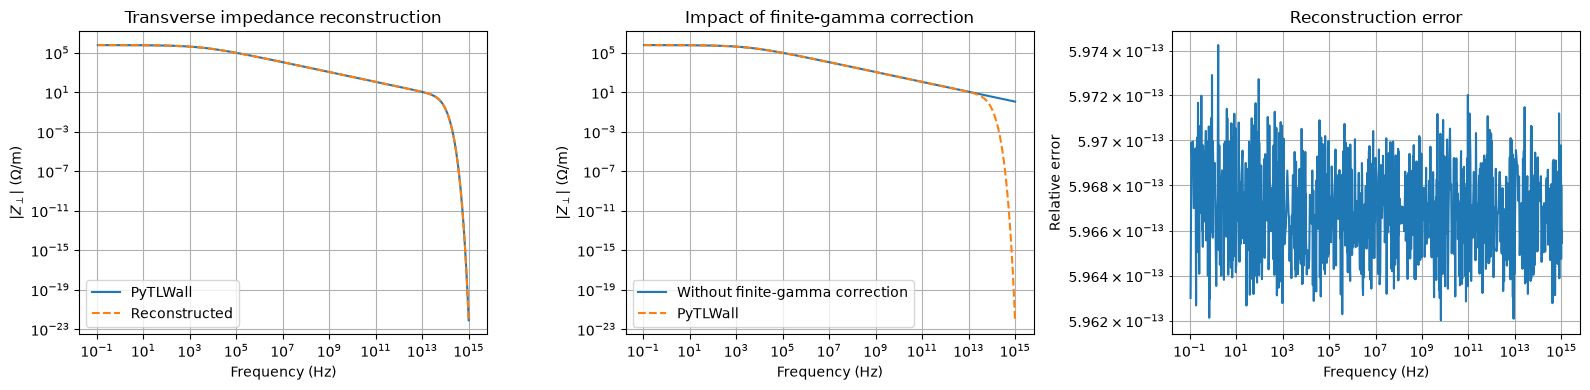

In [30]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.constants import c, mu_0, epsilon_0

model = sps_wall

f = np.asarray(py_sps_freqs.freq, dtype=float)
omega = 2.0 * np.pi * f
s = 1j * omega

b = model.chamber.pipe_rad_m
length = model.chamber.pipe_len_m
beta_rel = model.beam.betarel

# Effective inner wall impedance
Zs_inner = np.asarray(model._calc_KZeffin())
Zlong_inner = length / (2.0 * np.pi * b) * Zs_inner

# PyTLWall transverse wave number
k = omega / (beta_rel * c)

outer_layer = model.chamber.layers[-1]
is_pec = outer_layer.layer_type.upper() == "PEC"

if is_pec:
    Z_bypass = Zlong_inner
    L_ind = None
else:
    mu_outer = outer_layer.mu

    # Match PyTLWall's inductive bypass convention
    mu_eff = mu_0 * mu_outer / (mu_0 + mu_outer)
    L_ind = length * mu_eff / (2.0 * np.pi)

    Zind = s * L_ind

    # Parallel combination
    Z_bypass = Zlong_inner * Zind / (Zlong_inner + Zind)

# Transverse impedance without finite-gamma correction
Ztrans_no_gamma = 2.0 * Z_bypass / (b**2 * k)

# Correction used by PyTLWall
H = 1.0 / np.asarray(model._corr_imp)
Ztrans_reconstructed = Ztrans_no_gamma * H

# Reference
Ztrans_reference = np.asarray(model.calc_ZTrans())

# Relative reconstruction error
scale = np.maximum(np.abs(Ztrans_reference), 1e-30)
relative_error = np.abs(
    Ztrans_reconstructed - Ztrans_reference
) / scale

print(f"Outer boundary: {'PEC' if is_pec else 'Non-PEC'}")
if L_ind is not None:
    L_ind_array = np.asarray(L_ind)

    print(f"Bypass inductance shape: {L_ind_array.shape}")
    print(f"Bypass inductance at first frequency: {L_ind_array.flat[0]:.6e} H")
    print(f"Bypass inductance at last frequency:  {L_ind_array.flat[-1]:.6e} H")

print(f"Maximum relative error: {np.nanmax(relative_error):.3e}")
print(f"Median relative error:  {np.nanmedian(relative_error):.3e}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].loglog(f, np.abs(Ztrans_reference), label="PyTLWall")
axes[0].loglog(
    f, np.abs(Ztrans_reconstructed), "--",
    label="Reconstructed"
)
axes[0].set_title("Transverse impedance reconstruction")
axes[0].set_ylabel(r"$|Z_\perp|$ ($\Omega$/m)")
axes[0].legend()

axes[1].loglog(
    f, np.abs(Ztrans_no_gamma),
    label="Without finite-gamma correction"
)
axes[1].loglog(
    f, np.abs(Ztrans_reference), "--",
    label="PyTLWall"
)
axes[1].set_title("Impact of finite-gamma correction")
axes[1].set_ylabel(r"$|Z_\perp|$ ($\Omega$/m)")
axes[1].legend()

axes[2].loglog(f, relative_error)
axes[2].set_title("Reconstruction error")
axes[2].set_ylabel("Relative error")

for ax in axes:
    ax.set_xlabel("Frequency (Hz)")
    ax.grid(True, which="both")

plt.tight_layout()
plt.show()

In [31]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import eig
from scipy.constants import c

# Existing RL pole-residue model of the wall
poles_wall = np.asarray(p_sps, dtype=complex).ravel()
residues_wall = np.asarray(r_sps, dtype=complex).ravel()
direct_wall = complex(np.asarray(d_sps).item())

# Longitudinal geometric scaling
K = length / (2.0 * np.pi * b)

poles_long = poles_wall
residues_long = K * residues_wall
direct_long = K * direct_wall

# Constant bypass inductance
L_ind_scalar = float(np.real(np.asarray(L_ind).flat[0]))

# State-space realization of the longitudinal impedance
N = len(poles_long)

A = np.diag(poles_long)
B = np.ones((N, 1), dtype=complex)
C = residues_long.reshape(1, -1)
D = direct_long

# Extended state-space model
A_trans = np.block([
    [A, -B],
    [C / L_ind_scalar,
     np.array([[-D / L_ind_scalar]])]
])

B_trans = np.vstack([
    B,
    np.array([[D / L_ind_scalar]])
])

C_trans = np.zeros((1, N + 1), dtype=complex)
C_trans[0, -1] = (
    2.0 * beta_rel * c * L_ind_scalar / b**2
)

# Compute transverse poles and residues
poles_trans, V_left, V_right = eig(
    A_trans, left=True, right=True
)

residues_trans = np.empty(N + 1, dtype=complex)

for k in range(N + 1):
    v = V_right[:, k]
    w = V_left[:, k]

    numerator = (
        (C_trans @ v.reshape(-1, 1)).item()
        * (w.conj().reshape(1, -1) @ B_trans).item()
    )

    denominator = np.vdot(w, v)

    residues_trans[k] = numerator / denominator

print(f"Wall poles:       {N}")
print(f"Transverse poles: {len(poles_trans)}")
print(f"Maximum pole real part: {np.max(poles_trans.real):.6e}")
print(f"Unstable poles: {np.sum(poles_trans.real > 0)}")

Wall poles:       160
Transverse poles: 161
Maximum pole real part: 7.896196e-06
Unstable poles: 1


Maximum state-space reconstruction error: 4.793e-07


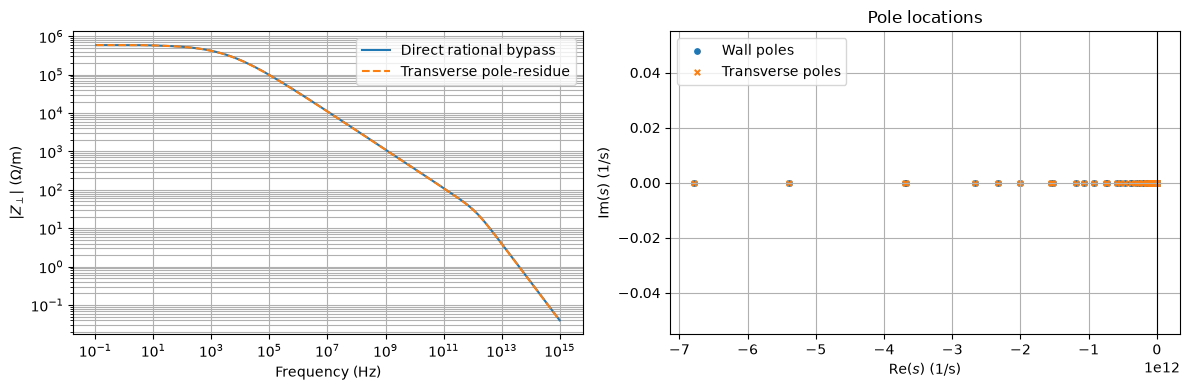

In [32]:
# Evaluate transverse pole-residue model
s_eval = 1j * 2.0 * np.pi * f

Ztrans_PR = np.sum(
    residues_trans[:, None]
    / (s_eval[None, :] - poles_trans[:, None]),
    axis=0
)

# Direct evaluation of the same rational transformation
Zlong_PR = direct_long + np.sum(
    residues_long[:, None]
    / (s_eval[None, :] - poles_long[:, None]),
    axis=0
)

Ztrans_direct = (
    2.0 * beta_rel * c / b**2
    * L_ind_scalar * Zlong_PR
    / (Zlong_PR + s_eval * L_ind_scalar)
)

relative_error = (
    np.abs(Ztrans_PR - Ztrans_direct)
    / np.maximum(np.abs(Ztrans_direct), 1e-30)
)

print(
    "Maximum state-space reconstruction error:",
    f"{np.max(relative_error):.3e}"
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].loglog(f, np.abs(Ztrans_direct),
               label="Direct rational bypass")
axes[0].loglog(f, np.abs(Ztrans_PR), "--",
               label="Transverse pole-residue")
axes[0].set_xlabel("Frequency (Hz)")
axes[0].set_ylabel(r"$|Z_\perp|$ ($\Omega$/m)")
axes[0].legend()
axes[0].grid(True, which="both")

axes[1].scatter(
    poles_wall.real, poles_wall.imag,
    s=15, label="Wall poles"
)
axes[1].scatter(
    poles_trans.real, poles_trans.imag,
    s=15, marker="x", label="Transverse poles"
)
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_xlabel(r"Re($s$) (1/s)")
axes[1].set_ylabel(r"Im($s$) (1/s)")
axes[1].set_title("Pole locations")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

Maximum pole real part: 5.524539e-05
Positive poles: 1
Maximum reconstruction error: 1.720e-06


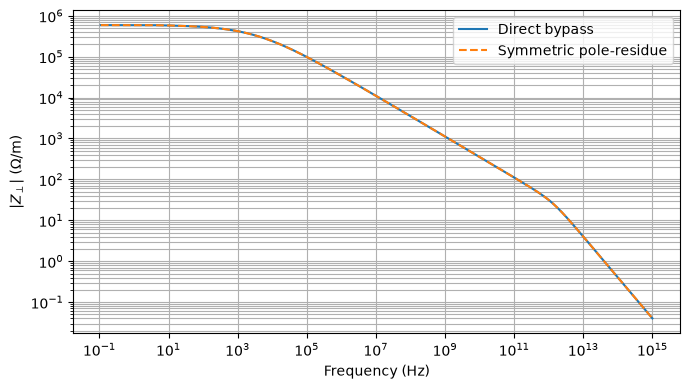

In [33]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import eigh
from scipy.constants import c

# Longitudinal pole-residue coefficients
p = np.real(np.asarray(poles_long))
r = np.real(np.asarray(residues_long))
D = float(np.real(direct_long))
L_b = float(np.real(L_ind_scalar))

# Check assumptions
assert np.all(p < 0), "Wall poles must be negative."
assert np.all(r <= 0), "Expected non-positive RL residues."
assert D > 0, "Expected positive direct term."
assert L_b > 0, "Bypass inductance must be positive."

g = np.sqrt(-r)
N = len(p)

# Symmetric extended system matrix
A_sym = np.zeros((N + 1, N + 1))

A_sym[:N, :N] = np.diag(p)
A_sym[:N, -1] = -g / np.sqrt(L_b)
A_sym[-1, :N] = -g / np.sqrt(L_b)
A_sym[-1, -1] = -D / L_b

# Symmetric eigendecomposition
p_trans_sym, U = eigh(A_sym)

# Transverse output scaling
K_trans = 2.0 * beta_rel * c * L_b / b**2

# Input and output vectors in symmetric coordinates
B_sym = np.concatenate([
    g,
    [D / np.sqrt(L_b)]
])

C_sym = np.zeros(N + 1)
C_sym[-1] = K_trans / np.sqrt(L_b)

# Residues from orthonormal eigenvectors
res_trans_sym = (
    (C_sym @ U) * (U.T @ B_sym)
)

# Evaluate the pole-residue representation
s_eval = 1j * 2.0 * np.pi * f

Ztrans_sym = np.sum(
    res_trans_sym[:, None]
    / (s_eval[None, :] - p_trans_sym[:, None]),
    axis=0
)

# Direct rational bypass
Zlong_PR = D + np.sum(
    r[:, None] / (s_eval[None, :] - p[:, None]),
    axis=0
)

Ztrans_direct = (
    2.0 * beta_rel * c / b**2
    * L_b * Zlong_PR
    / (Zlong_PR + s_eval * L_b)
)

relative_error = (
    np.abs(Ztrans_sym - Ztrans_direct)
    / np.maximum(np.abs(Ztrans_direct), 1e-30)
)

print(f"Maximum pole real part: {np.max(p_trans_sym):.6e}")
print(f"Positive poles: {np.sum(p_trans_sym > 0)}")
print(f"Maximum reconstruction error: {np.max(relative_error):.3e}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.loglog(f, np.abs(Ztrans_direct), label="Direct bypass")
ax.loglog(f, np.abs(Ztrans_sym), "--", label="Symmetric pole-residue")
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel(r"$|Z_\perp|$ ($\Omega$/m)")
ax.grid(True, which="both")
ax.legend()
plt.tight_layout()
plt.show()

In [34]:
import numpy as np

# Check the DC cancellation identity
Z_dc = D - np.sum(r / p)

# First-order coefficient of Z_in(s) around s = 0
L_wall = -np.sum(r / p**2)

print(f"Z_in(0): {Z_dc:.6e}")
print(f"Low-frequency wall inductance: {L_wall:.6e} H")

# Locate eigenvalue closest to zero
idx_zero = np.argmin(np.abs(p_trans_sym))

print(f"\nEigenvalue closest to zero: {p_trans_sym[idx_zero]:.6e}")
print(f"Associated residue: {res_trans_sym[idx_zero]:.6e}")

# Compare predicted and reconstructed DC transverse impedance
Ztrans_dc_expected = (
    2.0 * beta_rel * c / b**2
    * L_ind_scalar * L_wall
    / (L_ind_scalar + L_wall)
)

print(f"\nExpected Z_trans(0): {Ztrans_dc_expected:.6e}")

Z_in(0): -4.831691e-13
Low-frequency wall inductance: 5.891459e-06 H

Eigenvalue closest to zero: 5.524539e-05
Associated residue: -7.013269e-01

Expected Z_trans(0): 5.895776e+05


Original wall modes: 160
Active wall modes:   144
Transverse poles:    144

Largest transverse pole: -6.015147e+01 1/s
Positive poles: 0
Minimum residue: 2.245386e-45
Maximum reconstruction error: 3.768e-08


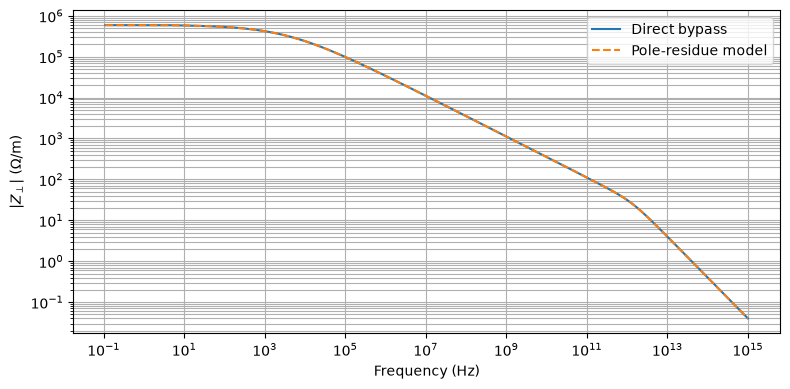

In [40]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import eigh
from scipy.constants import c

# Existing longitudinal pole-residue model
p_all = np.real(np.asarray(poles_long)).ravel()
r_all = np.real(np.asarray(residues_long)).ravel()

L_b = float(np.real(L_ind_scalar))
K_trans = 2.0 * beta_rel * c / b**2

# Remove uncoupled modes
active = r_all < 0.0

p = p_all[active]
r = r_all[active]

assert np.all(p < 0.0)
assert np.all(r < 0.0)
assert L_b > 0.0

# F(s) = Z_in(s)/s = sum_k (r_k/p_k)/(s-p_k)
g = np.sqrt(r / p)

# Stable symmetric rank-one update
A_red = np.diag(p) - np.outer(g, g) / L_b

# Eigenvalue decomposition
p_trans_red, U = eigh(A_red)

# Transverse residues
couplings = U.T @ g
r_trans_red = K_trans * couplings**2

# Frequency-domain evaluation
s_eval = 1j * 2.0 * np.pi * f

Ztrans_PR = np.sum(
    r_trans_red[:, None]
    / (s_eval[None, :] - p_trans_red[:, None]),
    axis=0
)

# Direct evaluation of the reduced bypass
F_direct = np.sum(
    (r / p)[:, None]
    / (s_eval[None, :] - p[:, None]),
    axis=0
)

Ztrans_direct = (
    K_trans * L_b * F_direct / (F_direct + L_b)
)

relative_error = (
    np.abs(Ztrans_PR - Ztrans_direct)
    / np.maximum(np.abs(Ztrans_direct), 1e-30)
)

print(f"Original wall modes: {len(p_all)}")
print(f"Active wall modes:   {len(p)}")
print(f"Transverse poles:    {len(p_trans_red)}")

print(f"\nLargest transverse pole: {np.max(p_trans_red):.6e} 1/s")
print(f"Positive poles: {np.sum(p_trans_red > 0)}")
print(f"Minimum residue: {np.min(r_trans_red):.6e}")
print(f"Maximum reconstruction error: {np.max(relative_error):.3e}")

fig, ax = plt.subplots(figsize=(8, 4))

ax.loglog(f, np.abs(Ztrans_direct), label="Direct bypass")
ax.loglog(f, np.abs(Ztrans_PR), "--", label="Pole-residue model")

ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel(r"$|Z_\perp|$ ($\Omega$/m)")
ax.grid(True, which="both")
ax.legend()

plt.tight_layout()
plt.show()

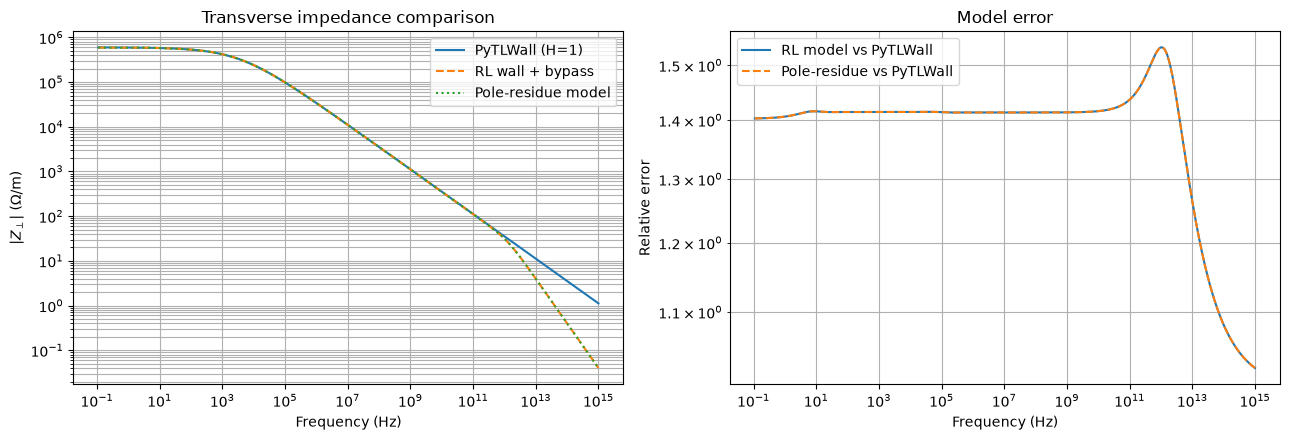

Within the network model frequency range:
Maximum RL model error: 1.416e+00
Maximum pole-residue error: 1.416e+00


In [41]:
import numpy as np
import matplotlib.pyplot as plt

# PyTLWall reference without finite-gamma correction
Z_py = np.asarray(Ztrans_no_gamma)

# Our rational transverse model
Z_pr = np.asarray(Ztrans_PR)

# Direct bypass of our RL wall model
Z_rl = np.asarray(Ztrans_direct)

# Relative errors
err_pr = np.abs(Z_pr - Z_py) / np.maximum(np.abs(Z_py), 1e-30)
err_rl = np.abs(Z_rl - Z_py) / np.maximum(np.abs(Z_py), 1e-30)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].loglog(f, np.abs(Z_py), label="PyTLWall (H=1)")
axes[0].loglog(f, np.abs(Z_rl), "--", label="RL wall + bypass")
axes[0].loglog(f, np.abs(Z_pr), ":", label="Pole-residue model")

axes[0].set_xlabel("Frequency (Hz)")
axes[0].set_ylabel(r"$|Z_\perp|$ ($\Omega$/m)")
axes[0].set_title("Transverse impedance comparison")
axes[0].grid(True, which="both")
axes[0].legend()

axes[1].loglog(f, err_rl, label="RL model vs PyTLWall")
axes[1].loglog(f, err_pr, "--", label="Pole-residue vs PyTLWall")

axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("Relative error")
axes[1].set_title("Model error")
axes[1].grid(True, which="both")
axes[1].legend()

plt.tight_layout()
plt.show()

# Report errors within the intended model frequency range
valid = (f >= FNET_MIN) & (f <= FNET_MAX)

print("Within the network model frequency range:")
print(f"Maximum RL model error: {np.max(err_rl[valid]):.3e}")
print(f"Maximum pole-residue error: {np.max(err_pr[valid]):.3e}")

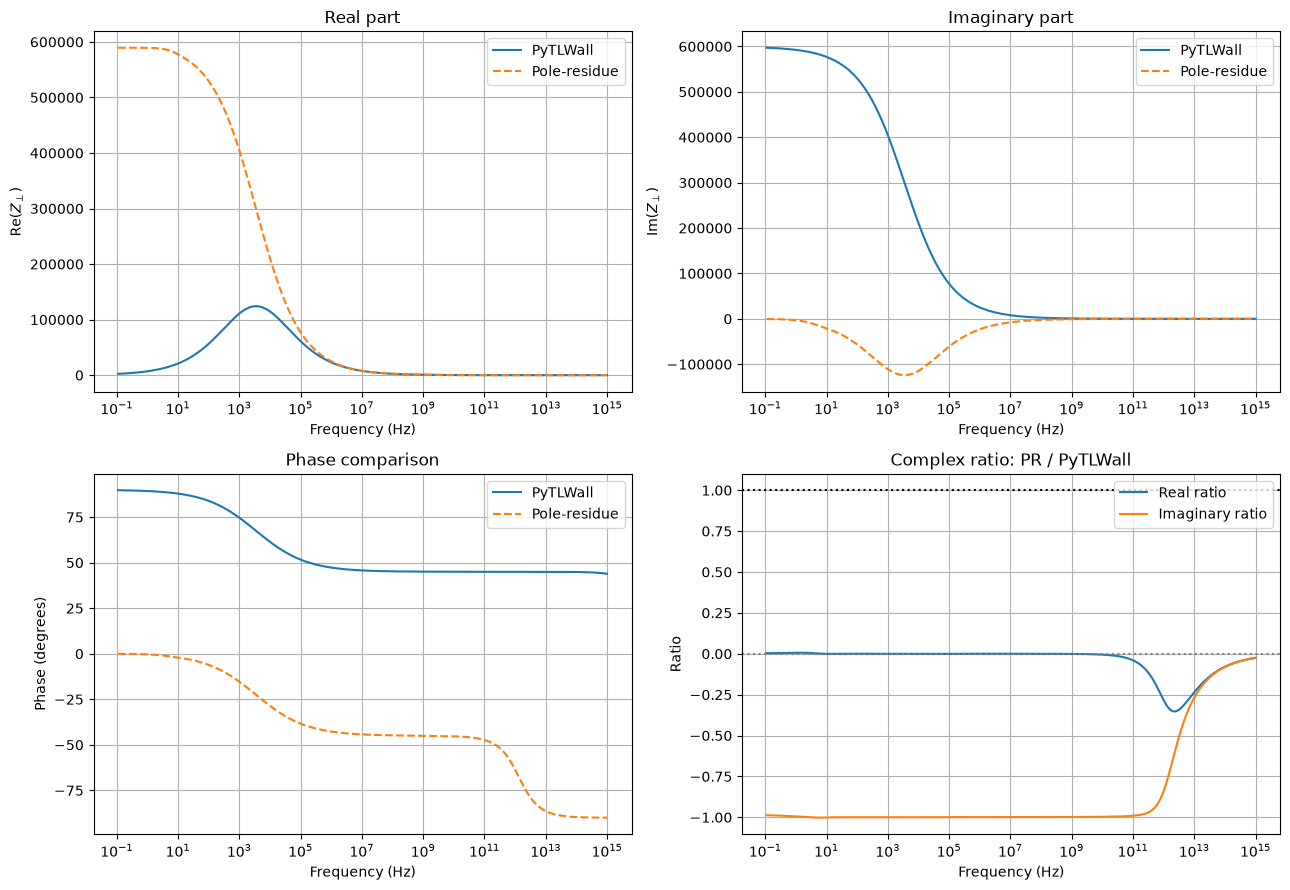

Within the network model frequency range:
Median magnitude ratio: 0.998743
Median phase difference: -90.006 deg
Median complex ratio: -0.000110-0.998672j


In [42]:
import numpy as np
import matplotlib.pyplot as plt

Z_py = np.asarray(Ztrans_no_gamma)
Z_pr = np.asarray(Ztrans_PR)
Z_rl = np.asarray(Ztrans_direct)

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# Real parts
axes[0, 0].semilogx(f, Z_py.real, label="PyTLWall")
axes[0, 0].semilogx(f, Z_pr.real, "--", label="Pole-residue")
axes[0, 0].set_title("Real part")
axes[0, 0].set_ylabel(r"Re($Z_\perp$)")

# Imaginary parts
axes[0, 1].semilogx(f, Z_py.imag, label="PyTLWall")
axes[0, 1].semilogx(f, Z_pr.imag, "--", label="Pole-residue")
axes[0, 1].set_title("Imaginary part")
axes[0, 1].set_ylabel(r"Im($Z_\perp$)")

# Phase comparison
axes[1, 0].semilogx(
    f, np.angle(Z_py, deg=True),
    label="PyTLWall"
)
axes[1, 0].semilogx(
    f, np.angle(Z_pr, deg=True), "--",
    label="Pole-residue"
)
axes[1, 0].set_title("Phase comparison")
axes[1, 0].set_ylabel("Phase (degrees)")

# Complex ratio
ratio = Z_pr / Z_py

axes[1, 1].semilogx(f, ratio.real, label="Real ratio")
axes[1, 1].semilogx(f, ratio.imag, label="Imaginary ratio")
axes[1, 1].axhline(1, color="black", linestyle=":")
axes[1, 1].axhline(0, color="gray", linestyle=":")
axes[1, 1].set_title("Complex ratio: PR / PyTLWall")
axes[1, 1].set_ylabel("Ratio")

for ax in axes.flat:
    ax.set_xlabel("Frequency (Hz)")
    ax.grid(True, which="both")
    ax.legend()

plt.tight_layout()
plt.show()

# Numerical diagnostics within the intended frequency range
valid = (f >= FNET_MIN) & (f <= FNET_MAX)

ratio_valid = ratio[valid]

print("Within the network model frequency range:")
print(f"Median magnitude ratio: {np.median(np.abs(ratio_valid)):.6f}")
print(f"Median phase difference: "
      f"{np.median(np.angle(ratio_valid, deg=True)):.3f} deg")
print(f"Median complex ratio: {np.median(ratio_valid):.6f}")

Maximum relative error in model range: 6.360e-03
Median relative error in model range: 1.273e-03


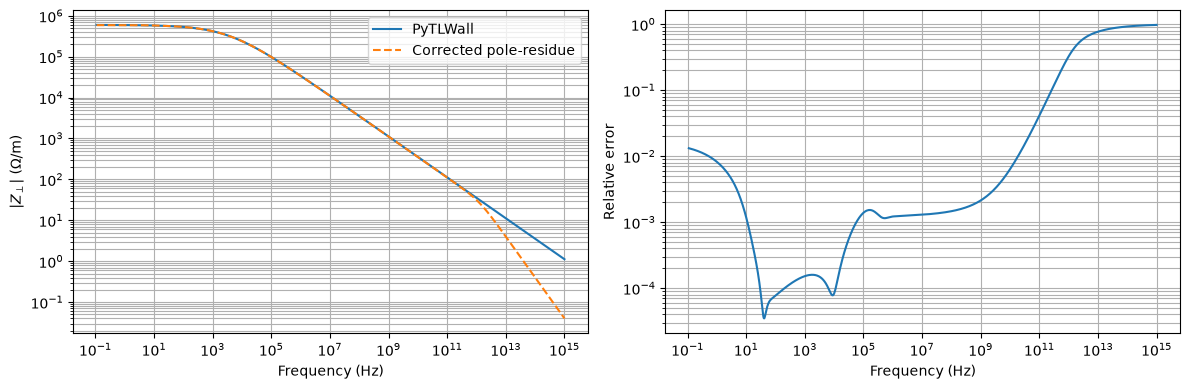

In [43]:
# Apply the transverse impedance convention
Ztrans_PR_corrected = 1j * Ztrans_PR

# Compare against PyTLWall without finite-gamma correction
Z_py = np.asarray(Ztrans_no_gamma)

relative_error = (
    np.abs(Ztrans_PR_corrected - Z_py)
    / np.maximum(np.abs(Z_py), 1e-30)
)

valid = (f >= FNET_MIN) & (f <= FNET_MAX)

print(
    "Maximum relative error in model range:",
    f"{np.max(relative_error[valid]):.3e}"
)

print(
    "Median relative error in model range:",
    f"{np.median(relative_error[valid]):.3e}"
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].loglog(f, np.abs(Z_py), label="PyTLWall")
axes[0].loglog(
    f, np.abs(Ztrans_PR_corrected), "--",
    label="Corrected pole-residue"
)
axes[0].set_xlabel("Frequency (Hz)")
axes[0].set_ylabel(r"$|Z_\perp|$ ($\Omega$/m)")
axes[0].legend()
axes[0].grid(True, which="both")

axes[1].loglog(f, relative_error)
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("Relative error")
axes[1].grid(True, which="both")

plt.tight_layout()
plt.show()

In [44]:
import inspect
import numpy as np

model = sps_wall
chamber = model.chamber

print("Chamber shape:", chamber.chamber_shape)

print("\nYokoya-related chamber attributes:")
for name in dir(chamber):
    if "yok" in name.lower() or "factor" in name.lower():
        value = getattr(chamber, name)
        if not callable(value):
            print(f"  {name}: {value}")

print("\nTransverse-related TlWall methods:")
for name in dir(model):
    if any(term in name.lower() for term in
           ["dip", "quad", "trans", "yok"]):
        attr = getattr(model, name)
        if callable(attr):
            try:
                print(f"  {name}{inspect.signature(attr)}")
            except (ValueError, TypeError):
                print(f"  {name}")

Chamber shape: ELLIPTICAL

Yokoya-related chamber attributes:
  _detx_yoko_list: [-0.    -0.002 -0.004 ... -0.4   -0.4   -0.4  ]
  _dety_yoko_list: [0.    0.006 0.009 ... 0.4   0.4   0.4  ]
  _drivx_yoko_list: [1.    0.993 0.986 ... 0.399 0.399 0.4  ]
  _drivy_yoko_list: [1.    0.997 0.995 ... 0.81  0.81  0.81 ]
  _long_yoko_list: [1.    0.981 0.979 ... 0.99  0.99  1.   ]
  detx_yokoya_factor: -0.318
  dety_yokoya_factor: 0.331
  drivx_yokoya_factor: 0.527
  drivy_yokoya_factor: 0.856
  long_yokoya_factor: 0.918
  yokoya_q: 0.19999999999999996
  yokoya_q_idx: 200

Transverse-related TlWall methods:
  calc_ZTrans() -> numpy.ndarray
  calc_ZTransDSC() -> numpy.ndarray
  calc_ZTransISC() -> numpy.ndarray


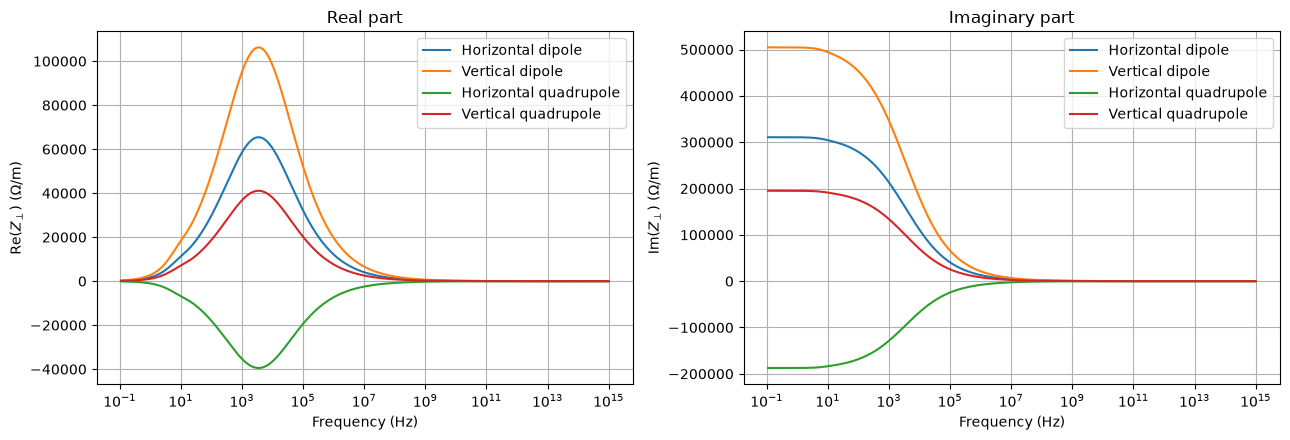

In [45]:
import numpy as np
import matplotlib.pyplot as plt

# Yokoya factors from the elliptical chamber
yokoya = {
    "Horizontal dipole": chamber.drivx_yokoya_factor,
    "Vertical dipole": chamber.drivy_yokoya_factor,
    "Horizontal quadrupole": chamber.detx_yokoya_factor,
    "Vertical quadrupole": chamber.dety_yokoya_factor,
}

# Common transverse poles and real residues
transverse_models = {}

for name, factor in yokoya.items():
    transverse_models[name] = {
        "poles": p_trans_red.copy(),
        "residues": factor * r_trans_red,
        "yokoya_factor": factor,
    }

# Evaluate the four transverse impedances
s_eval = 1j * 2.0 * np.pi * f

Z_components = {}

for name, model_data in transverse_models.items():
    poles = model_data["poles"]
    residues = model_data["residues"]

    Z_components[name] = 1j * np.sum(
        residues[:, None] / (s_eval[None, :] - poles[:, None]),
        axis=0,
    )

# Plot real and imaginary parts
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for name, Z in Z_components.items():
    axes[0].semilogx(f, Z.real, label=name)
    axes[1].semilogx(f, Z.imag, label=name)

axes[0].set_title("Real part")
axes[0].set_ylabel(r"Re($Z_\perp$) ($\Omega$/m)")

axes[1].set_title("Imaginary part")
axes[1].set_ylabel(r"Im($Z_\perp$) ($\Omega$/m)")

for ax in axes:
    ax.set_xlabel("Frequency (Hz)")
    ax.grid(True, which="both")
    ax.legend()

plt.tight_layout()
plt.show()

In [51]:
# Yokoya factors for the elliptical chamber
factors = chamber.get_yokoya_factors()

# Transverse pole-residue components
transverse_pr = {
    "dip_x": factors["drivx"] * r_trans_red,
    "dip_y": factors["drivy"] * r_trans_red,
    "quad_x": factors["detx"] * r_trans_red,
    "quad_y": factors["dety"] * r_trans_red,
}

# All components share the same poles
transverse_poles = p_trans_red.copy()

# Evaluate the impedance components
s = 1j * 2 * np.pi * f

Z_transverse = {
    name: 1j * np.sum(
        residues[:, None] /
        (s[None, :] - transverse_poles[:, None]),
        axis=0
    )
    for name, residues in transverse_pr.items()
}

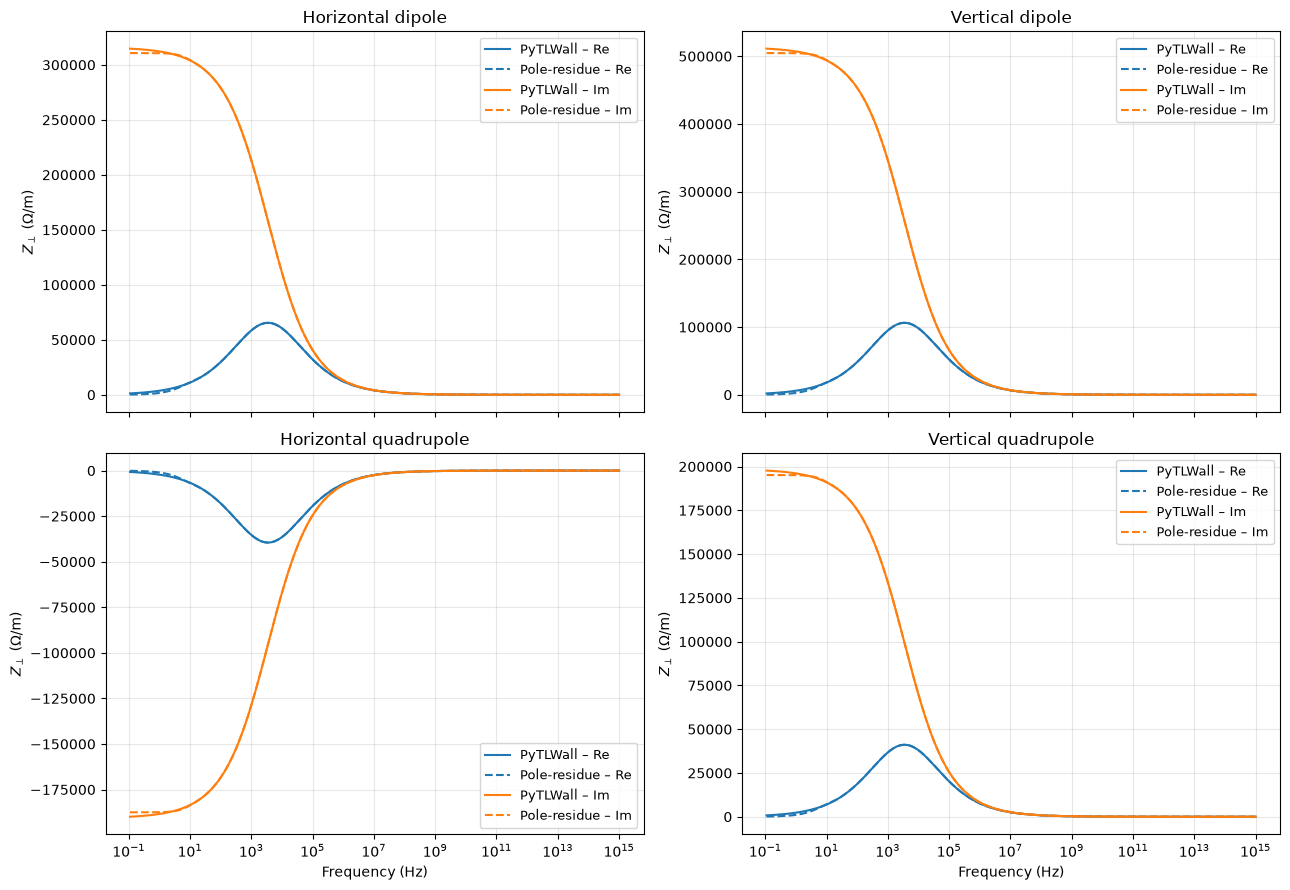

Horizontal dipole        : max relative error = 6.360e-03
Vertical dipole          : max relative error = 6.360e-03
Horizontal quadrupole    : max relative error = 6.360e-03
Vertical quadrupole      : max relative error = 6.360e-03


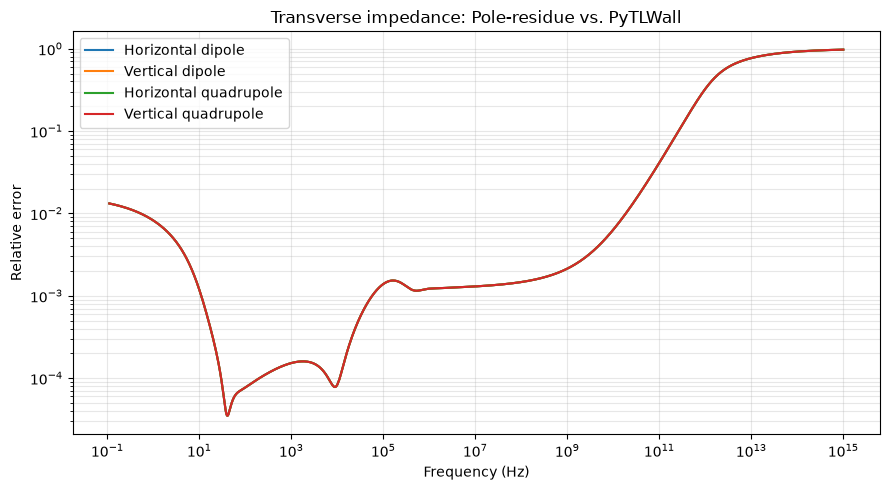

In [52]:
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Transverse impedance comparison: Pole-residue vs. PyTLWall
# ------------------------------------------------------------

# Frequency array and Laplace variable
freq = np.asarray(f)
s = 1j * 2.0 * np.pi * freq

# PyTLWall transverse base impedance (without finite-gamma correction)
Z_base_py = np.asarray(Ztrans_no_gamma)

# Transverse pole-residue base impedance
Z_base_pr = 1j * np.sum(
    r_trans_red[:, None] /
    (s[None, :] - p_trans_red[:, None]),
    axis=0,
)

# Yokoya factors
factors = chamber.get_yokoya_factors()

components = {
    "Horizontal dipole": factors["drivx"],
    "Vertical dipole": factors["drivy"],
    "Horizontal quadrupole": factors["detx"],
    "Vertical quadrupole": factors["dety"],
}

# Build component impedances
Z_py = {
    name: factor * Z_base_py
    for name, factor in components.items()
}

Z_pr = {
    name: factor * Z_base_pr
    for name, factor in components.items()
}

# ------------------------------------------------------------
# Plot 1: Real and imaginary parts
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 2, figsize=(13, 9), sharex=True
)

for ax, (name, _) in zip(axes.flat, components.items()):

    ax.plot(
        freq, Z_py[name].real,
        color="C0", label="PyTLWall – Re"
    )
    ax.plot(
        freq, Z_pr[name].real,
        "--", color="C0", label="Pole-residue – Re"
    )

    ax.plot(
        freq, Z_py[name].imag,
        color="C1", label="PyTLWall – Im"
    )
    ax.plot(
        freq, Z_pr[name].imag,
        "--", color="C1", label="Pole-residue – Im"
    )

    ax.set_xscale("log")
    ax.set_title(name)
    ax.set_ylabel(r"$Z_\perp$ ($\Omega$/m)")
    ax.grid(True, which="both", alpha=0.3)
    ax.legend(fontsize=9)

for ax in axes[-1]:
    ax.set_xlabel("Frequency (Hz)")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Plot 2: Relative errors
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 5))

valid = (freq >= FNET_MIN) & (freq <= FNET_MAX)

for name in components:

    error = (
        np.abs(Z_pr[name] - Z_py[name])
        / np.maximum(np.abs(Z_py[name]), 1e-30)
    )

    ax.loglog(freq, error, label=name)

    print(
        f"{name:25s}: "
        f"max relative error = {np.max(error[valid]):.3e}"
    )

ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Relative error")
ax.set_title("Transverse impedance: Pole-residue vs. PyTLWall")
ax.grid(True, which="both", alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

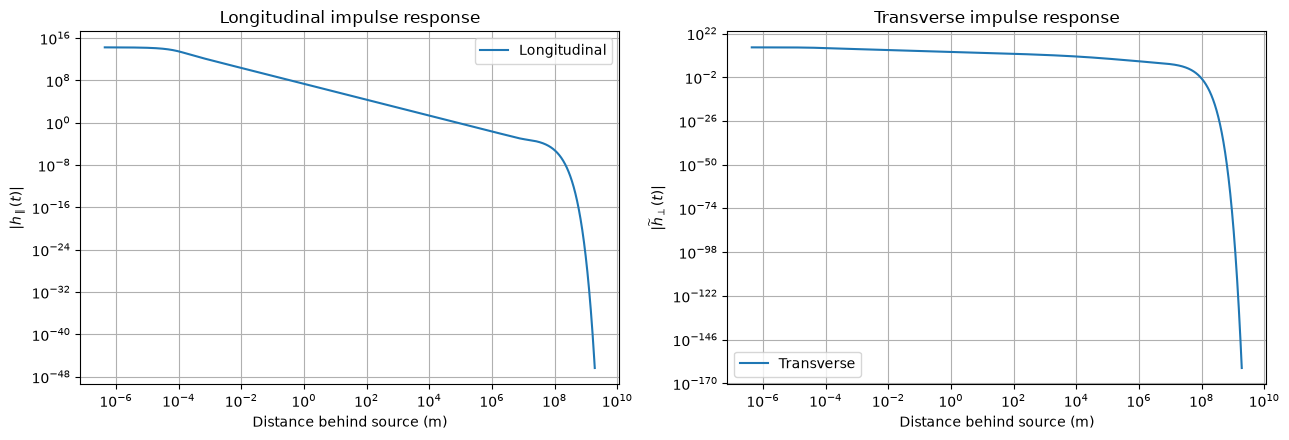

Fastest relaxation time: 1.472e-13 s
Slowest relaxation time: 6.419e-02 s
Distance range: 4.414e-07 to 1.924e+09 m


In [53]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.constants import c

# ------------------------------------------------------------
# Longitudinal and transverse impulse responses
# ------------------------------------------------------------

p_long = np.real(np.asarray(poles_long)).ravel()
r_long = np.real(np.asarray(residues_long)).ravel()

p_trans = np.real(np.asarray(p_trans_red)).ravel()
r_trans = np.real(np.asarray(r_trans_red)).ravel()

# Keep dynamically coupled modes
mask_long = (p_long < 0.0) & (r_long != 0.0)
mask_trans = (p_trans < 0.0) & (r_trans > 0.0)

p_long = p_long[mask_long]
r_long = r_long[mask_long]

p_trans = p_trans[mask_trans]
r_trans = r_trans[mask_trans]

# Time range based on the pole distribution
all_poles = np.concatenate([p_long, p_trans])

tau_min = 1.0 / np.max(np.abs(all_poles))
tau_max = 1.0 / np.min(np.abs(all_poles))

t = np.logspace(
    np.log10(tau_min) - 2,
    np.log10(tau_max) + 2,
    2000
)

# Inverse Laplace transforms for t > 0
h_long = np.sum(
    r_long[:, None] * np.exp(p_long[:, None] * t[None, :]),
    axis=0
)

h_trans = np.sum(
    r_trans[:, None] * np.exp(p_trans[:, None] * t[None, :]),
    axis=0
)

# Distance behind the source particle
z = beta_rel * c * t

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].loglog(z, np.abs(h_long), label="Longitudinal")
axes[0].set_title("Longitudinal impulse response")
axes[0].set_xlabel("Distance behind source (m)")
axes[0].set_ylabel(r"$|h_\parallel(t)|$")
axes[0].grid(True, which="both")
axes[0].legend()

axes[1].loglog(z, np.abs(h_trans), label="Transverse")
axes[1].set_title("Transverse impulse response")
axes[1].set_xlabel("Distance behind source (m)")
axes[1].set_ylabel(r"$|\widetilde h_\perp(t)|$")
axes[1].grid(True, which="both")
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"Fastest relaxation time: {tau_min:.3e} s")
print(f"Slowest relaxation time: {tau_max:.3e} s")
print(f"Distance range: {z.min():.3e} to {z.max():.3e} m")

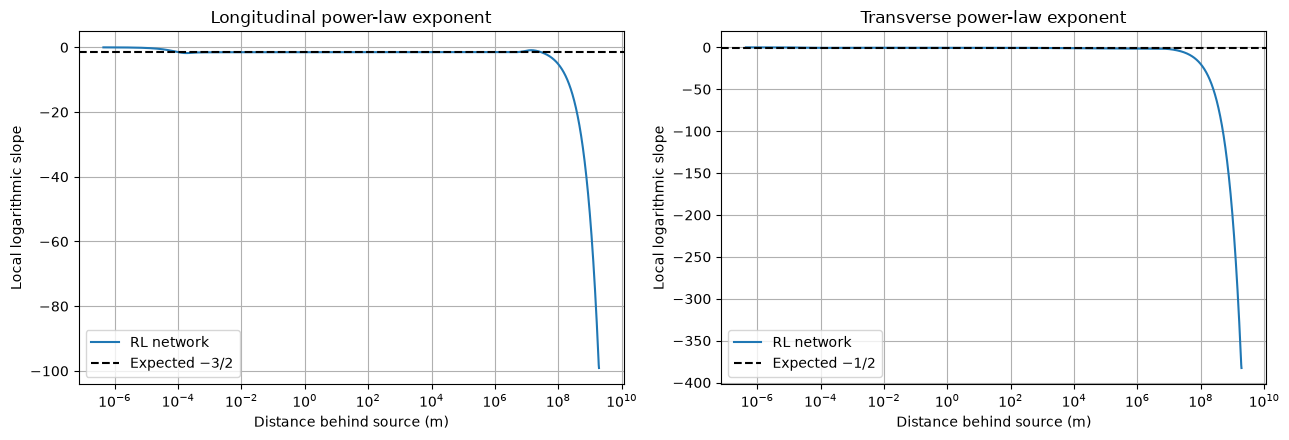

In [54]:
# ------------------------------------------------------------
# Local power-law exponents
# ------------------------------------------------------------

def local_log_slope(x, y):
    log_x = np.log(x)
    log_y = np.log(np.maximum(np.abs(y), 1e-300))
    return np.gradient(log_y, log_x)

slope_long = local_log_slope(z, h_long)
slope_trans = local_log_slope(z, h_trans)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].semilogx(z, slope_long, label="RL network")
axes[0].axhline(
    -1.5, color="black", linestyle="--",
    label=r"Expected $-3/2$"
)
axes[0].set_title("Longitudinal power-law exponent")
axes[0].set_ylabel("Local logarithmic slope")

axes[1].semilogx(z, slope_trans, label="RL network")
axes[1].axhline(
    -0.5, color="black", linestyle="--",
    label=r"Expected $-1/2$"
)
axes[1].set_title("Transverse power-law exponent")
axes[1].set_ylabel("Local logarithmic slope")

for ax in axes:
    ax.set_xlabel("Distance behind source (m)")
    ax.grid(True, which="both")
    ax.legend()

plt.tight_layout()
plt.show()

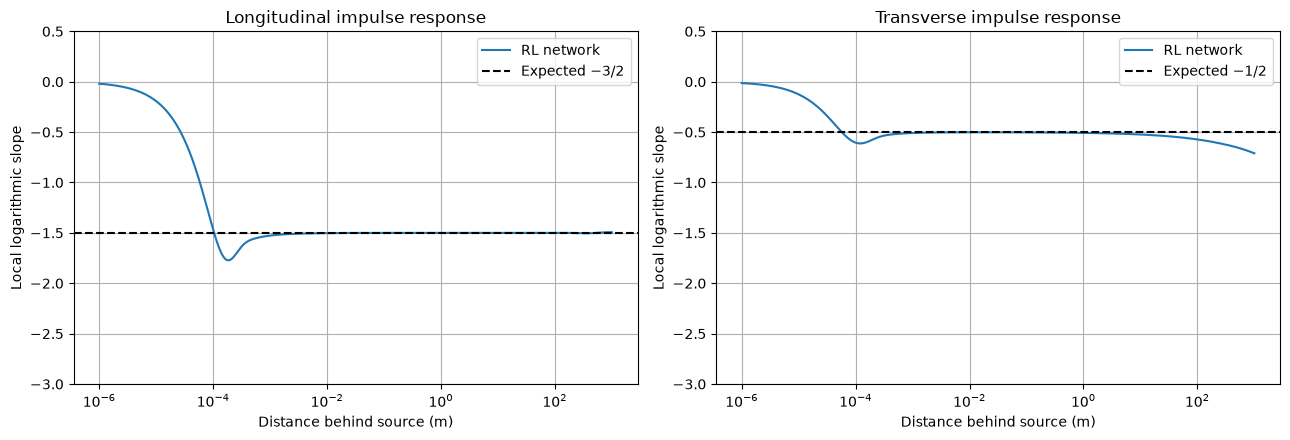

In [55]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.constants import c

# Distance behind the source particle
z_plot = np.logspace(-6, 3, 1500)
t_plot = z_plot / (beta_rel * c)

def impulse_response_and_slope(poles, residues, t):
    poles = np.asarray(poles)
    residues = np.asarray(residues)

    exponentials = np.exp(poles[:, None] * t[None, :])
    terms = residues[:, None] * exponentials

    h = np.sum(terms, axis=0)
    dh_dt = np.sum(poles[:, None] * terms, axis=0)

    slope = np.divide(
        t * dh_dt,
        h,
        out=np.full_like(t, np.nan),
        where=np.abs(h) > 1e-280,
    )

    return h, slope


h_long_plot, slope_long_plot = impulse_response_and_slope(
    p_long, r_long, t_plot
)

h_trans_plot, slope_trans_plot = impulse_response_and_slope(
    p_trans, r_trans, t_plot
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].semilogx(z_plot, slope_long_plot, label="RL network")
axes[0].axhline(-1.5, color="black", linestyle="--",
                label=r"Expected $-3/2$")
axes[0].set_title("Longitudinal impulse response")

axes[1].semilogx(z_plot, slope_trans_plot, label="RL network")
axes[1].axhline(-0.5, color="black", linestyle="--",
                label=r"Expected $-1/2$")
axes[1].set_title("Transverse impulse response")

for ax in axes:
    ax.set_xlabel("Distance behind source (m)")
    ax.set_ylabel("Local logarithmic slope")
    ax.set_ylim(-3, 0.5)
    ax.grid(True, which="both")
    ax.legend()

plt.tight_layout()
plt.show()

Longitudinal amplitude ratio: 0.998991
Transverse amplitude ratio:   0.994057


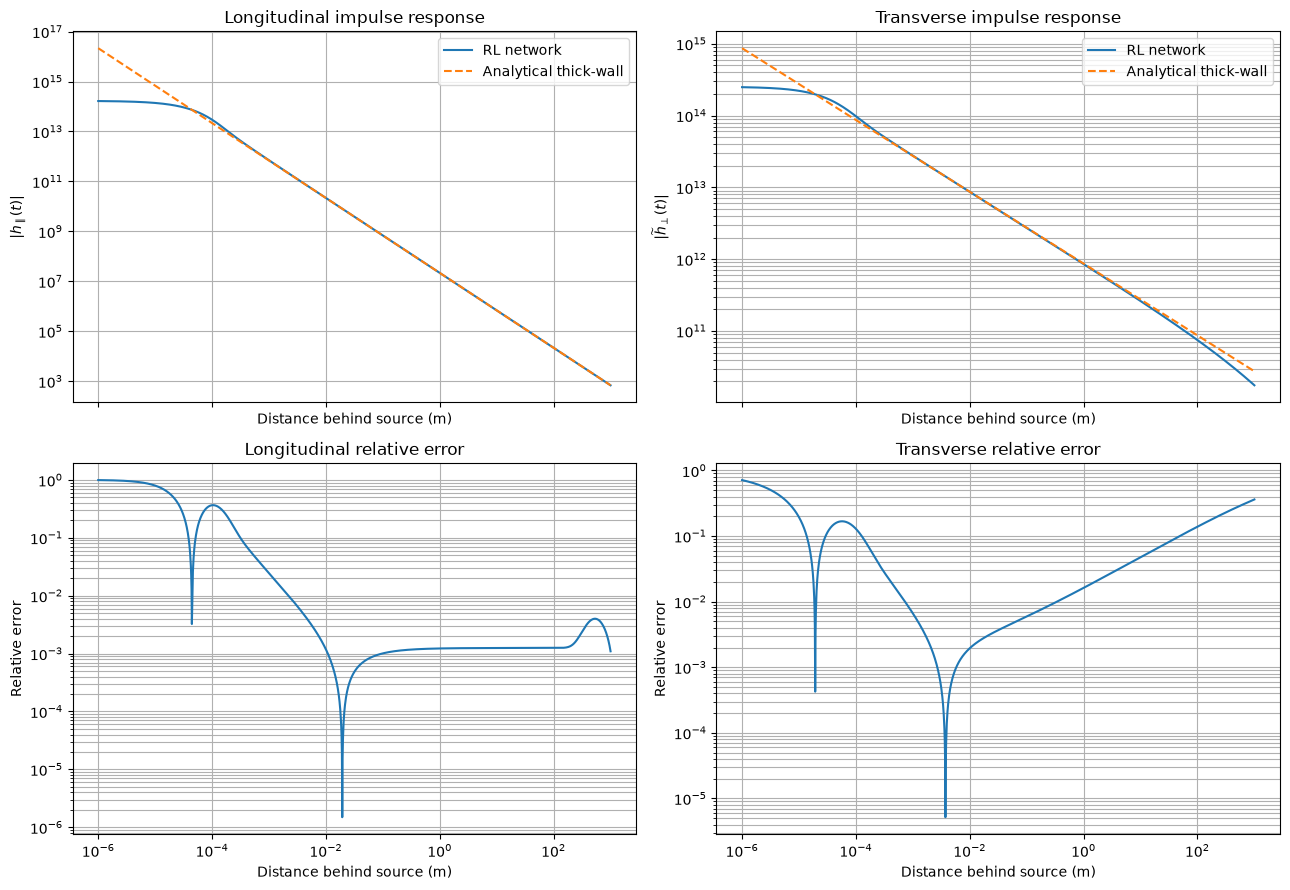

In [59]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.constants import mu_0, c

# ------------------------------------------------------------
# Material parameters
# ------------------------------------------------------------

# Actual material parameters from the PyTLWall SPS example
sigma_wall = float(sps_wall.chamber.layers[0]._sigmaDC)
mu_wall = float(np.real(sps_wall.chamber.layers[0].mu[0]))

# Correct analytical prefactor
A_long = (
    length / (2.0 * np.pi * b)
    * np.sqrt(mu_wall / sigma_wall)
)

K_trans = 2.0 * beta_rel * c / b**2

# Analytical thick-wall impulse responses
h_long_analytic = (
    -A_long / (2.0 * np.sqrt(np.pi))
    * t_plot**(-1.5)
)

h_trans_analytic = (
    K_trans * A_long / np.sqrt(np.pi)
    * t_plot**(-0.5)
)

# Updated amplitude ratios
ratio_long = h_long_plot / h_long_analytic
ratio_trans = h_trans_plot / h_trans_analytic

fit_range = (z_plot >= 1e-2) & (z_plot <= 1.0)

print(f"Longitudinal amplitude ratio: {np.median(ratio_long[fit_range]):.6f}")
print(f"Transverse amplitude ratio:   {np.median(ratio_trans[fit_range]):.6f}")

# ------------------------------------------------------------
# Relative errors
# ------------------------------------------------------------

err_long = (
    np.abs(h_long_plot - h_long_analytic)
    / np.abs(h_long_analytic)
)

err_trans = (
    np.abs(h_trans_plot - h_trans_analytic)
    / np.abs(h_trans_analytic)
)

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharex=True)

axes[0, 0].loglog(
    z_plot, np.abs(h_long_plot),
    label="RL network"
)
axes[0, 0].loglog(
    z_plot, np.abs(h_long_analytic), "--",
    label="Analytical thick-wall"
)
axes[0, 0].set_title("Longitudinal impulse response")
axes[0, 0].set_ylabel(r"$|h_\parallel(t)|$")

axes[0, 1].loglog(
    z_plot, np.abs(h_trans_plot),
    label="RL network"
)
axes[0, 1].loglog(
    z_plot, np.abs(h_trans_analytic), "--",
    label="Analytical thick-wall"
)
axes[0, 1].set_title("Transverse impulse response")
axes[0, 1].set_ylabel(r"$|\widetilde h_\perp(t)|$")

axes[1, 0].loglog(z_plot, err_long)
axes[1, 0].set_title("Longitudinal relative error")
axes[1, 0].set_ylabel("Relative error")

axes[1, 1].loglog(z_plot, err_trans)
axes[1, 1].set_title("Transverse relative error")
axes[1, 1].set_ylabel("Relative error")

for ax in axes.flat:
    ax.set_xlabel("Distance behind source (m)")
    ax.grid(True, which="both")

for ax in axes[0]:
    ax.legend()

plt.tight_layout()
plt.show()

In [57]:
# Inspect material parameters of the PyTLWall chamber
for i, layer in enumerate(sps_wall.chamber.layers):
    print(f"\nLayer {i}:")
    print(f"  Type:         {layer.layer_type}")
    print(f"  Conductivity: {getattr(layer, 'sigma', 'not available')}")
    print(f"  Permeability: {getattr(layer, 'mu', 'not available')}")
    print(f"  Permittivity: {getattr(layer, 'epsilon', 'not available')}")
    print(f"  Thickness:    {getattr(layer, 'thickness', 'not available')}")


Layer 0:
  Type:         CW
  Conductivity: not available
  Permeability: [1.25663706e-06+0.j 1.25663706e-06+0.j 1.25663706e-06+0.j ...
 1.25663706e-06+0.j 1.25663706e-06+0.j 1.25663706e-06+0.j]
  Permittivity: not available
  Thickness:    not available


In [58]:
layer = sps_wall.chamber.layers[0]

for name, value in vars(layer).items():
    if isinstance(value, np.ndarray):
        print(f"{name}: shape={value.shape}, first={value.flat[0]}")
    else:
        print(f"{name}: {value}")

_thick_m: 0.002
_muinf_Hz: 0.0
_epsr: 1.0
_sigmaDC: 1450000.0
_k_Hz: inf
_tau: 0.0
_RQ: 0.0
_freq_Hz: shape=(1440,), first=0.11000000000000001
_layer_type: CW
_KZ: None


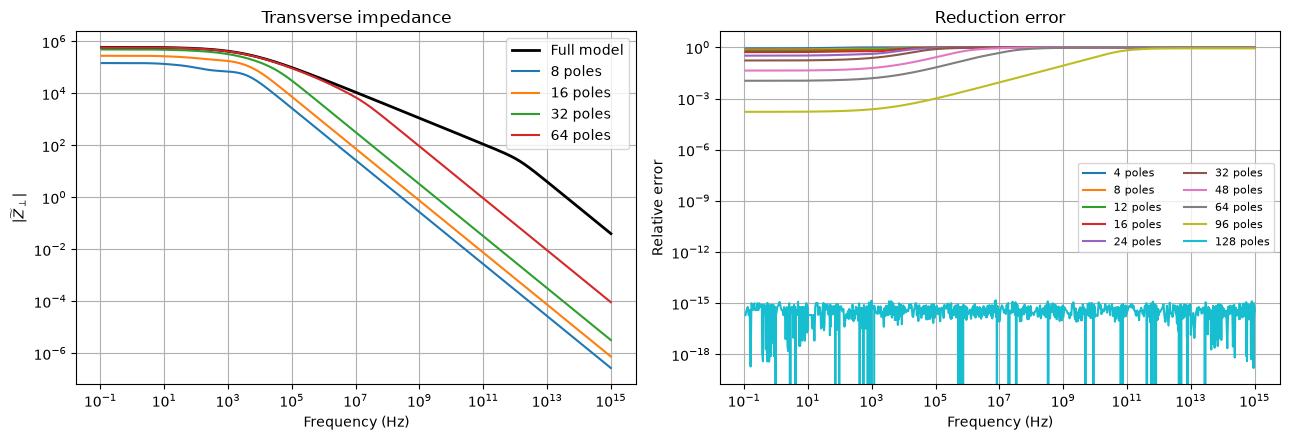

Model order | Maximum relative error
----------------------------------------
          4 | 1.000e+00
          8 | 9.999e-01
         12 | 9.999e-01
         16 | 9.998e-01
         24 | 9.997e-01
         32 | 9.994e-01
         48 | 9.964e-01
         64 | 9.817e-01
         96 | 2.701e-01
        128 | 1.476e-15


In [60]:
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Transverse modal truncation
# ------------------------------------------------------------

p_full = np.asarray(p_trans_red, dtype=float)
r_full = np.asarray(r_trans_red, dtype=float)

# Remove numerically zero residues
active = (p_full < 0.0) & (r_full > 0.0)
p_full = p_full[active]
r_full = r_full[active]

# Modal importance: DC contribution
importance = r_full / np.abs(p_full)

# Sort modes by descending importance
ranking = np.argsort(importance)[::-1]

# Frequency evaluation
freq = np.asarray(f)
s = 1j * 2.0 * np.pi * freq

# Full transverse base impedance (without the conventional factor j)
Z_full = np.sum(
    r_full[:, None] / (s[None, :] - p_full[:, None]),
    axis=0,
)

# Candidate model orders
orders = [4, 8, 12, 16, 24, 32, 48, 64, 96, 128]

# Evaluate within the intended network frequency range
valid = (freq >= FNET_MIN) & (freq <= FNET_MAX)

results = {}

for order in orders:
    if order > len(p_full):
        continue

    selected = ranking[:order]

    p_red = p_full[selected]
    r_red = r_full[selected]

    Z_red = np.sum(
        r_red[:, None] / (s[None, :] - p_red[:, None]),
        axis=0,
    )

    error = (
        np.abs(Z_red - Z_full)
        / np.maximum(np.abs(Z_full), 1e-30)
    )

    results[order] = {
        "poles": p_red,
        "residues": r_red,
        "Z": Z_red,
        "error": error,
        "max_error": np.max(error[valid]),
    }

# ------------------------------------------------------------
# Plot impedance comparison
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].loglog(
    freq, np.abs(Z_full),
    "k", linewidth=2, label="Full model"
)

for order in [8, 16, 32, 64]:
    if order in results:
        axes[0].loglog(
            freq,
            np.abs(results[order]["Z"]),
            label=f"{order} poles",
        )

axes[0].set_xlabel("Frequency (Hz)")
axes[0].set_ylabel(r"$|\widetilde Z_\perp|$")
axes[0].set_title("Transverse impedance")
axes[0].grid(True, which="both")
axes[0].legend()

for order, data in results.items():
    axes[1].loglog(
        freq,
        data["error"],
        label=f"{order} poles",
    )

axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("Relative error")
axes[1].set_title("Reduction error")
axes[1].grid(True, which="both")
axes[1].legend(ncol=2, fontsize=8)

plt.tight_layout()
plt.show()

print("Model order | Maximum relative error")
print("-" * 40)

for order, data in results.items():
    print(f"{order:11d} | {data['max_error']:.3e}")

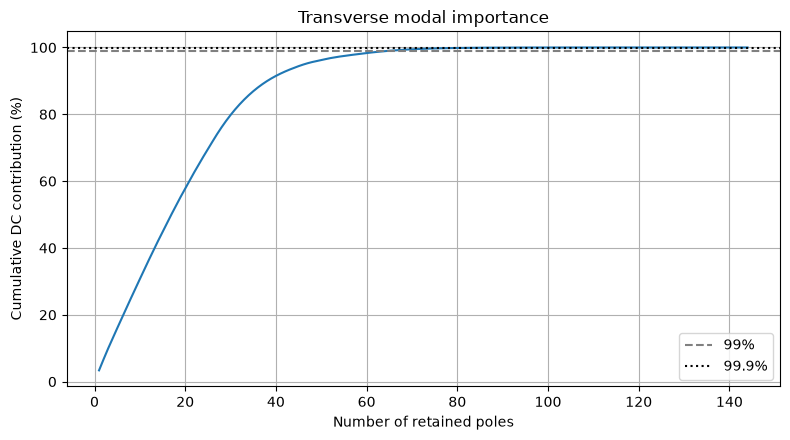

99.00% DC contribution: 65 poles
99.90% DC contribution: 83 poles
99.99% DC contribution: 99 poles


In [61]:
importance_sorted = importance[ranking]

cumulative = np.cumsum(importance_sorted)
cumulative /= cumulative[-1]

fig, ax = plt.subplots(figsize=(8, 4.5))

ax.plot(
    np.arange(1, len(cumulative) + 1),
    cumulative * 100,
)

ax.axhline(99, linestyle="--", color="gray", label="99%")
ax.axhline(99.9, linestyle=":", color="black", label="99.9%")

ax.set_xlabel("Number of retained poles")
ax.set_ylabel("Cumulative DC contribution (%)")
ax.set_title("Transverse modal importance")
ax.grid(True)
ax.legend()

plt.tight_layout()
plt.show()

for threshold in [0.99, 0.999, 0.9999]:
    n_required = np.searchsorted(cumulative, threshold) + 1
    print(
        f"{threshold * 100:.2f}% DC contribution: "
        f"{n_required} poles"
    )

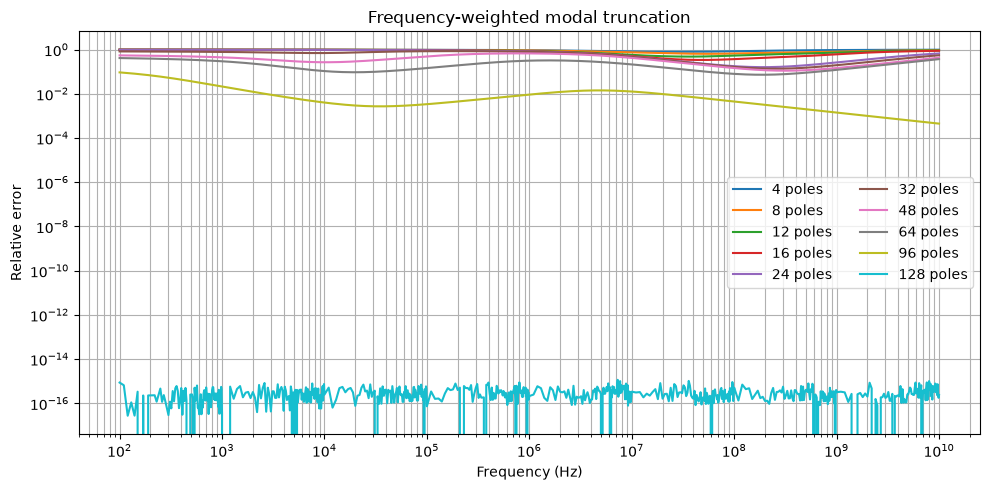

Model order | Maximum relative error
----------------------------------------
          4 | 9.949e-01
          8 | 9.929e-01
         12 | 9.879e-01
         16 | 9.855e-01
         24 | 9.839e-01
         32 | 8.517e-01
         48 | 6.733e-01
         64 | 4.143e-01
         96 | 9.312e-02
        128 | 1.163e-15


In [62]:
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Frequency-weighted modal importance
# ------------------------------------------------------------

p_full = np.asarray(p_trans_red, dtype=float)
r_full = np.asarray(r_trans_red, dtype=float)

active = (p_full < 0.0) & (r_full > 0.0)
p_full = p_full[active]
r_full = r_full[active]

freq = np.asarray(f)
valid = (freq >= FNET_MIN) & (freq <= FNET_MAX)

freq_eval = freq[valid]
s_eval = 1j * 2.0 * np.pi * freq_eval

# Individual modal contributions
Z_modes = (
    r_full[:, None]
    / (s_eval[None, :] - p_full[:, None])
)

Z_reference = np.sum(Z_modes, axis=0)

# Relative modal contributions across the frequency range
relative_modes = (
    np.abs(Z_modes)
    / np.maximum(np.abs(Z_reference)[None, :], 1e-30)
)

# RMS importance over the frequency grid
importance_freq = np.sqrt(
    np.mean(relative_modes**2, axis=1)
)

ranking_freq = np.argsort(importance_freq)[::-1]

# ------------------------------------------------------------
# Compare reduced models
# ------------------------------------------------------------

orders = [4, 8, 12, 16, 24, 32, 48, 64, 96, 128]

results_freq = {}

for order in orders:
    if order > len(p_full):
        continue

    selected = ranking_freq[:order]

    Z_reduced = np.sum(
        Z_modes[selected],
        axis=0
    )

    error = (
        np.abs(Z_reduced - Z_reference)
        / np.maximum(np.abs(Z_reference), 1e-30)
    )

    results_freq[order] = {
        "poles": p_full[selected],
        "residues": r_full[selected],
        "max_error": np.max(error),
        "error": error,
    }

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 5))

for order, data in results_freq.items():
    ax.loglog(
        freq_eval,
        data["error"],
        label=f"{order} poles"
    )

ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Relative error")
ax.set_title("Frequency-weighted modal truncation")
ax.grid(True, which="both")
ax.legend(ncol=2)

plt.tight_layout()
plt.show()

print("Model order | Maximum relative error")
print("-" * 40)

for order, data in results_freq.items():
    print(f"{order:11d} | {data['max_error']:.3e}")

In [64]:
import numpy as np
from scipy.linalg import eigh

# ------------------------------------------------------------
# Exact controllability/observability Gramian in modal basis
# ------------------------------------------------------------

p = np.asarray(p_trans_red, dtype=float)
r = np.asarray(r_trans_red, dtype=float)

active = (p < 0.0) & (r > 0.0)
p = p[active]
r = r[active]

B = np.sqrt(r)

# Symmetric positive semidefinite Gramian
W = (
    B[:, None] * B[None, :]
    / (-p[:, None] - p[None, :])
)

W = 0.5 * (W + W.T)

hsv, V = eigh(W)

idx = np.argsort(hsv)[::-1]
hsv = hsv[idx]
V = V[:, idx]

print(f"Largest HSV: {hsv[0]:.6e}")
print(f"Smallest HSV: {hsv[-1]:.6e}")
print(f"Negative HSVs: {np.sum(hsv < 0)}")

# Reduced models
orders = [8, 12, 16, 24, 32, 48, 64]

freq_eval = np.asarray(f)
s_eval = 1j * 2 * np.pi * freq_eval

Z_full = np.sum(
    r[:, None] / (s_eval[None, :] - p[:, None]),
    axis=0,
)

valid = (freq_eval >= FNET_MIN) & (freq_eval <= FNET_MAX)

results_modal_bt = {}

for n in orders:
    Vn = V[:, :n]

    Ar = Vn.T @ np.diag(p) @ Vn
    Br = Vn.T @ B

    poles_r, Ur = eigh(Ar)
    residues_r = (Ur.T @ Br)**2

    Z_red = np.sum(
        residues_r[:, None] /
        (s_eval[None, :] - poles_r[:, None]),
        axis=0,
    )

    err = (
        np.abs(Z_red - Z_full)
        / np.maximum(np.abs(Z_full), 1e-30)
    )

    results_modal_bt[n] = {
        "poles": poles_r,
        "residues": residues_r,
        "max_error": np.max(err[valid]),
    }

print("\nModel order | Maximum relative error")
print("-" * 40)

for n, result in results_modal_bt.items():
    print(f"{n:11d} | {result['max_error']:.3e}")

Largest HSV: 1.662786e+05
Smallest HSV: -2.721727e-13
Negative HSVs: 15

Model order | Maximum relative error
----------------------------------------
          8 | 8.977e-01
         12 | 4.825e-01
         16 | 7.123e-02
         24 | 3.165e-03
         32 | 1.270e-04
         48 | 1.468e-07
         64 | 1.930e-08


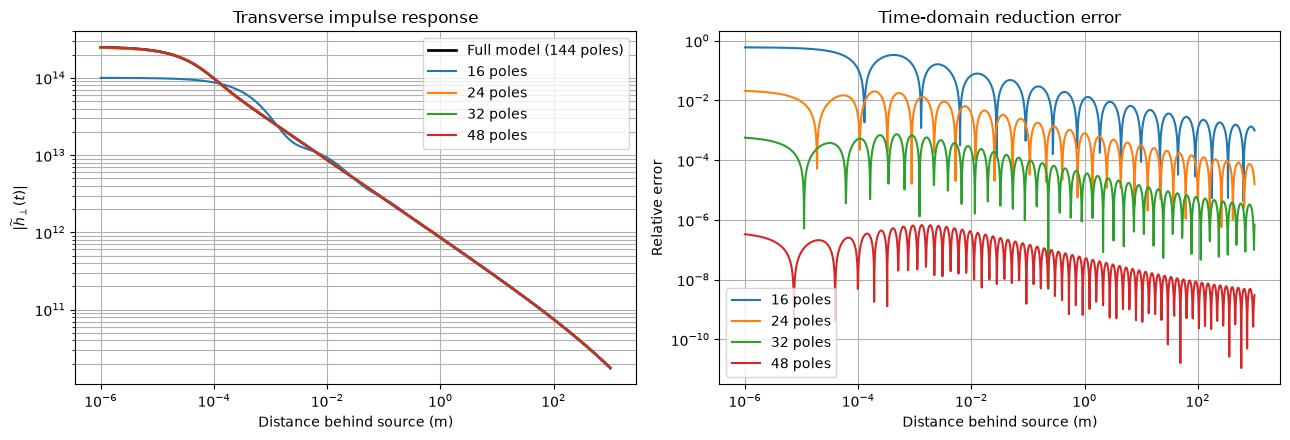

Model order | Max. time-domain error
------------------------------------------
         16 | 5.972e-01
         24 | 2.085e-02
         32 | 7.379e-04
         48 | 6.675e-07


In [65]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.constants import c

# ------------------------------------------------------------
# Time-domain validation of reduced transverse models
# ------------------------------------------------------------

# Distance behind the source particle
z_wake = np.logspace(-6, 3, 2000)
t_wake = z_wake / (beta_rel * c)

# Full transverse pole-residue model
p_full = np.asarray(p_trans_red, dtype=float)
r_full = np.asarray(r_trans_red, dtype=float)

def evaluate_impulse_response(poles, residues, time):
    """Evaluate the causal impulse response for positive times."""
    poles = np.asarray(poles, dtype=float)
    residues = np.asarray(residues, dtype=float)

    return np.sum(
        residues[:, None]
        * np.exp(poles[:, None] * time[None, :]),
        axis=0,
    )

h_full = evaluate_impulse_response(
    p_full, r_full, t_wake
)

# Reduced models
orders_wake = [16, 24, 32, 48]

wake_results = {}

for n in orders_wake:
    model = results_modal_bt[n]

    h_reduced = evaluate_impulse_response(
        model["poles"],
        model["residues"],
        t_wake,
    )

    relative_error = (
        np.abs(h_reduced - h_full)
        / np.maximum(np.abs(h_full), 1e-30)
    )

    wake_results[n] = {
        "h": h_reduced,
        "error": relative_error,
    }

# ------------------------------------------------------------
# Plot impulse responses and relative errors
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].loglog(
    z_wake, np.abs(h_full),
    "k", linewidth=2, label="Full model (144 poles)"
)

for n, result in wake_results.items():
    axes[0].loglog(
        z_wake,
        np.abs(result["h"]),
        label=f"{n} poles",
    )

axes[0].set_xlabel("Distance behind source (m)")
axes[0].set_ylabel(r"$|\widetilde h_\perp(t)|$")
axes[0].set_title("Transverse impulse response")
axes[0].grid(True, which="both")
axes[0].legend()

for n, result in wake_results.items():
    axes[1].loglog(
        z_wake,
        result["error"],
        label=f"{n} poles",
    )

axes[1].set_xlabel("Distance behind source (m)")
axes[1].set_ylabel("Relative error")
axes[1].set_title("Time-domain reduction error")
axes[1].grid(True, which="both")
axes[1].legend()

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Error summary
# ------------------------------------------------------------

print("Model order | Max. time-domain error")
print("-" * 42)

for n, result in wake_results.items():
    print(
        f"{n:11d} | "
        f"{np.max(result['error']):.3e}"
    )

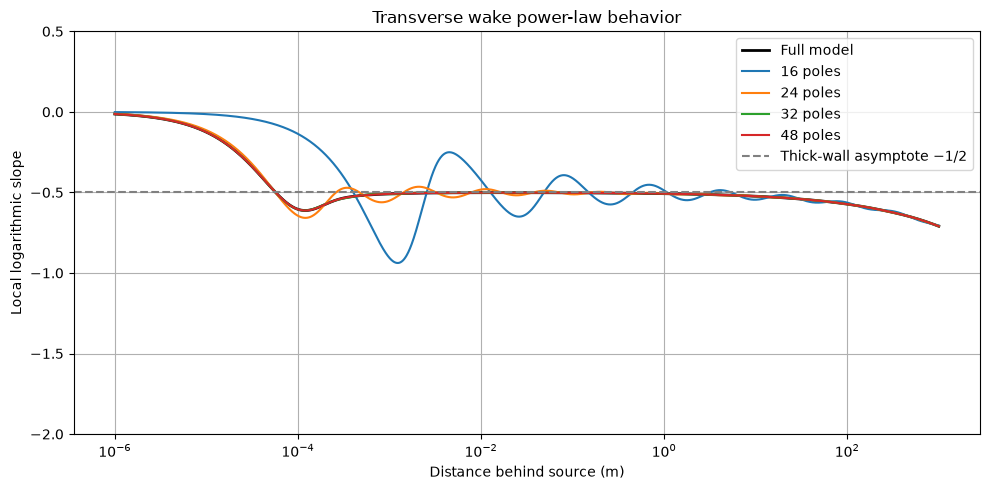

In [66]:
def impulse_log_slope(poles, residues, time):
    """Compute the exact local logarithmic slope."""
    poles = np.asarray(poles, dtype=float)
    residues = np.asarray(residues, dtype=float)

    terms = (
        residues[:, None]
        * np.exp(poles[:, None] * time[None, :])
    )

    h = np.sum(terms, axis=0)
    dh_dt = np.sum(poles[:, None] * terms, axis=0)

    return np.divide(
        time * dh_dt,
        h,
        out=np.full_like(time, np.nan),
        where=np.abs(h) > 1e-280,
    )

fig, ax = plt.subplots(figsize=(10, 5))

slope_full = impulse_log_slope(
    p_full, r_full, t_wake
)

ax.semilogx(
    z_wake, slope_full,
    "k", linewidth=2, label="Full model"
)

for n in orders_wake:
    model = results_modal_bt[n]

    slope_reduced = impulse_log_slope(
        model["poles"],
        model["residues"],
        t_wake,
    )

    ax.semilogx(
        z_wake,
        slope_reduced,
        label=f"{n} poles",
    )

ax.axhline(
    -0.5, color="gray", linestyle="--",
    label=r"Thick-wall asymptote $-1/2$"
)

ax.set_xlabel("Distance behind source (m)")
ax.set_ylabel("Local logarithmic slope")
ax.set_title("Transverse wake power-law behavior")
ax.set_ylim(-2, 0.5)
ax.grid(True, which="both")
ax.legend()

plt.tight_layout()
plt.show()

In [67]:
print("Model order | Max. time-domain error")
print("-" * 42)

for n, result in wake_results.items():
    print(f"{n:11d} | {np.max(result['error']):.3e}")

Model order | Max. time-domain error
------------------------------------------
         16 | 5.972e-01
         24 | 2.085e-02
         32 | 7.379e-04
         48 | 6.675e-07


In [72]:
import numpy as np
from scipy.constants import c

# Distance behind the source particle
z = np.logspace(-6, 3, 2000)
t = z / (beta_rel * c)

# Longitudinal pole-residue impulse response
p = np.real(np.asarray(poles_long))
r = np.real(np.asarray(residues_long))

h_long_PR = np.sum(
    r[:, None] * np.exp(p[:, None] * t[None, :]),
    axis=0,
)

Frequency range: 1.100e-01 to 1.000e+15 Hz
Number of samples: 1440


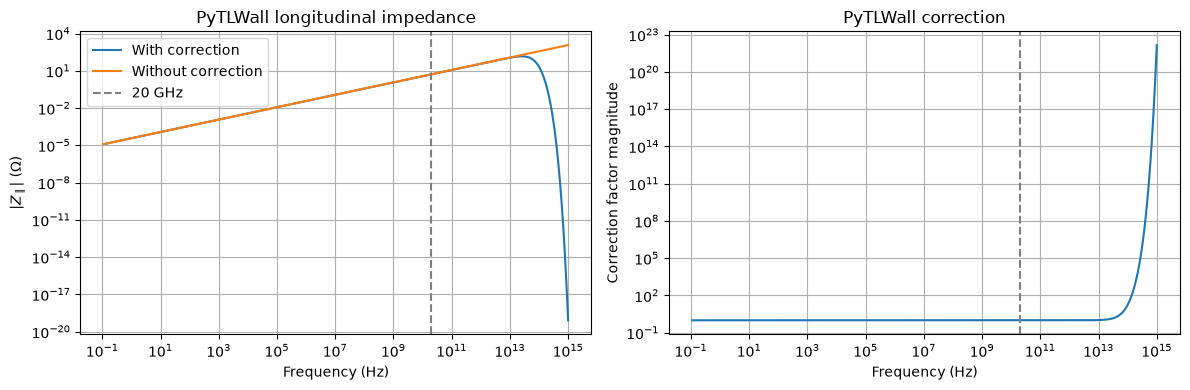

In [73]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.constants import c

# ------------------------------------------------------------
# PyTLWall frequency data
# ------------------------------------------------------------

freq_wall = np.asarray(sps_wall.f, dtype=float).ravel()

# Corrected longitudinal impedance from PyTLWall
Z_corr = np.asarray(
    sps_wall.calc_ZLong(), dtype=complex
).ravel()

# Correction factor: Z_corrected = Z_uncorrected / corr_imp
corr = np.asarray(sps_wall._corr_imp, dtype=complex)

if corr.ndim == 0:
    corr = np.full_like(freq_wall, corr, dtype=complex)
else:
    corr = corr.ravel()

assert len(freq_wall) == len(Z_corr) == len(corr)
assert np.all(np.isfinite(freq_wall))
assert np.all(np.diff(freq_wall) > 0)
assert np.all(np.isfinite(Z_corr))
assert np.all(np.isfinite(corr))

Z_uncorr = Z_corr * corr

print(f"Frequency range: {freq_wall[0]:.3e} to {freq_wall[-1]:.3e} Hz")
print(f"Number of samples: {len(freq_wall)}")

# ------------------------------------------------------------
# Inspect the correction
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].loglog(freq_wall, np.abs(Z_corr),
               label="With correction")
axes[0].loglog(freq_wall, np.abs(Z_uncorr),
               label="Without correction")
axes[0].axvline(20e9, color="gray", linestyle="--",
                label="20 GHz")
axes[0].set_xlabel("Frequency (Hz)")
axes[0].set_ylabel(r"$|Z_\parallel|$ ($\Omega$)")
axes[0].set_title("PyTLWall longitudinal impedance")
axes[0].legend()
axes[0].grid(True, which="both")

axes[1].loglog(freq_wall, np.abs(corr))
axes[1].axvline(20e9, color="gray", linestyle="--")
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("Correction factor magnitude")
axes[1].set_title("PyTLWall correction")
axes[1].grid(True, which="both")

plt.tight_layout()
plt.show()

In [74]:
def inverse_fourier_linear(freq, impedance, time, chunk_size=128):
    """
    Numerically invert a one-sided impedance spectrum.

    Uses exact Fourier integration of piecewise-linear
    interpolation segments.

    Convention:
        Z(f) = integral h(t) exp(-2j*pi*f*t) dt

        h(t) = 2*Re integral_0^infinity
               Z(f) exp(+2j*pi*f*t) df

    Parameters
    ----------
    freq : array
        Nonnegative frequencies in Hz, strictly increasing.
    impedance : array
        Complex impedance at the frequency samples.
    time : array
        Evaluation times in seconds.
    chunk_size : int
        Number of time points processed per batch.

    Returns
    -------
    h : array
        Real-valued band-limited impulse response.
    """
    freq = np.asarray(freq, dtype=float)
    impedance = np.asarray(impedance, dtype=complex)
    time = np.asarray(time, dtype=float)

    assert np.all(np.diff(freq) > 0)
    assert freq[0] >= 0
    assert len(freq) == len(impedance)

    df = np.diff(freq)
    fm = 0.5 * (freq[:-1] + freq[1:])

    Zm = 0.5 * (impedance[:-1] + impedance[1:])
    dZ = np.diff(impedance)

    result = np.empty_like(time)

    for start in range(0, len(time), chunk_size):
        stop = min(start + chunk_size, len(time))
        tt = time[start:stop, None]

        q = np.pi * tt * df[None, :]

        sinc = np.sinc(q / np.pi)

        # Stable evaluation of (sin(q) - q*cos(q))/q**2
        kernel = np.empty_like(q)
        small = np.abs(q) < 1e-3

        qs = q[small]
        kernel[small] = (
            qs / 3.0
            - qs**3 / 30.0
            + qs**5 / 840.0
        )

        ql = q[~small]
        kernel[~small] = (
            np.sin(ql) - ql * np.cos(ql)
        ) / ql**2

        phase = np.exp(2j * np.pi * tt * fm[None, :])

        integrals = (
            df[None, :]
            * phase
            * (Zm[None, :] * sinc
               + 0.5j * dZ[None, :] * kernel)
        )

        result[start:stop] = 2.0 * np.real(
            np.sum(integrals, axis=1)
        )

    return result

In [75]:
from scipy.constants import c

# ------------------------------------------------------------
# Evaluation distances
# ------------------------------------------------------------

z_wake = np.logspace(-5, 2, 700)
t_wake = z_wake / (beta_rel * c)

f_cut = 20e9

# ------------------------------------------------------------
# Include DC and exact frequency cutoff
# ------------------------------------------------------------

def prepare_spectrum(freq, Z, f_max):
    """Prepare a one-sided spectrum on [0, f_max]."""
    freq = np.asarray(freq, dtype=float)
    Z = np.asarray(Z, dtype=complex)

    if not (freq[0] < f_max <= freq[-1]):
        raise ValueError("Frequency cutoff outside input range.")

    # Linear interpolation at the upper cutoff
    Z_end = (
        np.interp(f_max, freq, Z.real)
        + 1j * np.interp(f_max, freq, Z.imag)
    )

    mask = (freq > 0) & (freq < f_max)

    # Resistive-wall DC limit: Z(0) = 0
    freq_out = np.concatenate(([0.0], freq[mask], [f_max]))
    Z_out = np.concatenate(([0.0j], Z[mask], [Z_end]))

    return freq_out, Z_out


# ------------------------------------------------------------
# PyTLWall inverse Fourier transforms
# ------------------------------------------------------------

cases = {
    "PyTLWall corrected, 20 GHz": (Z_corr, f_cut),
    "PyTLWall uncorrected, 20 GHz": (Z_uncorr, f_cut),
    "PyTLWall corrected, full": (Z_corr, freq_wall[-1]),
    "PyTLWall uncorrected, full": (Z_uncorr, freq_wall[-1]),
}

wake_pytlwall = {}

for name, (Z, cutoff) in cases.items():
    freq_case, Z_case = prepare_spectrum(
        freq_wall, Z, cutoff
    )

    wake_pytlwall[name] = inverse_fourier_linear(
        freq_case, Z_case, t_wake
    )

    print(f"Computed: {name}")


# ------------------------------------------------------------
# Analytical pole-residue wake: NO Fourier transform
# ------------------------------------------------------------

p = np.asarray(poles_long)
r = np.asarray(residues_long)

# Check whether the modal data are effectively real
assert np.max(np.abs(p.imag)) < 1e-8 * max(
    np.max(np.abs(p)), 1.0
)
assert np.max(np.abs(r.imag)) < 1e-8 * max(
    np.max(np.abs(r)), 1.0
)

p = p.real
r = r.real

h_pr = np.sum(
    r[:, None] * np.exp(p[:, None] * t_wake[None, :]),
    axis=0
)

# Use the CERN longitudinal wake sign convention
W_pr = -h_pr
W_pytlwall = {
    name: -values
    for name, values in wake_pytlwall.items()
}

Computed: PyTLWall corrected, 20 GHz
Computed: PyTLWall uncorrected, 20 GHz
Computed: PyTLWall corrected, full
Computed: PyTLWall uncorrected, full


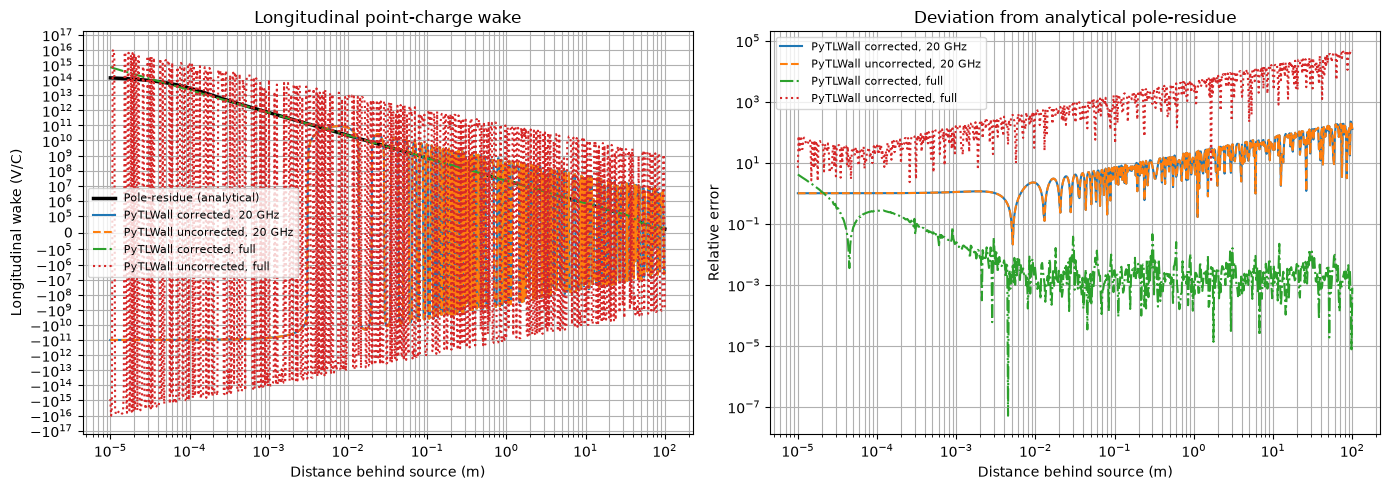

In [76]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

styles = {
    "PyTLWall corrected, 20 GHz": "-",
    "PyTLWall uncorrected, 20 GHz": "--",
    "PyTLWall corrected, full": "-.",
    "PyTLWall uncorrected, full": ":",
}

# ------------------------------------------------------------
# Wake comparison
# ------------------------------------------------------------

axes[0].semilogx(
    z_wake, W_pr,
    color="black",
    linewidth=2.5,
    label="Pole-residue (analytical)"
)

for name, values in W_pytlwall.items():
    axes[0].semilogx(
        z_wake, values,
        linestyle=styles[name],
        label=name
    )

axes[0].set_yscale("symlog", linthresh=1e5)
axes[0].set_xlabel("Distance behind source (m)")
axes[0].set_ylabel("Longitudinal wake (V/C)")
axes[0].set_title("Longitudinal point-charge wake")
axes[0].grid(True, which="both")
axes[0].legend(fontsize=8)

# ------------------------------------------------------------
# Relative errors
# ------------------------------------------------------------

for name, values in W_pytlwall.items():
    error = (
        np.abs(values - W_pr)
        / np.maximum(np.abs(W_pr), 1e-30)
    )

    axes[1].loglog(
        z_wake, error,
        linestyle=styles[name],
        label=name
    )

axes[1].set_xlabel("Distance behind source (m)")
axes[1].set_ylabel("Relative error")
axes[1].set_title("Deviation from analytical pole-residue")
axes[1].grid(True, which="both")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

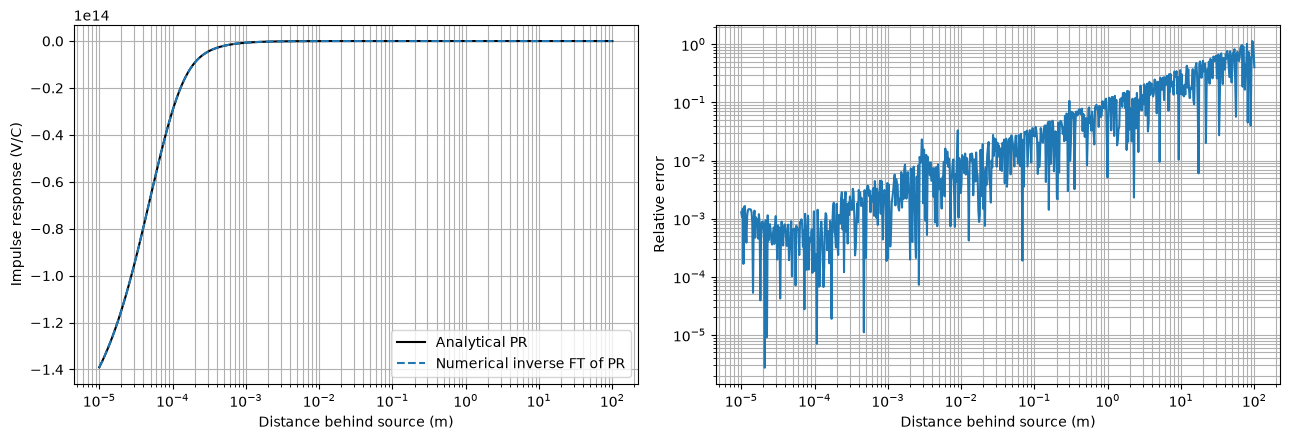

In [77]:
# ------------------------------------------------------------
# Validate numerical inverse Fourier transform
# using the known analytical pole-residue model
# ------------------------------------------------------------

s = 1j * 2.0 * np.pi * freq_wall

Z_pr_freq = (
    direct_long
    + np.sum(
        r[:, None] / (s[None, :] - p[:, None]),
        axis=0
    )
)

# Remove the direct term: its inverse transform is D*delta(t)
Z_pr_regular = Z_pr_freq - direct_long

freq_test, Z_test = prepare_spectrum(
    freq_wall,
    Z_pr_regular,
    freq_wall[-1]
)

# The regular part has a nonzero DC limit!
# Correct the DC value inserted by prepare_spectrum().
Z_test[0] = np.sum(-r / p)

h_pr_numerical = inverse_fourier_linear(
    freq_test,
    Z_test,
    t_wake
)

h_pr_exact = np.sum(
    r[:, None] * np.exp(p[:, None] * t_wake[None, :]),
    axis=0
)

rel_error = (
    np.abs(h_pr_numerical - h_pr_exact)
    / np.maximum(np.abs(h_pr_exact), 1e-30)
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].semilogx(
    z_wake, h_pr_exact,
    "k-", label="Analytical PR"
)
axes[0].semilogx(
    z_wake, h_pr_numerical,
    "--", label="Numerical inverse FT of PR"
)
axes[0].set_xlabel("Distance behind source (m)")
axes[0].set_ylabel("Impulse response (V/C)")
axes[0].grid(True, which="both")
axes[0].legend()

axes[1].loglog(z_wake, rel_error)
axes[1].set_xlabel("Distance behind source (m)")
axes[1].set_ylabel("Relative error")
axes[1].grid(True, which="both")

plt.tight_layout()
plt.show()

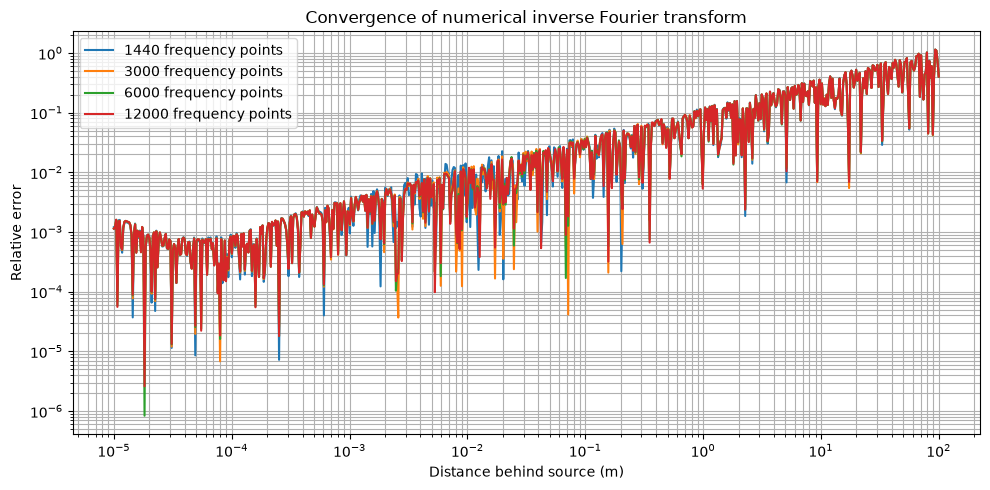

In [78]:
# ------------------------------------------------------------
# Convergence test of piecewise-linear inverse Fourier transform
# ------------------------------------------------------------

n_freq_list = [1440, 3000, 6000, 12000]

f_min = 0.1
f_max = 1e15

h_exact = np.sum(
    r[:, None] * np.exp(p[:, None] * t_wake[None, :]),
    axis=0
)

errors = {}

fig, ax = plt.subplots(figsize=(10, 5))

for n_freq in n_freq_list:

    freq_test = np.geomspace(f_min, f_max, n_freq)
    s_test = 1j * 2.0 * np.pi * freq_test

    # Evaluate the regular pole-residue impedance
    Z_regular = np.sum(
        r[:, None] / (s_test[None, :] - p[:, None]),
        axis=0
    )

    # Include the exact DC value
    freq_test = np.concatenate(([0.0], freq_test))
    Z_regular = np.concatenate((
        [np.sum(-r / p)],
        Z_regular
    ))

    h_numerical = inverse_fourier_linear(
        freq_test,
        Z_regular,
        t_wake
    )

    relative_error = (
        np.abs(h_numerical - h_exact)
        / np.maximum(np.abs(h_exact), 1e-30)
    )

    errors[n_freq] = relative_error

    ax.loglog(
        z_wake,
        relative_error,
        label=f"{n_freq} frequency points"
    )

ax.set_xlabel("Distance behind source (m)")
ax.set_ylabel("Relative error")
ax.set_title("Convergence of numerical inverse Fourier transform")
ax.grid(True, which="both")
ax.legend()

plt.tight_layout()
plt.show()

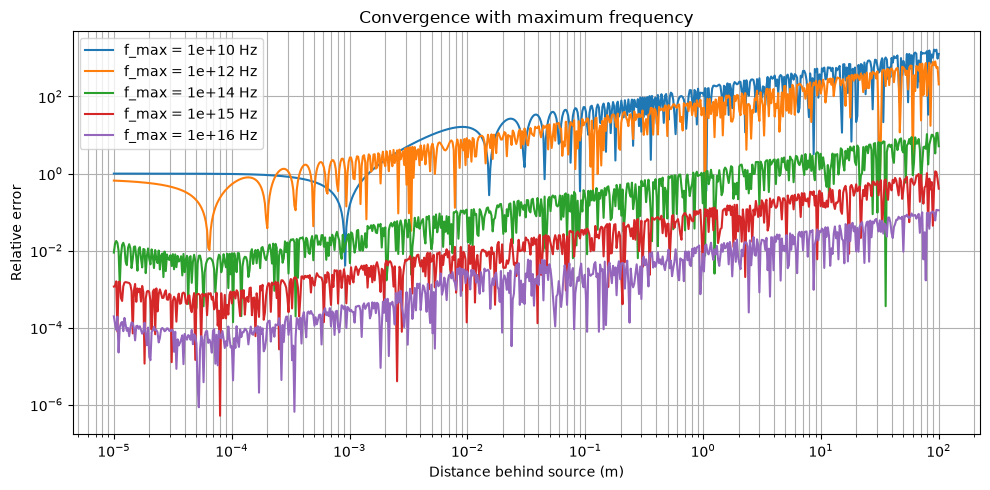

In [79]:
# ------------------------------------------------------------
# Convergence test with respect to maximum frequency
# ------------------------------------------------------------

f_max_list = [1e10, 1e12, 1e14, 1e15, 1e16]

f_min = 0.1
points_per_decade = 150

h_exact = np.sum(
    r[:, None] * np.exp(p[:, None] * t_wake[None, :]),
    axis=0
)

fig, ax = plt.subplots(figsize=(10, 5))

for f_max in f_max_list:

    n_freq = int(
        points_per_decade * np.log10(f_max / f_min)
    )

    freq_test = np.geomspace(f_min, f_max, n_freq)
    s_test = 1j * 2.0 * np.pi * freq_test

    Z_regular = np.sum(
        r[:, None] / (s_test[None, :] - p[:, None]),
        axis=0
    )

    freq_test = np.concatenate(([0.0], freq_test))
    Z_regular = np.concatenate((
        [np.sum(-r / p)],
        Z_regular
    ))

    h_numerical = inverse_fourier_linear(
        freq_test,
        Z_regular,
        t_wake
    )

    relative_error = (
        np.abs(h_numerical - h_exact)
        / np.maximum(np.abs(h_exact), 1e-30)
    )

    ax.loglog(
        z_wake,
        relative_error,
        label=f"f_max = {f_max:.0e} Hz"
    )

ax.set_xlabel("Distance behind source (m)")
ax.set_ylabel("Relative error")
ax.set_title("Convergence with maximum frequency")
ax.grid(True, which="both")
ax.legend()

plt.tight_layout()
plt.show()

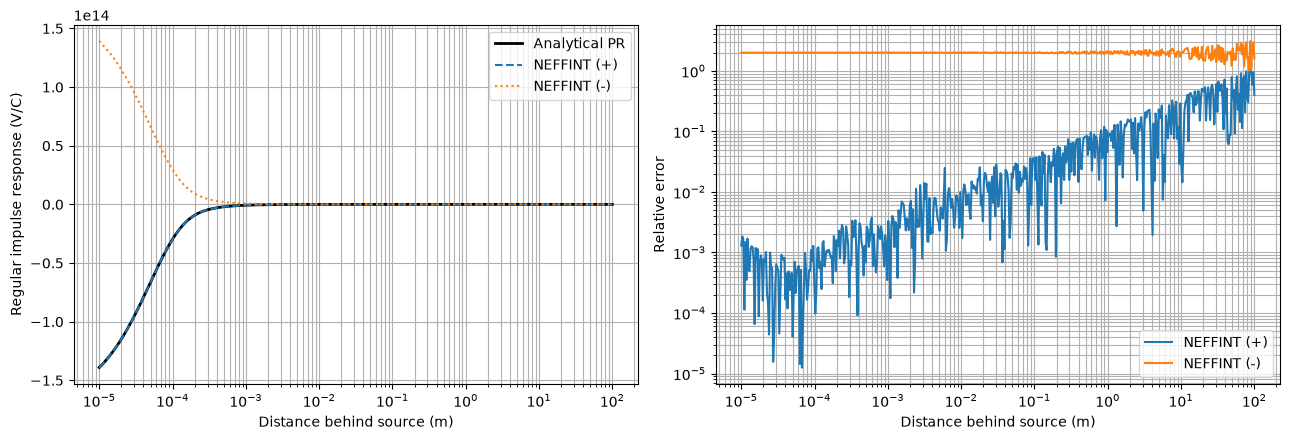

In [82]:
import numpy as np
import matplotlib.pyplot as plt
import iddefix

# ------------------------------------------------------------
# Analytical regular impulse response
# ------------------------------------------------------------

p = np.real(np.asarray(poles_long))
r = np.real(np.asarray(residues_long))

h_exact = np.sum(
    r[:, None] * np.exp(p[:, None] * t_test[None, :]),
    axis=0
)

# ------------------------------------------------------------
# Regular impedance: remove direct term D
# ------------------------------------------------------------

freq_test = np.concatenate(([0.0], freq_wall))
s_test = 1j * 2.0 * np.pi * freq_test

Z_regular = np.sum(
    r[:, None] / (s_test[None, :] - p[:, None]),
    axis=0
)

# ------------------------------------------------------------
# NEFFINT
# ------------------------------------------------------------

t_neffint, W_neffint = iddefix.compute_ineffint(
    freq_test,
    Z_regular,
    times=t_test,
    plane="longitudinal",
    adaptative=False,
)

t_neffint = np.asarray(t_neffint)
W_neffint = np.asarray(W_neffint)

# ------------------------------------------------------------
# Compare both possible sign conventions
# ------------------------------------------------------------

error_plus = np.abs(W_neffint - h_exact) / np.maximum(
    np.abs(h_exact), 1e-30
)

error_minus = np.abs(-W_neffint - h_exact) / np.maximum(
    np.abs(h_exact), 1e-30
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].semilogx(
    z_test, h_exact,
    "k-", linewidth=2, label="Analytical PR"
)

axes[0].semilogx(
    beta_rel * c * t_neffint,
    W_neffint,
    "--", label="NEFFINT (+)"
)

axes[0].semilogx(
    beta_rel * c * t_neffint,
    -W_neffint,
    ":", label="NEFFINT (-)"
)

axes[0].set_xlabel("Distance behind source (m)")
axes[0].set_ylabel("Regular impulse response (V/C)")
axes[0].grid(True, which="both")
axes[0].legend()

axes[1].loglog(
    z_test, error_plus,
    label="NEFFINT (+)"
)

axes[1].loglog(
    z_test, error_minus,
    label="NEFFINT (-)"
)

axes[1].set_xlabel("Distance behind source (m)")
axes[1].set_ylabel("Relative error")
axes[1].grid(True, which="both")
axes[1].legend()

plt.tight_layout()
plt.show()

Completed: Corrected, 20 GHz
Completed: Uncorrected, 20 GHz
Completed: Corrected, full
Completed: Uncorrected, full


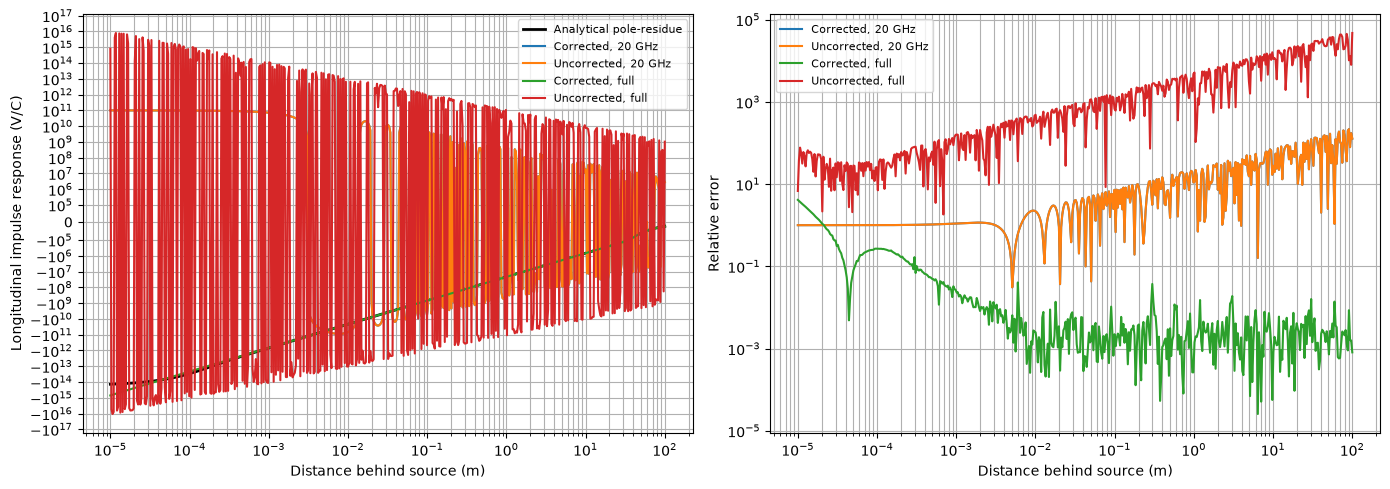

In [83]:
# ------------------------------------------------------------
# PyTLWall wakes using NEFFINT
# ------------------------------------------------------------

cases = {
    "Corrected, 20 GHz": (Z_corr, 20e9),
    "Uncorrected, 20 GHz": (Z_uncorr, 20e9),
    "Corrected, full": (Z_corr, freq_wall[-1]),
    "Uncorrected, full": (Z_uncorr, freq_wall[-1]),
}

wake_neffint = {}

for name, (Z, cutoff) in cases.items():

    freq_case, Z_case = prepare_spectrum(
        freq_wall, Z, cutoff
    )

    t_out, W_out = iddefix.compute_ineffint(
        freq_case,
        Z_case,
        times=t_test,
        plane="longitudinal",
        adaptative=False,
    )

    wake_neffint[name] = np.asarray(W_out)

    print(f"Completed: {name}")

# ------------------------------------------------------------
# Plot against analytical PR wake
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].semilogx(
    z_test, h_exact,
    "k-", linewidth=2,
    label="Analytical pole-residue"
)

for name, wake in wake_neffint.items():
    axes[0].semilogx(
        z_test, wake,
        label=name
    )

axes[0].set_xlabel("Distance behind source (m)")
axes[0].set_ylabel("Longitudinal impulse response (V/C)")
axes[0].set_yscale("symlog", linthresh=1e5)
axes[0].grid(True, which="both")
axes[0].legend(fontsize=8)

for name, wake in wake_neffint.items():
    err = (
        np.abs(wake - h_exact)
        / np.maximum(np.abs(h_exact), 1e-30)
    )
    axes[1].loglog(z_test, err, label=name)

axes[1].set_xlabel("Distance behind source (m)")
axes[1].set_ylabel("Relative error")
axes[1].grid(True, which="both")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

Comparison up to 20 GHz
Max relative error: 7.9076e-01
Median relative error: 1.3830e-03
RMS relative error: 1.8561e-01


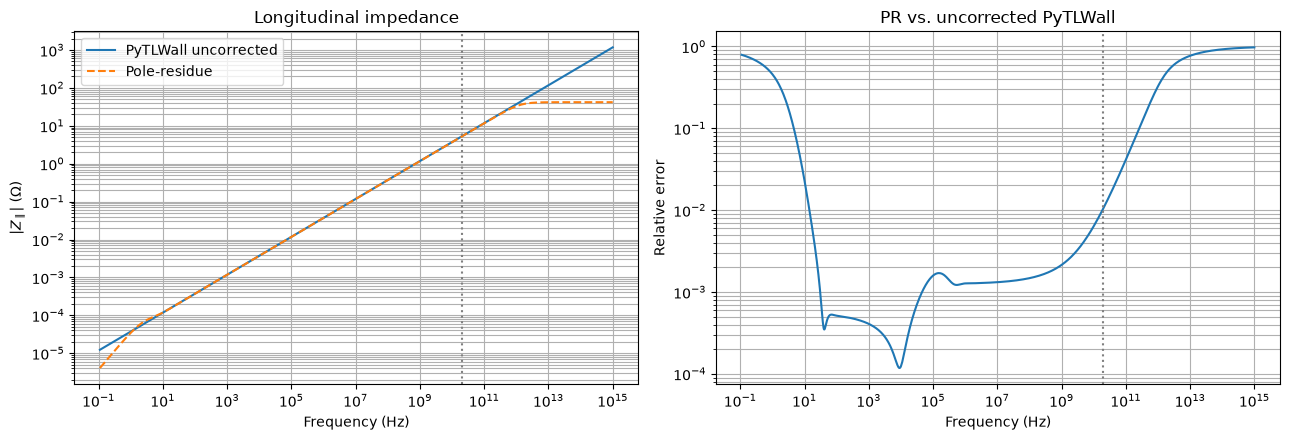

In [84]:
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Evaluate longitudinal PR impedance
# ------------------------------------------------------------

p = np.asarray(poles_long, dtype=complex)
r = np.asarray(residues_long, dtype=complex)
D = complex(direct_long)

omega = 2.0 * np.pi * freq_wall
s = 1j * omega

Z_pr = D + np.sum(
    r[:, None] / (s[None, :] - p[:, None]),
    axis=0
)

# ------------------------------------------------------------
# Relative error against uncorrected PyTLWall
# ------------------------------------------------------------

rel_err_freq = (
    np.abs(Z_pr - Z_uncorr)
    / np.maximum(np.abs(Z_uncorr), 1e-30)
)

mask_20 = (freq_wall > 0) & (freq_wall <= 20e9)

print("Comparison up to 20 GHz")
print(f"Max relative error: {np.max(rel_err_freq[mask_20]):.4e}")
print(f"Median relative error: {np.median(rel_err_freq[mask_20]):.4e}")
print(f"RMS relative error: {np.sqrt(np.mean(rel_err_freq[mask_20]**2)):.4e}")

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].loglog(
    freq_wall, np.abs(Z_uncorr),
    label="PyTLWall uncorrected"
)
axes[0].loglog(
    freq_wall, np.abs(Z_pr), "--",
    label="Pole-residue"
)
axes[0].axvline(20e9, color="gray", linestyle=":")
axes[0].set_xlabel("Frequency (Hz)")
axes[0].set_ylabel(r"$|Z_\parallel|$ ($\Omega$)")
axes[0].set_title("Longitudinal impedance")
axes[0].grid(True, which="both")
axes[0].legend()

axes[1].loglog(freq_wall, rel_err_freq)
axes[1].axvline(20e9, color="gray", linestyle=":")
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("Relative error")
axes[1].set_title("PR vs. uncorrected PyTLWall")
axes[1].grid(True, which="both")

plt.tight_layout()
plt.show()

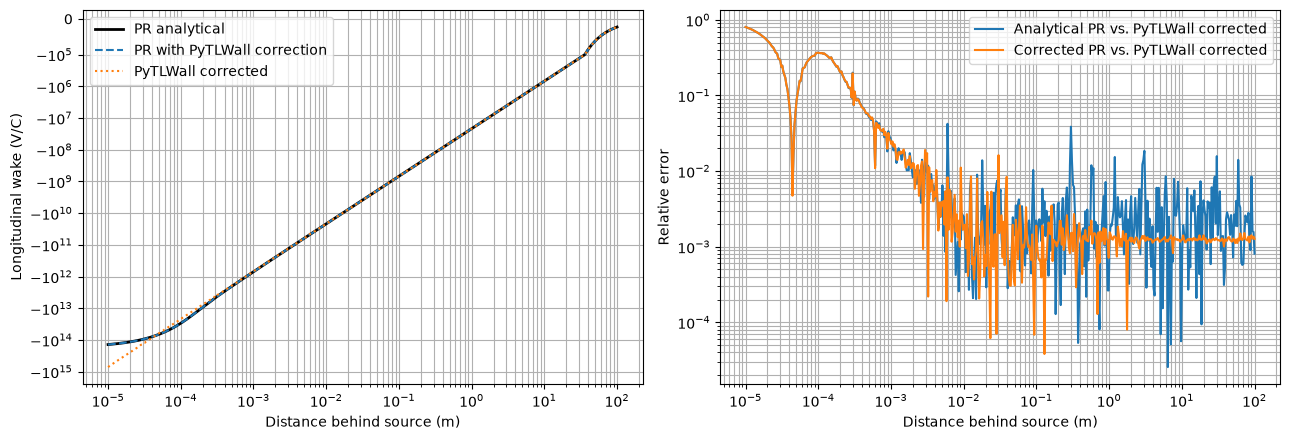

In [85]:
import iddefix

# ------------------------------------------------------------
# Apply PyTLWall correction to the PR impedance
# ------------------------------------------------------------

Z_pr_corr = Z_pr / corr

# Use the full frequency range
freq_full, Z_pr_corr_full = prepare_spectrum(
    freq_wall,
    Z_pr_corr,
    freq_wall[-1]
)

# ------------------------------------------------------------
# Transform corrected PR impedance using NEFFINT
# ------------------------------------------------------------

t_pr_corr, h_pr_corr = iddefix.compute_ineffint(
    freq_full,
    Z_pr_corr_full,
    times=t_test,
    plane="longitudinal",
    adaptative=False,
)

h_pr_corr = np.asarray(h_pr_corr)

# Previously calculated corrected PyTLWall wake
h_pytl_corr = wake_neffint["Corrected, full"]

# Analytical PR wake
h_pr_analytic = np.sum(
    np.real(r)[:, None]
    * np.exp(np.real(p)[:, None] * t_test[None, :]),
    axis=0
)

# ------------------------------------------------------------
# Compare wake functions
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].semilogx(
    z_test, h_pr_analytic,
    "k-", linewidth=2,
    label="PR analytical"
)

axes[0].semilogx(
    z_test, h_pr_corr,
    "--", label="PR with PyTLWall correction"
)

axes[0].semilogx(
    z_test, h_pytl_corr,
    ":", label="PyTLWall corrected"
)

axes[0].set_xlabel("Distance behind source (m)")
axes[0].set_ylabel("Longitudinal wake (V/C)")
axes[0].set_yscale("symlog", linthresh=1e5)
axes[0].grid(True, which="both")
axes[0].legend()

err_pr_corr = (
    np.abs(h_pr_corr - h_pytl_corr)
    / np.maximum(np.abs(h_pytl_corr), 1e-30)
)

err_pr_uncorr = (
    np.abs(h_pr_analytic - h_pytl_corr)
    / np.maximum(np.abs(h_pytl_corr), 1e-30)
)

axes[1].loglog(
    z_test, err_pr_uncorr,
    label="Analytical PR vs. PyTLWall corrected"
)

axes[1].loglog(
    z_test, err_pr_corr,
    label="Corrected PR vs. PyTLWall corrected"
)

axes[1].set_xlabel("Distance behind source (m)")
axes[1].set_ylabel("Relative error")
axes[1].grid(True, which="both")
axes[1].legend()

plt.tight_layout()
plt.show()

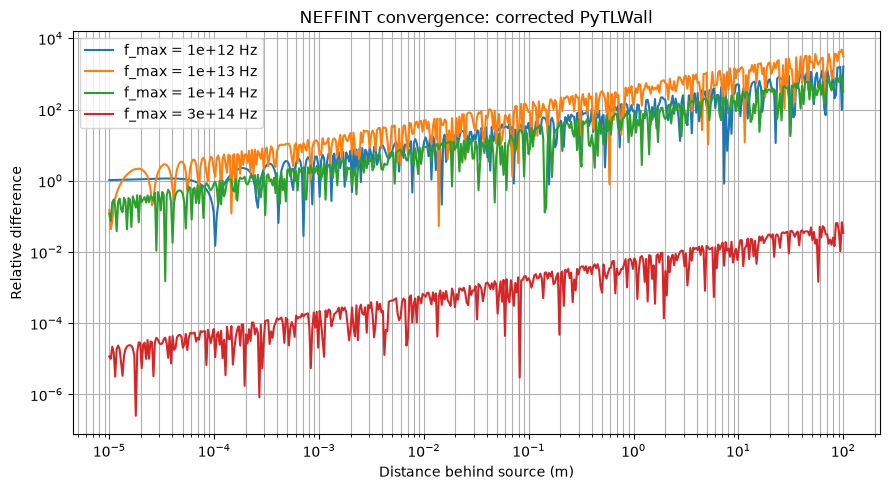

In [86]:
# ------------------------------------------------------------
# NEFFINT convergence with frequency cutoff
# ------------------------------------------------------------

cutoffs = [1e12, 1e13, 1e14, 3e14, 1e15]

wake_convergence = {}

for cutoff in cutoffs:

    freq_case, Z_case = prepare_spectrum(
        freq_wall,
        Z_corr,
        cutoff
    )

    _, wake = iddefix.compute_ineffint(
        freq_case,
        Z_case,
        times=t_test,
        plane="longitudinal",
        adaptative=False,
    )

    wake_convergence[cutoff] = np.asarray(wake)

# Reference: largest cutoff
h_reference = wake_convergence[cutoffs[-1]]

fig, ax = plt.subplots(figsize=(9, 5))

for cutoff in cutoffs[:-1]:

    error = (
        np.abs(wake_convergence[cutoff] - h_reference)
        / np.maximum(np.abs(h_reference), 1e-30)
    )

    ax.loglog(
        z_test,
        error,
        label=f"f_max = {cutoff:.0e} Hz"
    )

ax.set_xlabel("Distance behind source (m)")
ax.set_ylabel("Relative difference")
ax.set_title("NEFFINT convergence: corrected PyTLWall")
ax.grid(True, which="both")
ax.legend()

plt.tight_layout()
plt.show()

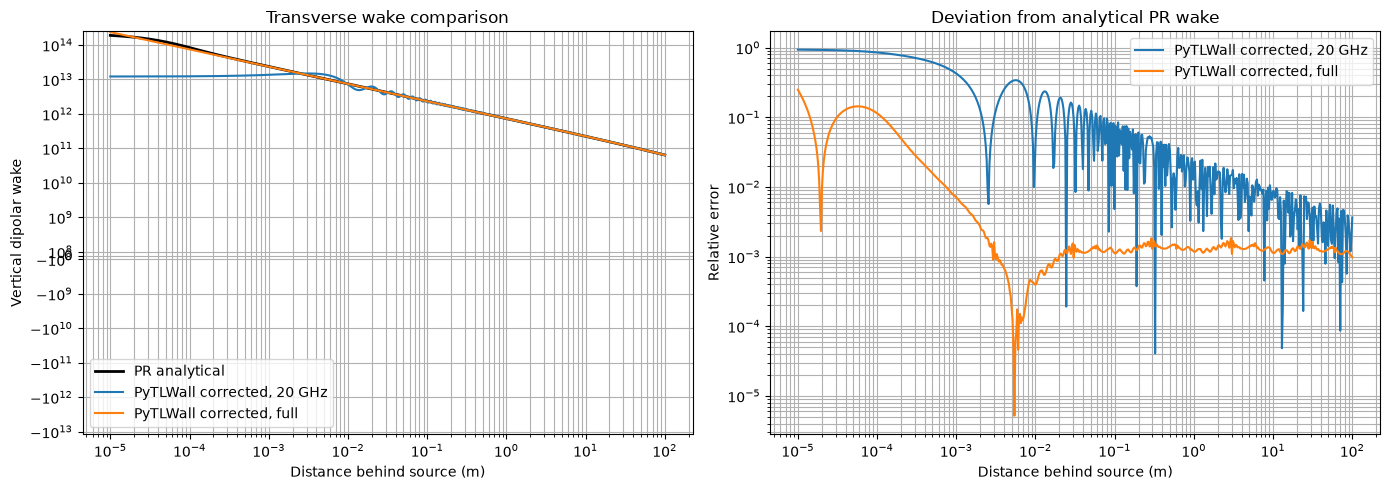

In [90]:
import numpy as np
import matplotlib.pyplot as plt
import iddefix

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

Y = 0.856
f_cut = 20e9

freq = np.asarray(freq_wall)

# Corrected PyTLWall transverse impedance
Z_trans_corr = Y * np.asarray(
    sps_wall.calc_ZTrans(), dtype=complex
).ravel()

# Convert to ordinary causal Fourier convention
Z_base_corr = Z_trans_corr / 1j

# ------------------------------------------------------------
# Numerical inverse Fourier transforms
# ------------------------------------------------------------

wake_pytl_trans = {}

for name, cutoff in {
    "PyTLWall corrected, 20 GHz": f_cut,
    "PyTLWall corrected, full": freq[-1],
}.items():

    mask = freq <= cutoff

    f_case = freq[mask]
    Z_case = Z_base_corr[mask]

    # Interpolate exact cutoff value if necessary
    if cutoff < freq[-1] and f_case[-1] < cutoff:
        Z_end = (
            np.interp(cutoff, freq, Z_base_corr.real)
            + 1j * np.interp(cutoff, freq, Z_base_corr.imag)
        )
        f_case = np.r_[f_case, cutoff]
        Z_case = np.r_[Z_case, Z_end]

    # Low-frequency endpoint approximation
    # Use the first available PyTLWall sample at f = 0
    f_case = np.r_[0.0, f_case]
    Z_case = np.r_[Z_case[0], Z_case]

    _, wake = iddefix.compute_ineffint(
        f_case,
        Z_case,
        times=t_trans,
        plane="longitudinal",
        adaptative=False
    )

    wake_pytl_trans[name] = np.asarray(wake)

# ------------------------------------------------------------
# Analytical PR wake
# ------------------------------------------------------------

p = np.asarray(p_trans_red, dtype=complex)
r = np.asarray(r_trans_red, dtype=complex)

h_pr = Y * np.real(np.sum(
    r[:, None] * np.exp(p[:, None] * t_trans[None, :]),
    axis=0
))

# ------------------------------------------------------------
# Comparison
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    z_trans, h_pr,
    "k-", linewidth=2,
    label="PR analytical"
)

for name, wake in wake_pytl_trans.items():
    axes[0].plot(
        z_trans, wake,
        label=name
    )

axes[0].set_xscale("log")
axes[0].set_yscale("symlog", linthresh=1e9)
axes[0].set_xlabel("Distance behind source (m)")
axes[0].set_ylabel("Vertical dipolar wake")
axes[0].set_title("Transverse wake comparison")
axes[0].grid(True, which="both")
axes[0].legend()

for name, wake in wake_pytl_trans.items():

    error = (
        np.abs(wake - h_pr)
        / np.maximum(np.abs(h_pr), 1e-30)
    )

    axes[1].loglog(
        z_trans, error,
        label=name
    )

axes[1].set_xlabel("Distance behind source (m)")
axes[1].set_ylabel("Relative error")
axes[1].set_title("Deviation from analytical PR wake")
axes[1].grid(True, which="both")
axes[1].legend()

plt.tight_layout()
plt.show()